# F gate and P gate analysis notebook

This notebook conducts all analyses and figure generation for the dCas9*:PhlF and PhlF-driven NOT gates (F and P gates) in the manuscript "Quantitative measurement of synthetic repression curves reveals design challenges for genetic circuit engineering under growth arrest" by Marken JP et al. (2026).

Because the raw fcs data files are large and unwieldy to process, these notebooks read, process, and compress the fcs files and then convert them to a pickle object that is saved in the folder 'pickles'. When running the notebook in the future, one can skip the time-consuming fcs extraction and processing sections and go directly to the unpickling section to proceed with the downstream analysis. The same procedure is applied to the MCMC parameter estimation, where outputs from the MCMC runs are saved externally in a directory called 'MCMC_outputs' as pickle objects which are then loaded in for downstream analysis.

Note that this notebook assumes that folders called 'figs', 'pickles', and 'MCMC_outputs' are present in the same directory as this notebook, and that the raw fcs data files are stored in the same directory as this notebook following the naming provided in the Zenodo repository where they are housed (doi: 10.5281/zenodo.18415279 ).

Throughout this notebook, the fusion gates ('F' in the manuscript) are referred to as 'DP'. The active growth conditions are referred to by the keyword 'M9' (for the M9CA growth media) and the growth arrest conditions are referred to by the kewyrod 'CL' (for Carbon Limitation). Similarly, each of the gates are referred to by numbered guide RNA values (g1, g2, etc.) which can be converted to the gate nomenclature presented in the manuscript by looking at the dictionary that relates each 'gi' label to the midpoint of the dCas9 binding footprint (this dictionary is called PAM_dict_DP for the fusion gates and PAM_dict_P for the PhlF gates).

## Imports

In [1]:
import os
import pickle
import pandas as pd
import numpy as np
import collections
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.backends.backend_pdf import PdfPages
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from cycler import cycler
import numpy as np
import pylab
import FlowCal
import copy
from matplotlib.lines import Line2D
import warnings
import corner
from matplotlib.colors import ListedColormap

import emcee

# Default parameters for plotting
sns.set_context("talk", font_scale=1, rc={"lines.linewidth": 2.0, 'lines.markersize': 5})
sns.set_style("ticks")
sns.set_style({"xtick.direction": "in","ytick.direction": "in"})
mpl.rc('axes', prop_cycle=(cycler('color', ['r', 'k', 'b','g','y','m','c']) ))
mpl.rc('text', usetex=False)
#mpl.rc('font',**{'family':'sans-serif','sans-serif':['HelveticaNeueThin']})
#plt.tick_params(top=False, bottom=False, right=False, left=False)
tw = 1.5
sns.set_style({"xtick.major.size": 6, "ytick.major.size": 6,
               "xtick.minor.size": 4, "ytick.minor.size": 4,
               'axes.labelsize': 24,
               'xtick.major.width': tw, 'xtick.minor.width': tw,
               'ytick.major.width': tw, 'ytick.minor.width': tw})

mpl.rc('xtick', labelsize=18) 
mpl.rc('ytick', labelsize=18)
mpl.rc('axes', linewidth=1.75)
plt.gcf().subplots_adjust(bottom=0.15)
sns.set_style({'axes.labelsize': 24, 'axes.titlesize': 24})

# %matplotlib inline

# warnings.filterwarnings(action='once')
warnings.filterwarnings('ignore')

<Figure size 640x480 with 0 Axes>

## Helper Functions

In [2]:
# gRNA properties

# This is a new PAM dict for the DP strains.
# It uses the midpoint of the combined dCas9:PhlF footprint (66bp), which is
# the 3rd bp after/before the side of the PhlO site closest to the PAM.
# Positions are given in absolute values, as in 0 is immediately before +1.
# To convert to genomic position, subtract 1 from all negative values.
PAM_dict_DP = {'g1': -49,
               'g2': -33,
               'g3': 12,
               'g5': 36,
               'g16': 94,
               'g17': 115,
              }

# This is a new PAM dict for the P strains. It uses the central bp of
# the 30bp PhlO site, which I take to be the 16th position.
# (this is the 15th position when it is PhlOrc)
# Positions are given in absolute values, as in 0 is immediately before +1.
# To convert to genomic position, subtract 1 from all negative values.
PAM_dict_P = {'g1': -31,
              'g2': -51,
              'g3': 30,
              'g5': 18,
              'g16': 112,
              'g17': 97,
             }

strand_dict = {'g1': 'right',
               'g2': 'left',
               'g3': 'right',
               'g4': 'right',
               'g5': 'left',
               'g6': 'right',
               'g8': 'right',
               'g9': 'left',
               'g10': 'left',
               'g11': 'right',
               'g12': 'right',
               'g13': 'left',
               'g15': 'left',
               'g16': 'right',
               'g17': 'left',
              }

def strand_to_footprint(PAM, strand):
    '''
    PAM is an integer.
    strand is a string that is 'right' or 'left'.
    '''
    if strand == 'right':
        rightwindow = PAM + 8 # 9bp overhang beyond gRNA. N in NGG already included.
        leftwindow = PAM - 20 - 1 #1bp overhang beyond gRNA.
    elif strand == 'left':
        rightwindow = PAM + 20 + 1
        leftwindow = PAM - 8
    else:
        raise('Problem with strand')
    return leftwindow, rightwindow

In [3]:
# Helper functions

def Hill_rep_fun(x, params):
    '''
    Hill repression function that returns y for input x.
    Written in numerically stable form.
    '''
    b, a, K, n = params
    return b / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a

def Hill_act_fun(x, params):
    '''
    Hill activation function that returns y for input x.
    Written in numerically stable form.
    '''
    b, a, K, n = params
    return b * np.exp(n*(np.log(x) - np.log(K))) / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a

def symlog_transform(x, linthresh=1.0):
    return np.sign(x) * (np.log1p(np.abs(x / linthresh)))
def symlog_inverse(y, linthresh=1.0):
    return np.sign(y) * linthresh * (np.expm1(np.abs(y)))

def log_lognormal(x, mu, sigma):
    '''
    Returns the log prior for a lognormal distribution.
    Takes x as input in non-log-scaled value.
    To obtain a median of M for the distribution, must input mu = ln(M).
    '''
    return -np.log(x) - np.log(sigma) - 0.5 * np.log(2 * np.pi) - ((np.log(x) - mu) ** 2) / (2 * sigma**2)


In [4]:
# functions for emcee

def log_prior(theta, prior_params):     
    '''
    Lognormal priors for all four parameters.
    '''
    b, a, K, n = theta
    b_params, a_params, K_params, n_params = prior_params
    mub, sigmab = b_params
    mua, sigmaa = a_params
    muK, sigmaK = K_params
    mun, sigman = n_params
    
    # log-normal prior on beta
    logbprior = -np.log(b) - np.log(sigmab) - 0.5 * np.log(2 * np.pi) - ((np.log(b) - mub) ** 2) / (2 * sigmab**2)
    # log-normal prior on alpha
    logaprior = -np.log(a) - np.log(sigmaa) - 0.5 * np.log(2 * np.pi) - ((np.log(a) - mua) ** 2) / (2 * sigmaa**2)
    # log-normal prior on K
    logKprior = -np.log(K) - np.log(sigmaK) - 0.5 * np.log(2 * np.pi) - ((np.log(K) - muK) ** 2) / (2 * sigmaK**2)
    # log-normal prior on n
    lognprior =  -np.log(n) - np.log(sigman) - 0.5 * np.log(2 * np.pi) - ((np.log(n) - mun) ** 2) / (2 * sigman**2)
    
    return logbprior + logaprior + logKprior + lognprior

def log_likelihood(theta, x, y):
    '''
    Model is a Hill repression function, with output in ln() scale.
    This requires data, y, to also be in ln() scale.
    '''
    b, a, K, n = theta

    model = np.log(b / (1 + np.exp(n*(np.log(x) - np.log(K)))) + a) # <- this is ln(Hill rep function), written in numerically stable form
    
    cost = - np.linalg.norm(y - model) # <- Make sure the model and the data are appropriately log-transformed   
    cost_progress.append(cost)
    return cost


def log_probability(theta, x, y, prior_params):
    lp = log_prior(theta, prior_params)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(theta, x, y)

In [44]:
def make_2D_plot(fcs_dict_ls, media, grna, rep, atcs, fill=False, savefig=False, linthresh=1, filetype='png'):
    '''
    Inputs:
        fcs_dict_ls: list of gated fcs dictionaries arranged by replicate
        media: string, 'M9' or 'CL'
        grna: string, 'gN' where N is an integer
        rep: integer, 1,2,3
        atcs: list of strings of labels of atc concentrations (ng/mL).
              First entry is 'Blank'.
        fill: Boolean to determine if margin KDEs are filled or not.
    '''
    cmap = plt.get_cmap('viridis',len(atcs)-1)
    
    fcs_gated_dict = fcs_dict_ls[rep-1]
    
    plt.figure(figsize=(4,4))
    g = sns.JointGrid(space=0)

    med_gfps = np.empty(len(atcs))
    med_rfps = np.empty(len(atcs))
    for n in range(len(atcs)):
        fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[n]]
        gfps = np.array(fcs[:,5])
        rfps = np.array(fcs[:,7])
        
        # calculate median gfp, rfp values for later
        med_gfps[n] = np.median(gfps)
        med_rfps[n] = np.median(rfps)
    
        # transform gfp, rfp values into symlog space
        symlog_gfps = symlog_transform(gfps, linthresh=linthresh)
        symlog_rfps = symlog_transform(rfps, linthresh=linthresh)
    
        # start filling plots
        if n==0:
            color = 'grey'
        else:
            color = cmap(n-1)
            
        sns.scatterplot(x=rfps, y=gfps, color=color,
                        s=2, alpha=0.1, ax=g.ax_joint,
                        legend=False)
        
        rfp_kde = stats.gaussian_kde(symlog_rfps)
        rfp_xrange = np.linspace(min(symlog_rfps), max(symlog_rfps), 1000)
        rfp_kde_y = rfp_kde(rfp_xrange)
        g.ax_marg_x.plot(symlog_inverse(rfp_xrange, linthresh=linthresh), rfp_kde_y, c=color)
        if fill:
            g.ax_marg_x.fill_between(symlog_inverse(rfp_xrange, linthresh=linthresh), np.zeros(len(rfp_kde_y)), rfp_kde_y, color=color, alpha=0.2)
        
        gfp_kde = stats.gaussian_kde(symlog_gfps)
        gfp_xrange = np.linspace(min(symlog_gfps), max(symlog_gfps), 1000)
        gfp_kde_y = gfp_kde(gfp_xrange)
        g.ax_marg_y.plot(gfp_kde_y, symlog_inverse(gfp_xrange, linthresh=linthresh), c=color)
        if fill:
            g.ax_marg_y.fill_between(gfp_kde_y, symlog_inverse(gfp_xrange, linthresh=linthresh), np.zeros(len(gfp_kde_y)), color=color, alpha=0.2)
    
    # plot medians
    g.ax_joint.scatter(med_rfps[0], med_gfps[0], c='k')
    g.ax_joint.scatter(med_rfps[1:], med_gfps[1:], c='r')
    
    g.ax_joint.set_xscale('symlog', linthresh=linthresh)
    g.ax_joint.set_yscale('log')
    g.ax_joint.axvspan(-linthresh, linthresh, facecolor='grey', alpha=0.1, edgecolor=None)
    g.ax_marg_x.axvspan(-linthresh, linthresh, facecolor='grey', alpha=0.1, edgecolor=None)
    g.ax_joint.set_ylim((1e0,5e6))
    g.ax_joint.set_xlim((-2e1,2e3))
    # g.ax_joint.set_ylim(bottom=1e0)
    g.ax_joint.set_xlabel('Repressor:RFP')
    g.ax_joint.set_ylabel('GFP')
    # g.ax_marg_x.set_title(grna + ', ' + media + ', Rep '+str(rep))
    print(grna + ', ' + media + ', Rep '+str(rep))
    
    if savefig:
        filename = savefig + '_' + grna + '_' + media + '_rep' + str(rep) + '_2Dplot.'+ filetype
        plt.savefig('./figs/2Dplots/'+filename, bbox_inches='tight')

    plt.show()

## Import and Pickle Data (Skip this section if you've already run it once)


### Replicate 1

In [4]:
# import FCS data

fileprefix = '../20250501/'

fileext = '.fcs'

m9beads = FlowCal.io.FCSData(fileprefix + '07-Beads-H12' + fileext)

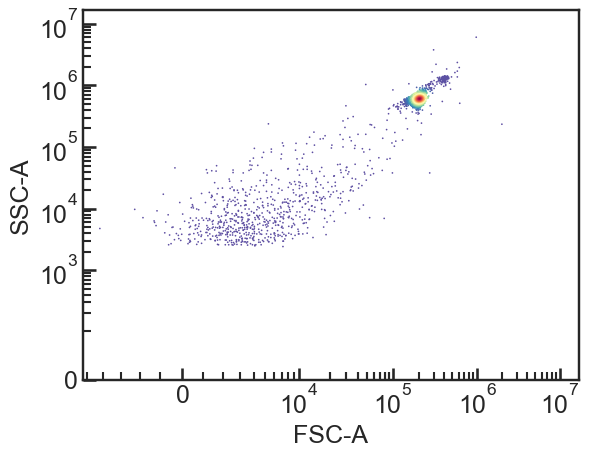

In [5]:
# Plot out beads to get cutoff thresholds
FlowCal.plot.density2d(m9beads,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')


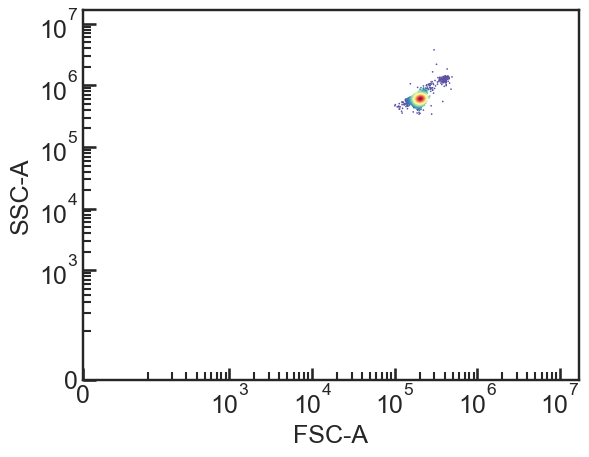

In [6]:
# gate on FSC-A and SSC-A
m9beads_gated = m9beads[(m9beads[:,1] > 1e5) &
                    (m9beads[:,1] < 5e5) &
                    (m9beads[:,3] > 3e5)]
# beads_gated = beads_gated[(beads_gated[:,1] < 8e5) & (beads_gated[:,3] < 3e6)]

FlowCal.plot.density2d(m9beads_gated,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')


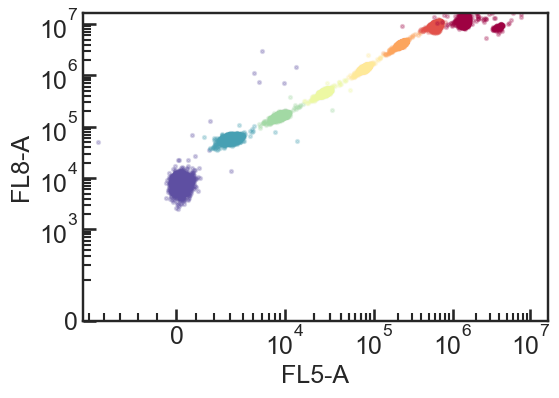

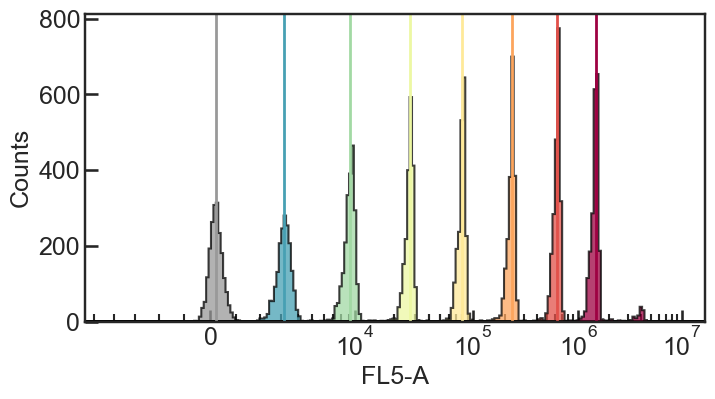

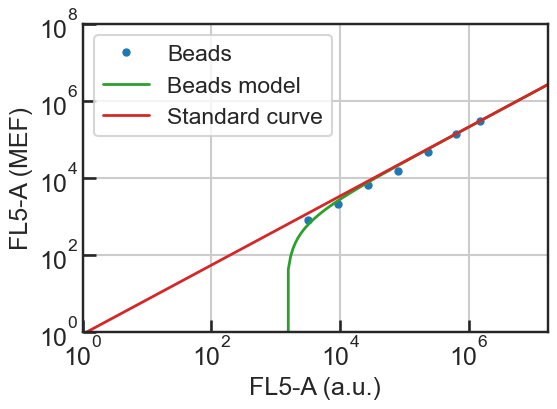

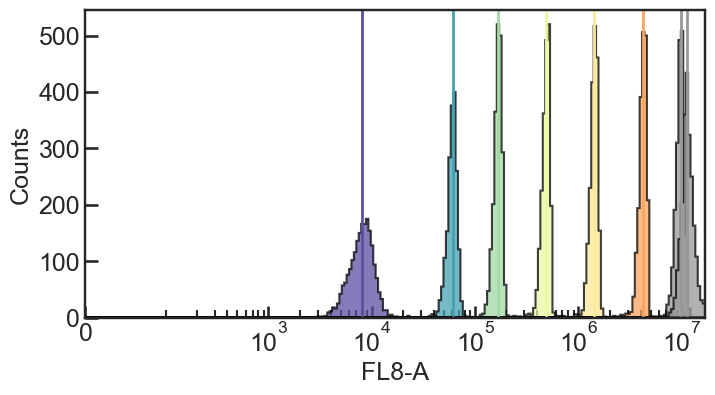

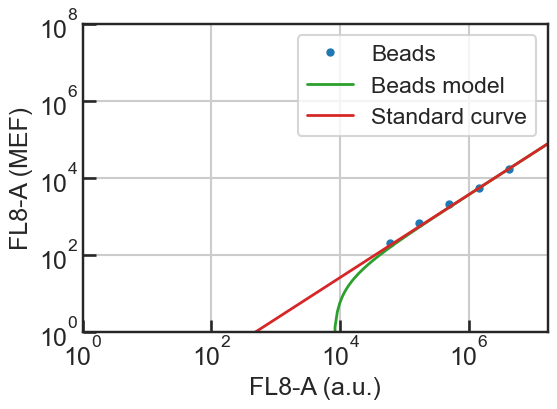

In [7]:
mefl_vals = np.array([0,771,2106,6262,15183,45292,136258,291042])
# meptr_vals = np.array([0,205,643,2021,5278,17018,62451,198933])

# use this because RFP gain is so high that the brightest bead subpopulations overflow.
meptr_vals_low = np.array([0,205,643,2021,5278,17018,np.nan,np.nan]) 

mef_vals = np.array([mefl_vals, meptr_vals_low])

to_mef_m9 = FlowCal.mef.get_transform_fxn(
    m9beads_gated,
    mef_values = mef_vals,
    mef_channels=['FL5-A','FL8-A'],
    plot=True,
)


In [8]:
fcs_dict = dict()

plates = ['06','09','10','11']
medias = ['M9_P','M9_D','CL_P','Well']

rows = ['A','B','C','D','E','F']

grnas = ['g1','g2','g3','g5','g16','g17']
cols = [str(i) for i in range(1,13)]

atcs_cl = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9 = ['Blank','0','0.2','0.43','0.93','2','2.6','3.5','6.3','11.3','20','100']

for p in range(len(plates)):
    plate = plates[p]
    media = medias[p]

    if (plate=='06')|(plate=='09'):
        atcs = atcs_m9
    else:
        atcs = atcs_cl

    prefix = plate+'-'+media+'-'
    for r in range(len(rows)):
        for c in range(len(cols)):
            well = rows[r]+cols[c]
            if media=='Well':
                media = 'CL_D'
            cond = media+'_'+grnas[r]+'_'+atcs[c]
            
            fcs_dict[cond] = to_mef_m9(FlowCal.transform.to_rfi(FlowCal.io.FCSData(fileprefix + prefix + well + fileext)), channels=['FL5-A','FL8-A'])


In [9]:
# density gating

# This may take a while to run.
frac_to_keep = 0.4

fcs_gated_dict = dict()

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    
    fcs_gated = FlowCal.gate.density2d(fcs,
                                       channels=['FSC-A','SSC-A'],
                                       gate_fraction=frac_to_keep,
                                      )
    fcs_gated_dict[key] = fcs_gated

In [12]:
# pickle the resulting dictionary

with open('./pickles/250501_fcs_gated_dict.pkl', 'wb') as f:  # open a text file
    pickle.dump(fcs_gated_dict, f) # serialize the list
f.close()

### Replicate 2

In [13]:
# import FCS data

fileprefix = '../20250509/'

fileext = '.fcs'

m9beads = FlowCal.io.FCSData(fileprefix + '06-Beads-H12' + fileext)

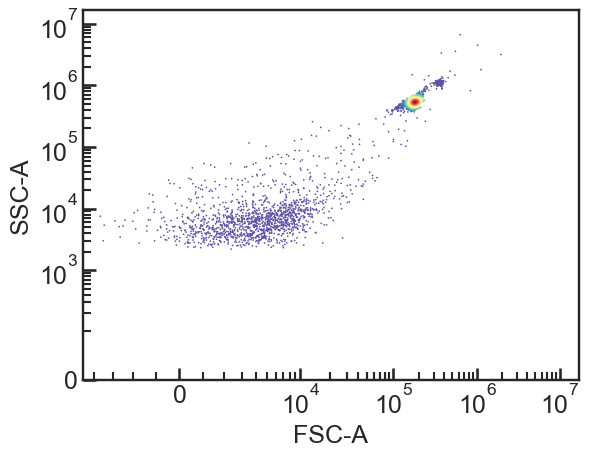

In [14]:
# Plot out beads to get cutoff thresholds
FlowCal.plot.density2d(m9beads,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')


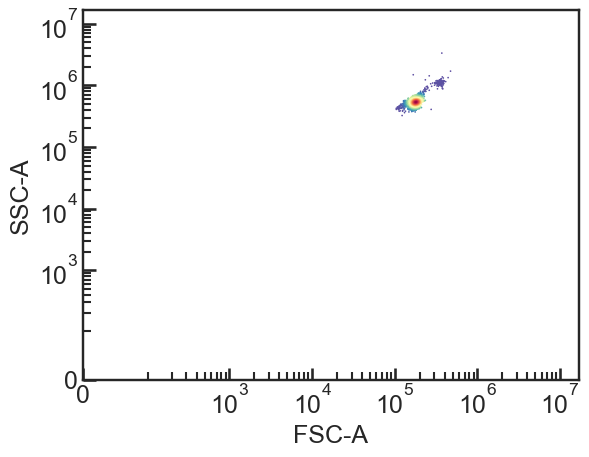

In [15]:
# gate on FSC-A and SSC-A
m9beads_gated = m9beads[(m9beads[:,1] > 1e5) &
                    (m9beads[:,1] < 5e5) &
                    (m9beads[:,3] > 3e5)]
# beads_gated = beads_gated[(beads_gated[:,1] < 8e5) & (beads_gated[:,3] < 3e6)]

FlowCal.plot.density2d(m9beads_gated,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')


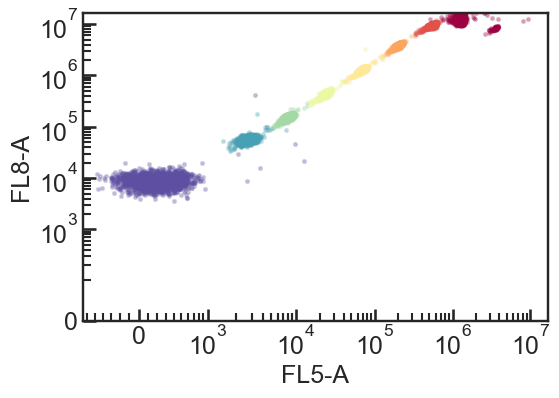

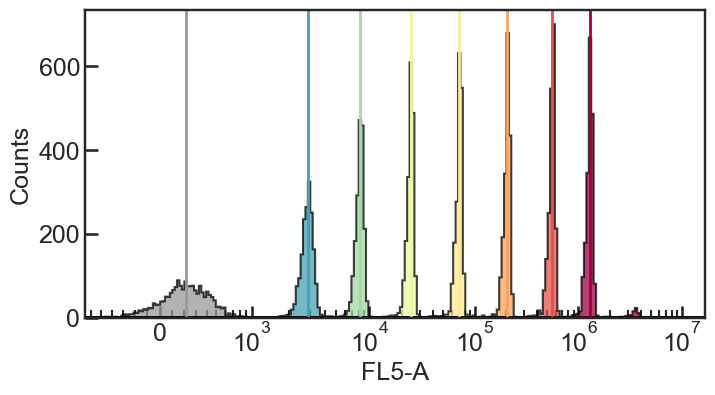

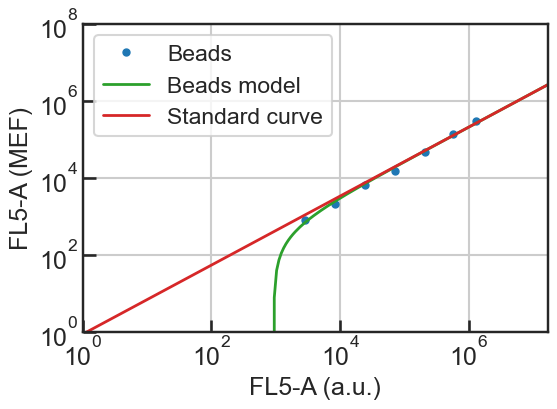

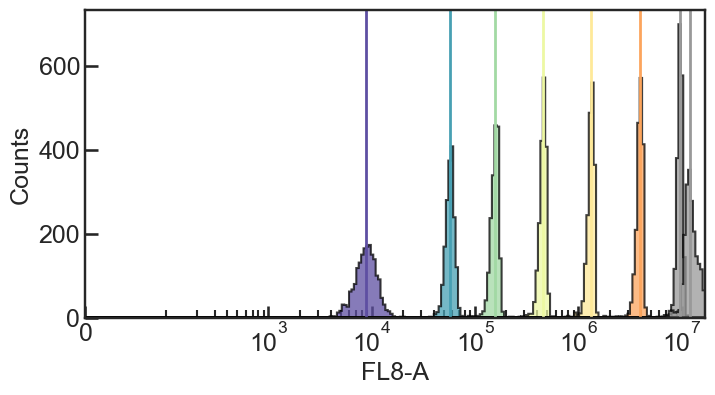

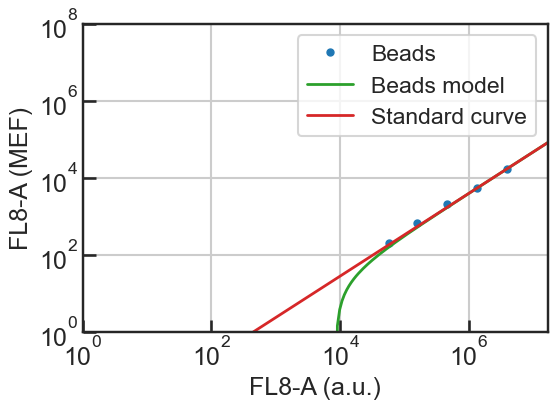

In [16]:
mefl_vals = np.array([0,771,2106,6262,15183,45292,136258,291042])
# meptr_vals = np.array([0,205,643,2021,5278,17018,62451,198933])

# use this because RFP gain is so high that the brightest bead subpopulations overflow.
meptr_vals_low = np.array([0,205,643,2021,5278,17018,np.nan,np.nan]) 

mef_vals = np.array([mefl_vals, meptr_vals_low])

to_mef_m9 = FlowCal.mef.get_transform_fxn(
    m9beads_gated,
    mef_values = mef_vals,
    mef_channels=['FL5-A','FL8-A'],
    plot=True,
)


In [17]:
fcs_dict = dict()

plates = ['08','09','10','11']
medias = ['M9_P','M9_D','CL_P','CL_D']

rows = ['A','B','C','D','E','F']

grnas = ['g1','g2','g3','g5','g16','g17']
cols = [str(i) for i in range(1,13)]

atcs_cl = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9 = ['Blank','0','0.2','0.43','0.93','2','2.6','3.5','6.3','11.3','20','100']

for p in range(len(plates)):
    plate = plates[p]
    media = medias[p]

    if (plate=='08')|(plate=='09'):
        atcs = atcs_m9
    else:
        atcs = atcs_cl

    prefix = plate+'-'+media+'-'
    for r in range(len(rows)):
        for c in range(len(cols)):
            well = rows[r]+cols[c]
            # if media=='Well':
            #     media = 'CL_D'
            cond = media+'_'+grnas[r]+'_'+atcs[c]
            
            fcs_dict[cond] = to_mef_m9(FlowCal.transform.to_rfi(FlowCal.io.FCSData(fileprefix + prefix + well + fileext)), channels=['FL5-A','FL8-A'])


In [19]:
# density gating

# This may take a while to run.
frac_to_keep = 0.4

fcs_gated_dict = dict()

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    
    fcs_gated = FlowCal.gate.density2d(fcs,
                                       channels=['FSC-A','SSC-A'],
                                       gate_fraction=frac_to_keep,
                                      )
    fcs_gated_dict[key] = fcs_gated

In [20]:
# pickle the resulting dictionary

with open('./pickles/250509_fcs_gated_dict.pkl', 'wb') as f:  # open a text file
    pickle.dump(fcs_gated_dict, f) # serialize the list
f.close()

### Replicate 3

In [21]:
# import FCS data

fileprefix = '../20250511/'

fileext = '.fcs'

m9beads = FlowCal.io.FCSData(fileprefix + '07-Beads-H12' + fileext)

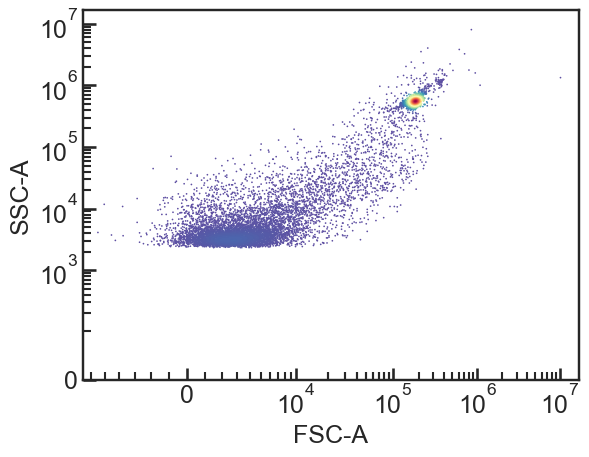

In [22]:
# Plot out beads to get cutoff thresholds
FlowCal.plot.density2d(m9beads,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')


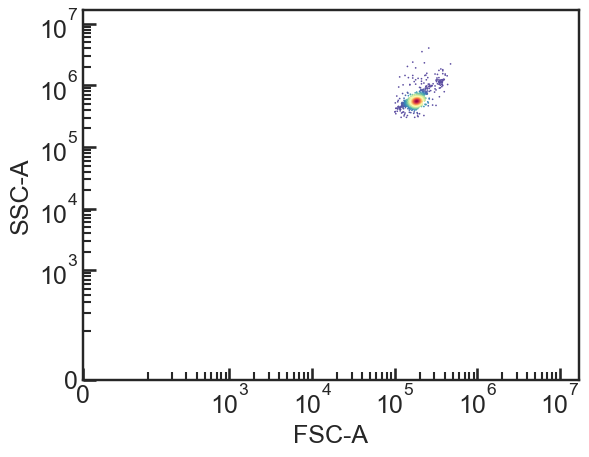

In [23]:
# gate on FSC-A and SSC-A
m9beads_gated = m9beads[(m9beads[:,1] > 1e5) &
                    (m9beads[:,1] < 5e5) &
                    (m9beads[:,3] > 3e5)]
# beads_gated = beads_gated[(beads_gated[:,1] < 8e5) & (beads_gated[:,3] < 3e6)]

FlowCal.plot.density2d(m9beads_gated,
                      channels=['FSC-A','SSC-A'],
                      mode='scatter')


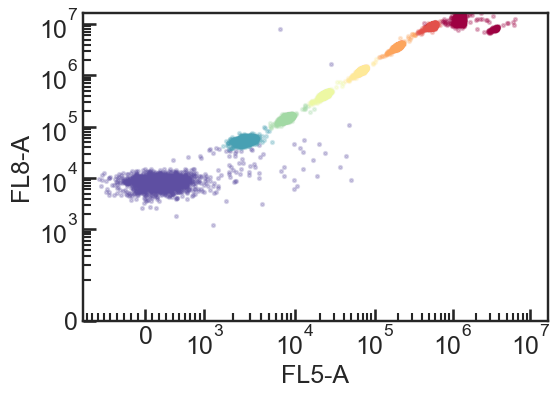

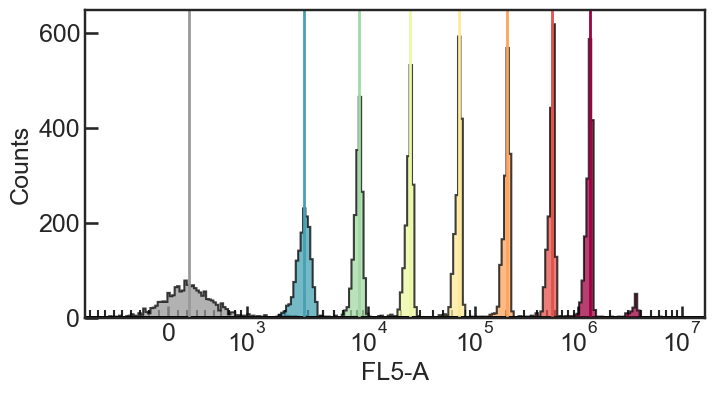

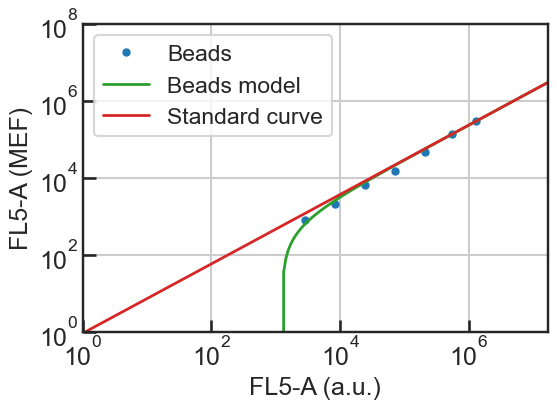

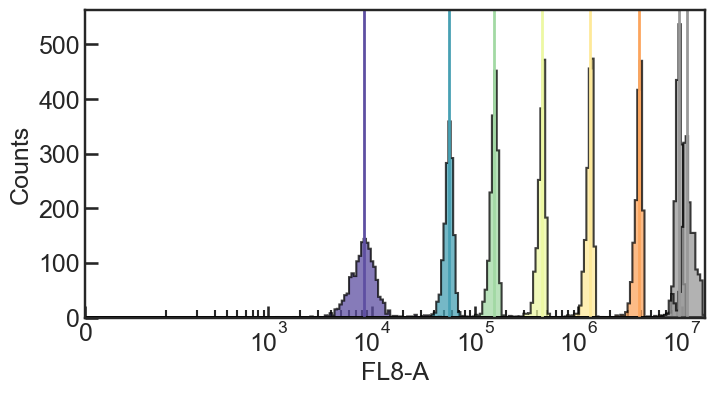

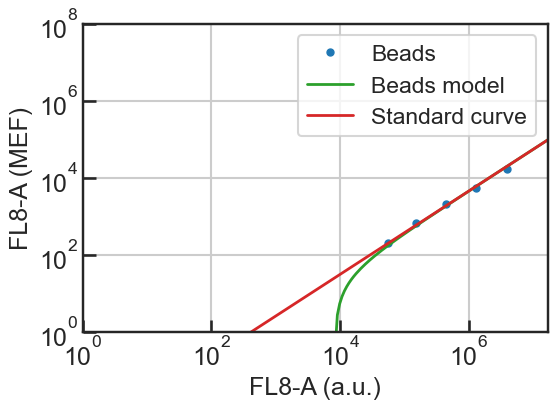

In [24]:
mefl_vals = np.array([0,771,2106,6262,15183,45292,136258,291042])
# meptr_vals = np.array([0,205,643,2021,5278,17018,62451,198933])

# use this because RFP gain is so high that the brightest bead subpopulations overflow.
meptr_vals_low = np.array([0,205,643,2021,5278,17018,np.nan,np.nan]) 

mef_vals = np.array([mefl_vals, meptr_vals_low])

to_mef_m9 = FlowCal.mef.get_transform_fxn(
    m9beads_gated,
    mef_values = mef_vals,
    mef_channels=['FL5-A','FL8-A'],
    plot=True,
)


In [25]:
fcs_dict = dict()

plates = ['08','09','10','11']
medias = ['Well','M9_D','CL_P','CL_D']

rows = ['A','B','C','D','E','F']

grnas = ['g1','g2','g3','g5','g16','g17']
cols = [str(i) for i in range(1,13)]

atcs_cl = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9 = ['Blank','0','0.2','0.43','0.93','2','2.6','3.5','6.3','11.3','20','100']

for p in range(len(plates)):
    plate = plates[p]
    media = medias[p]

    if (plate=='08')|(plate=='09'):
        atcs = atcs_m9
    else:
        atcs = atcs_cl

    prefix = plate+'-'+media+'-'
    for r in range(len(rows)):
        for c in range(len(cols)):
            well = rows[r]+cols[c]
            if media=='Well':
                media = 'M9_P'
            cond = media+'_'+grnas[r]+'_'+atcs[c]
            
            fcs_dict[cond] = to_mef_m9(FlowCal.transform.to_rfi(FlowCal.io.FCSData(fileprefix + prefix + well + fileext)), channels=['FL5-A','FL8-A'])


In [26]:
# density gating

# This may take a while to run.
frac_to_keep = 0.4

fcs_gated_dict = dict()

for key in fcs_dict.keys():
    fcs = fcs_dict[key]
    
    fcs_gated = FlowCal.gate.density2d(fcs,
                                       channels=['FSC-A','SSC-A'],
                                       gate_fraction=frac_to_keep,
                                      )
    fcs_gated_dict[key] = fcs_gated

In [27]:
# pickle the resulting dictionary

with open('./pickles/250511_fcs_gated_dict.pkl', 'wb') as f:  # open a text file
    pickle.dump(fcs_gated_dict, f) # serialize the list
f.close()

## Unpickle data



In [6]:
with open('./pickles/250501_fcs_gated_dict.pkl', 'rb') as f:
    fcs_gated_dict_1 = pickle.load(f)
f.close()

with open('./pickles/250509_fcs_gated_dict.pkl', 'rb') as f:
    fcs_gated_dict_2 = pickle.load(f)
f.close()

with open('./pickles/250511_fcs_gated_dict.pkl', 'rb') as f:
    fcs_gated_dict_3 = pickle.load(f)
f.close()

### Reformat data 

This step is done so the data for each gate library is in the same structure as was used for the D gate analysis.

In [7]:
fcs_dict_ls = [fcs_gated_dict_1,
               fcs_gated_dict_2,
               fcs_gated_dict_3,
              ]

fcs_dict_ls_P = []
fcs_dict_ls_D = []
for fcs_dict in fcs_dict_ls:
    gated_dict_P_temp = dict()
    gated_dict_D_temp = dict()
    for key in fcs_dict.keys():
        media = key[:2]
        protein = key[3]
        rest = key[4:]
        
        if protein == 'P':
            gated_dict_P_temp[media+rest] = fcs_dict[key]
        elif protein == 'D':
            gated_dict_D_temp[media+rest] = fcs_dict[key]
        else:
            print('ERROR!')

    fcs_dict_ls_P.append(gated_dict_P_temp)
    fcs_dict_ls_D.append(gated_dict_D_temp)

## Make plots

In [45]:
plot_inds_cl = [0, 0.02, 0.06, 0.2, 0.43, 0.93, 2, 6, 20, 60, 200]
plot_inds_m9 = [0, 0.2, 0.43, 0.93, 2, 2.6, 3.5, 6.3, 11.3, 20, 100]

plot_inds_ls = [[plot_inds_m9, plot_inds_cl],
                [plot_inds_m9, plot_inds_cl],
                [plot_inds_m9, plot_inds_cl],
               ]

atcs_cl = ['Blank','0','0.02','0.06','0.2','0.43','0.93','2','6','20','60','200']
atcs_m9 = ['Blank','0','0.2','0.43','0.93','2','2.6','3.5','6.3','11.3','20','100']

atcs_ls = [[atcs_m9, atcs_cl],
           [atcs_m9, atcs_cl],
           [atcs_m9, atcs_cl],
          ]

medias = ['M9', 'CL']
reps = [1,2,3]
grnas = ['g1','g2','g3','g5','g16','g17']



g1, M9, Rep 1


<Figure size 400x400 with 0 Axes>

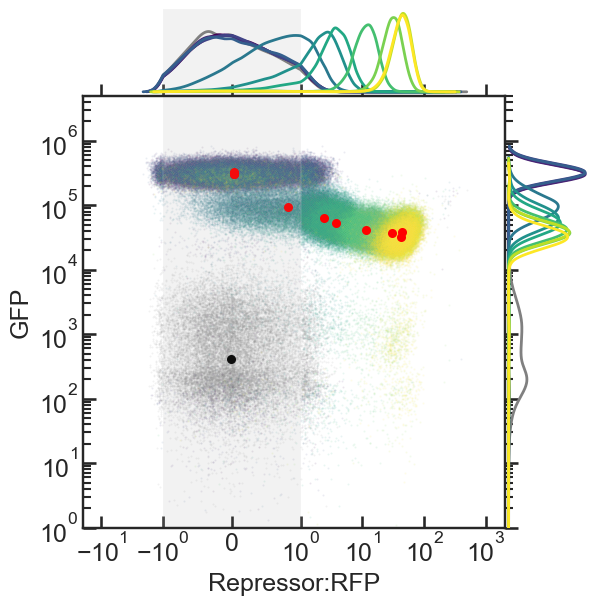

g1, M9, Rep 2


<Figure size 400x400 with 0 Axes>

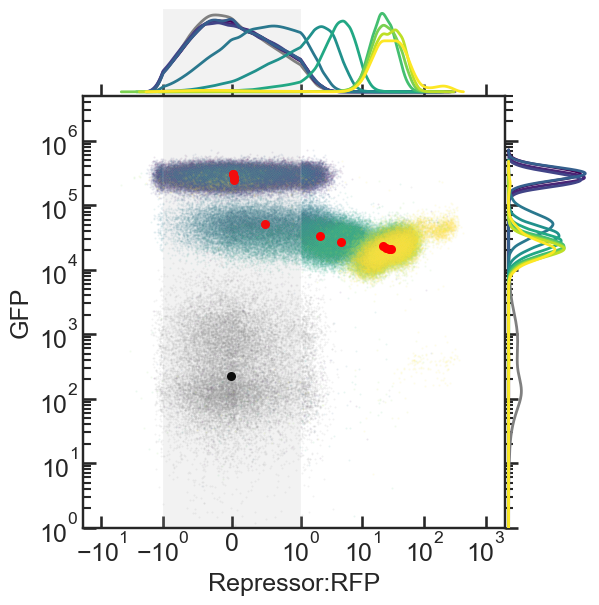

g1, M9, Rep 3


<Figure size 400x400 with 0 Axes>

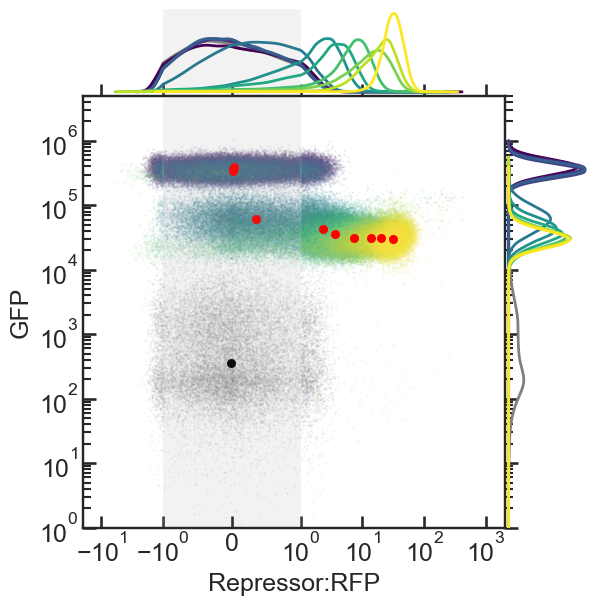

g1, CL, Rep 1


<Figure size 400x400 with 0 Axes>

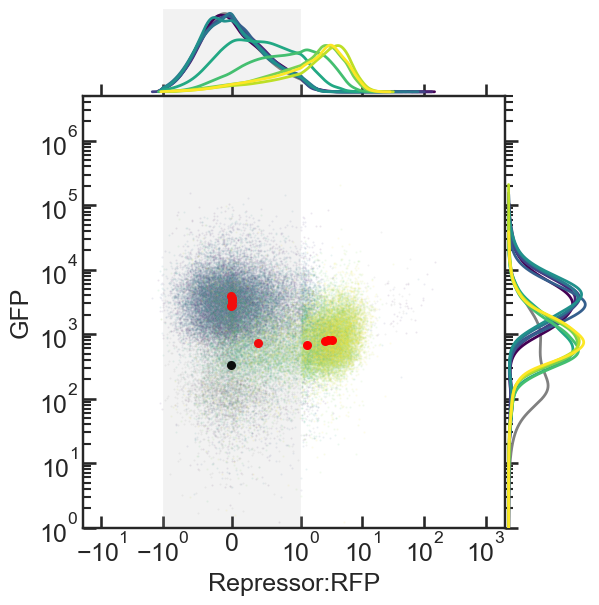

g1, CL, Rep 2


<Figure size 400x400 with 0 Axes>

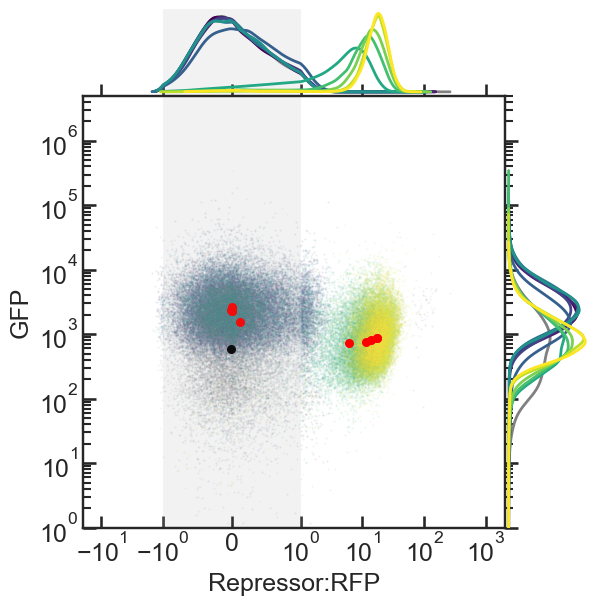

g1, CL, Rep 3


<Figure size 400x400 with 0 Axes>

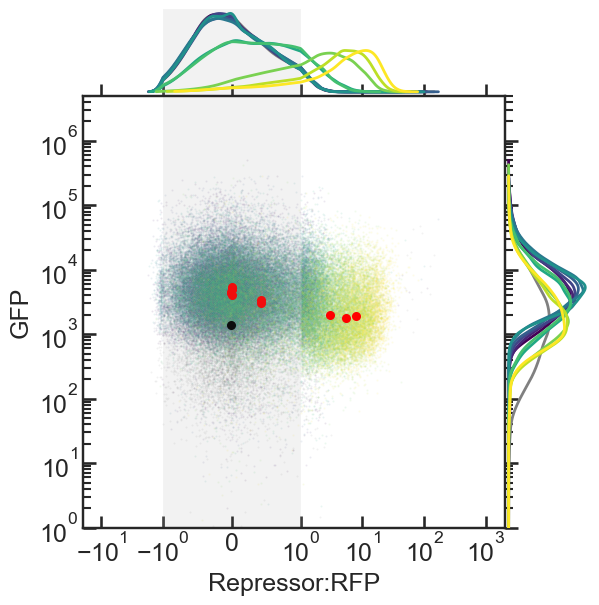

g2, M9, Rep 1


<Figure size 400x400 with 0 Axes>

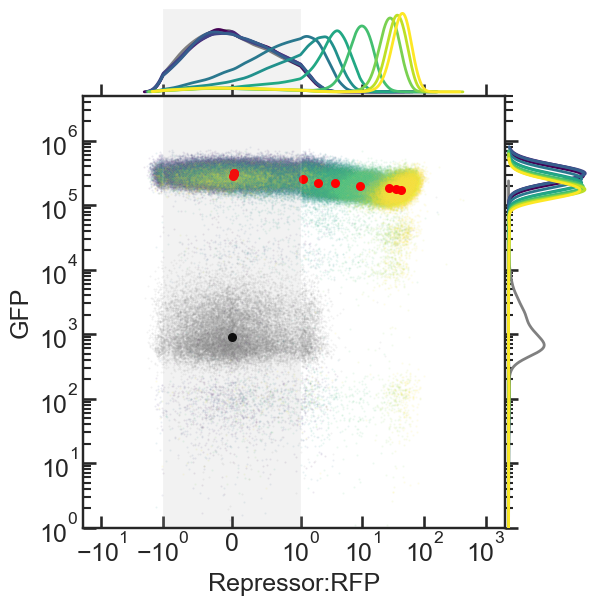

g2, M9, Rep 2


<Figure size 400x400 with 0 Axes>

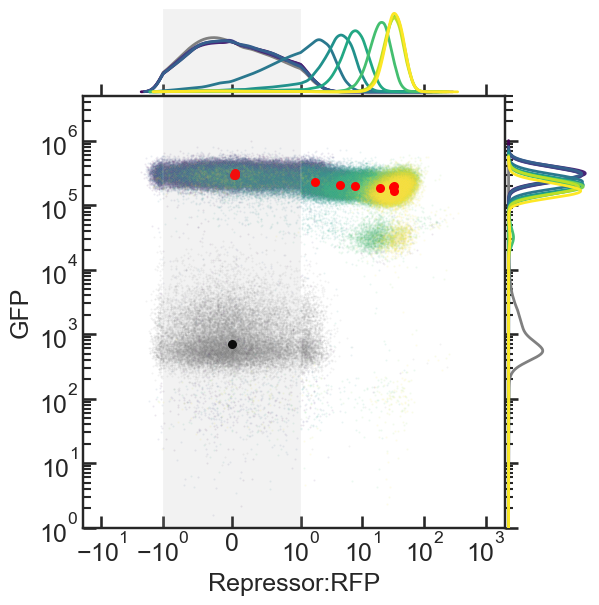

g2, M9, Rep 3


<Figure size 400x400 with 0 Axes>

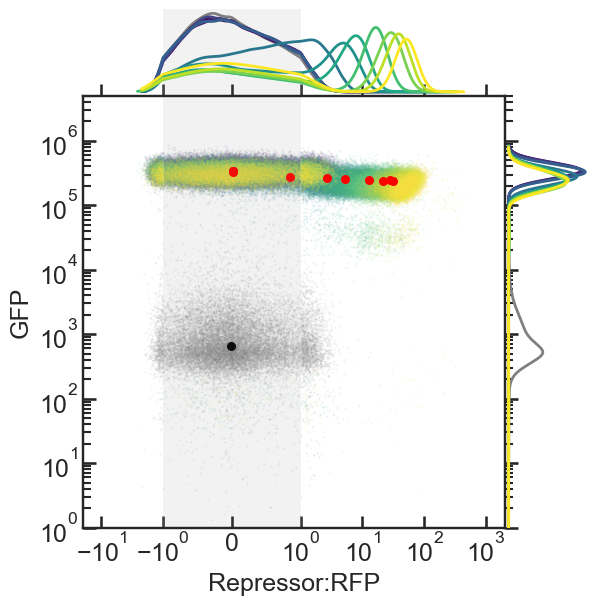

g2, CL, Rep 1


<Figure size 400x400 with 0 Axes>

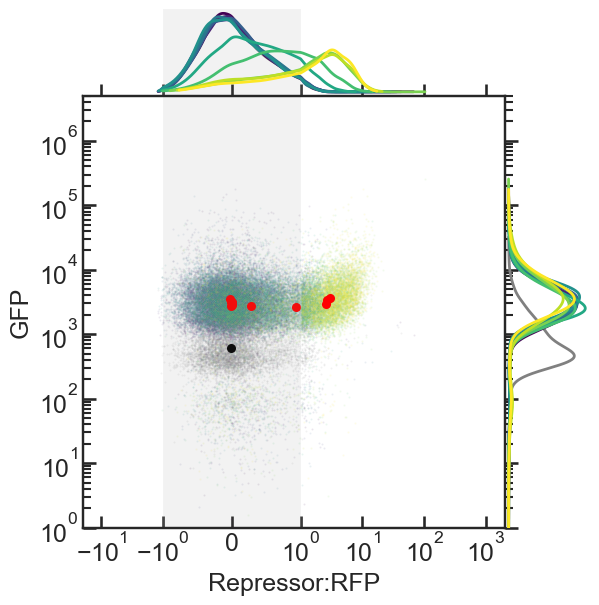

g2, CL, Rep 2


<Figure size 400x400 with 0 Axes>

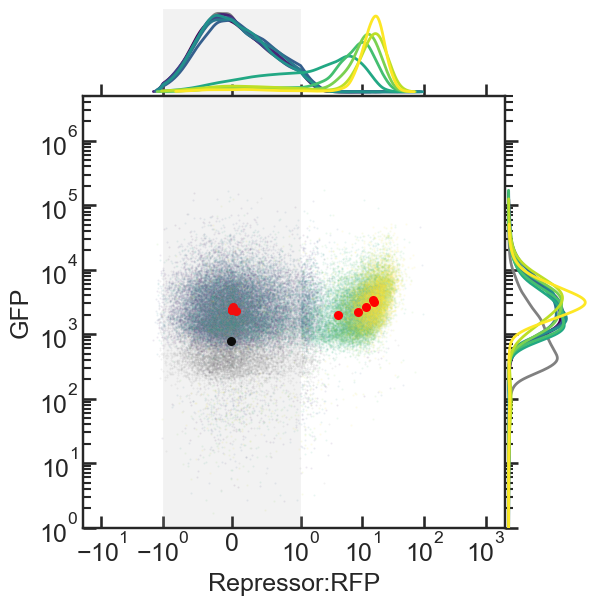

g2, CL, Rep 3


<Figure size 400x400 with 0 Axes>

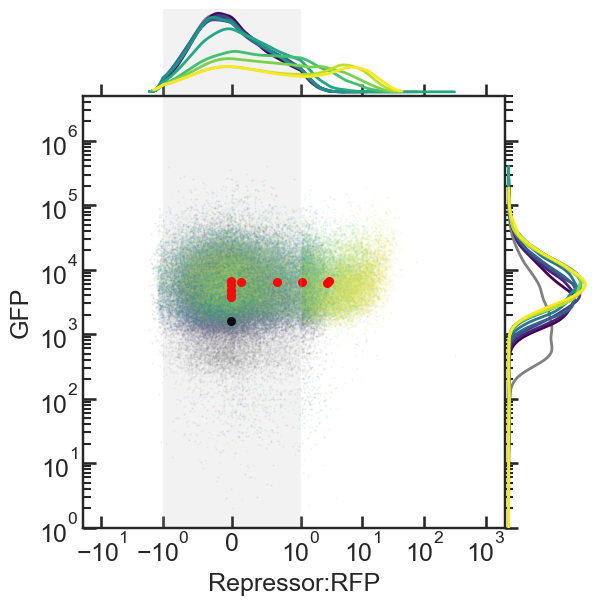

g3, M9, Rep 1


<Figure size 400x400 with 0 Axes>

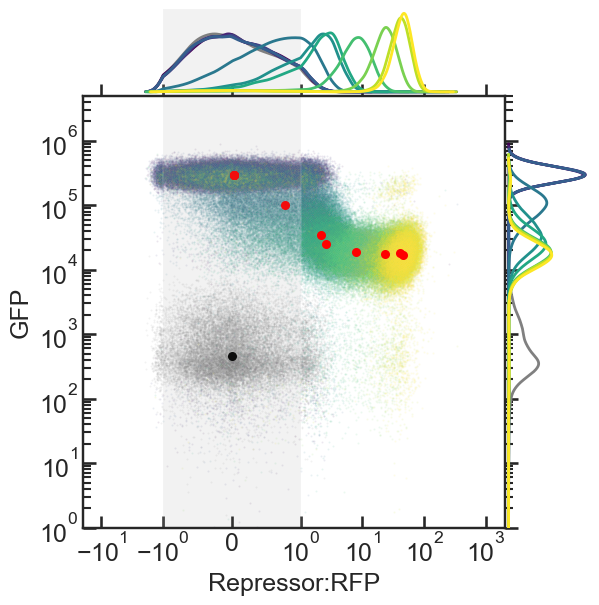

g3, M9, Rep 2


<Figure size 400x400 with 0 Axes>

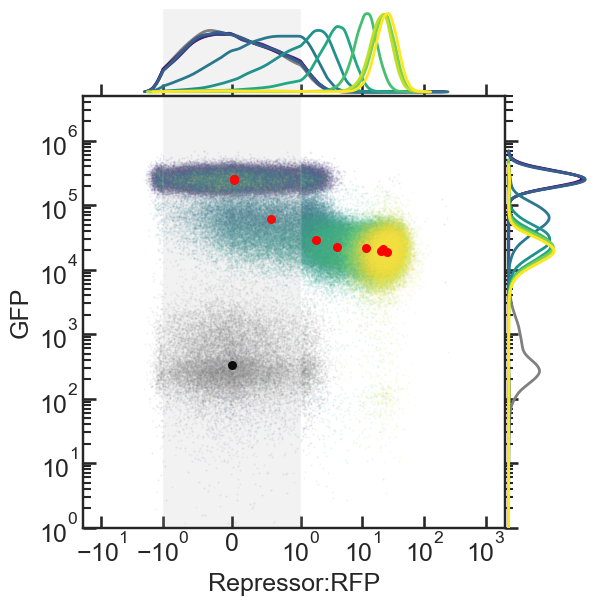

g3, M9, Rep 3


<Figure size 400x400 with 0 Axes>

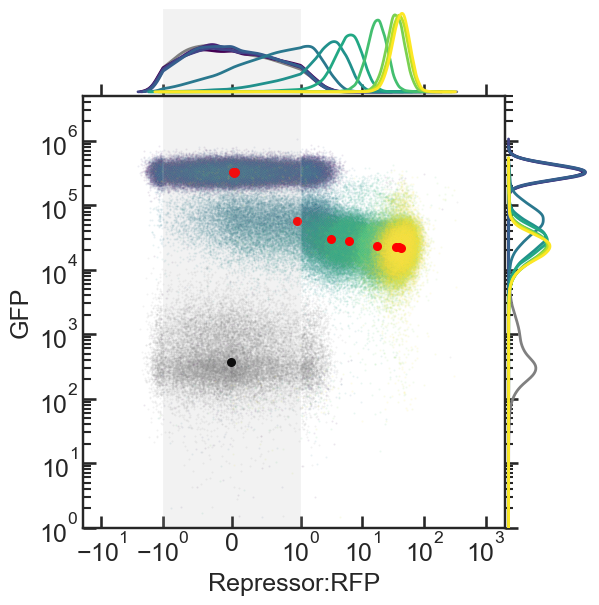

g3, CL, Rep 1


<Figure size 400x400 with 0 Axes>

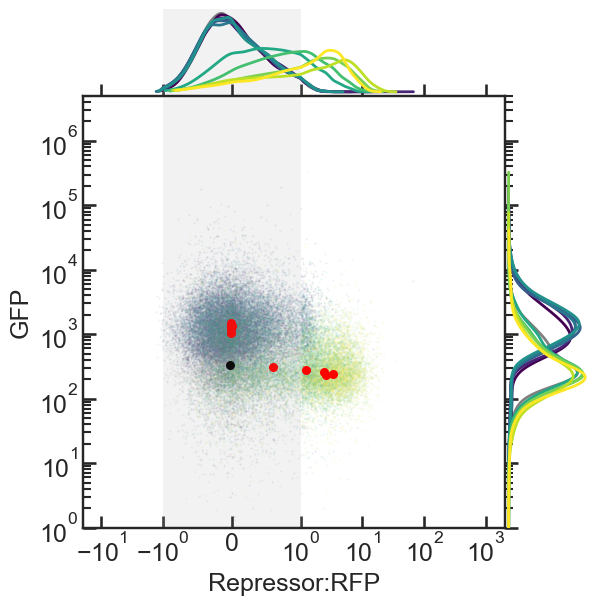

g3, CL, Rep 2


<Figure size 400x400 with 0 Axes>

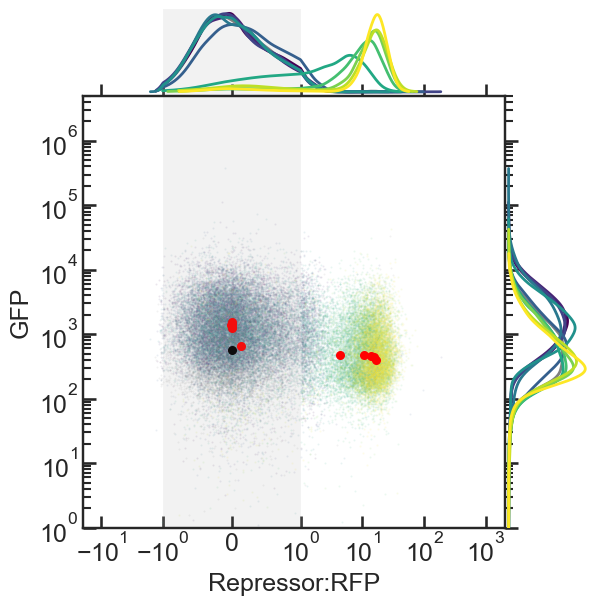

g3, CL, Rep 3


<Figure size 400x400 with 0 Axes>

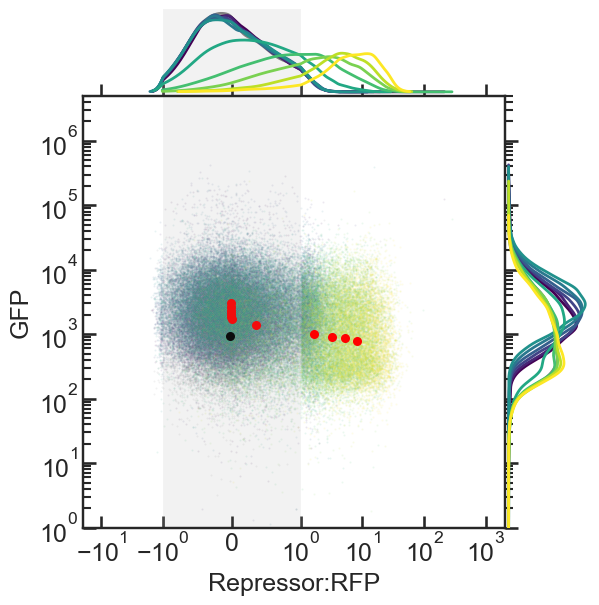

g5, M9, Rep 1


<Figure size 400x400 with 0 Axes>

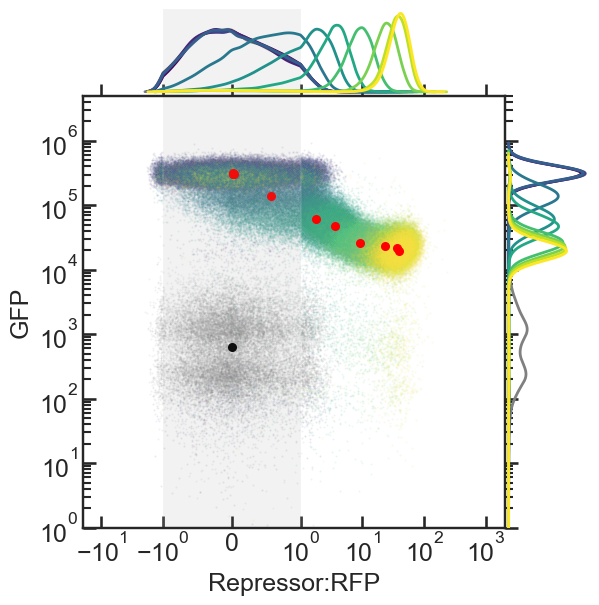

g5, M9, Rep 2


<Figure size 400x400 with 0 Axes>

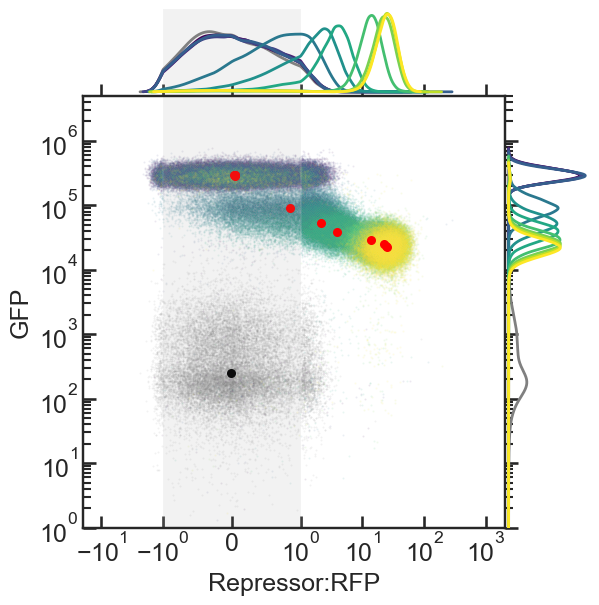

g5, M9, Rep 3


<Figure size 400x400 with 0 Axes>

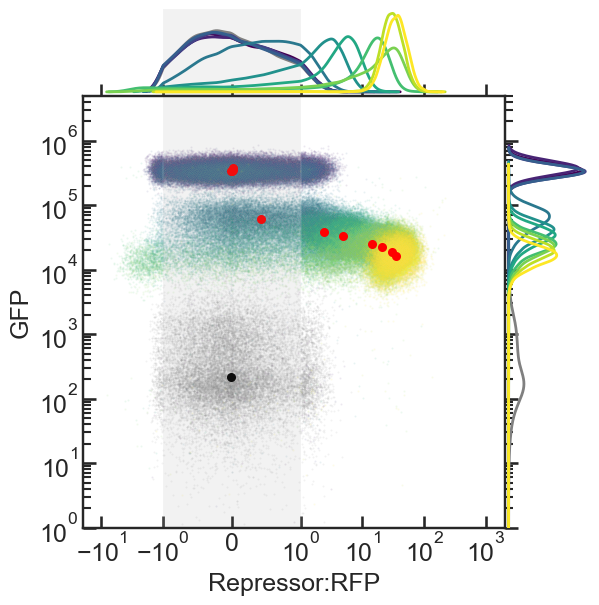

g5, CL, Rep 1


<Figure size 400x400 with 0 Axes>

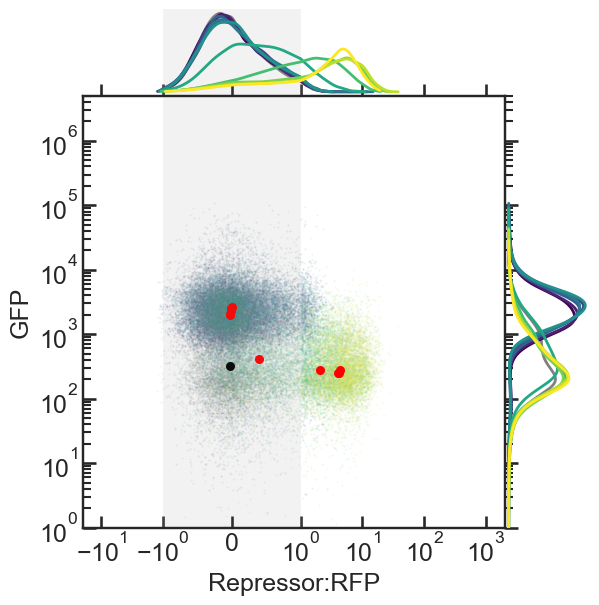

g5, CL, Rep 2


<Figure size 400x400 with 0 Axes>

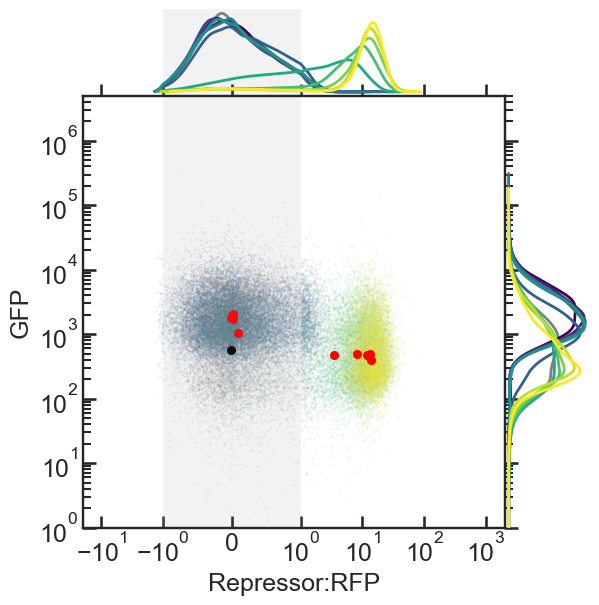

g5, CL, Rep 3


<Figure size 400x400 with 0 Axes>

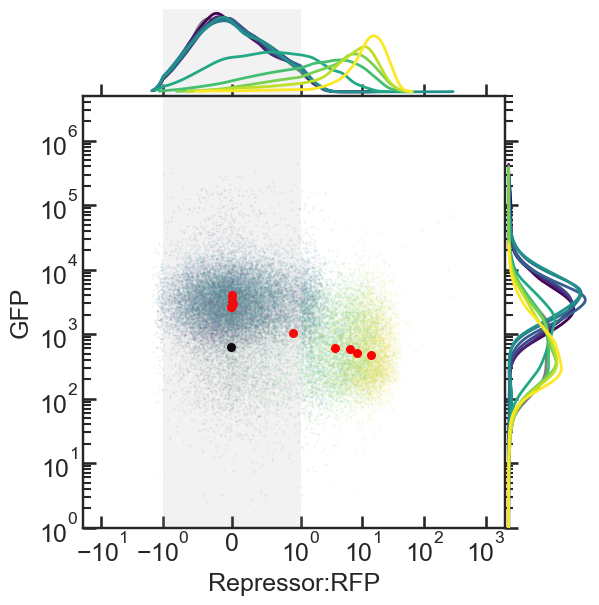

g16, M9, Rep 1


<Figure size 400x400 with 0 Axes>

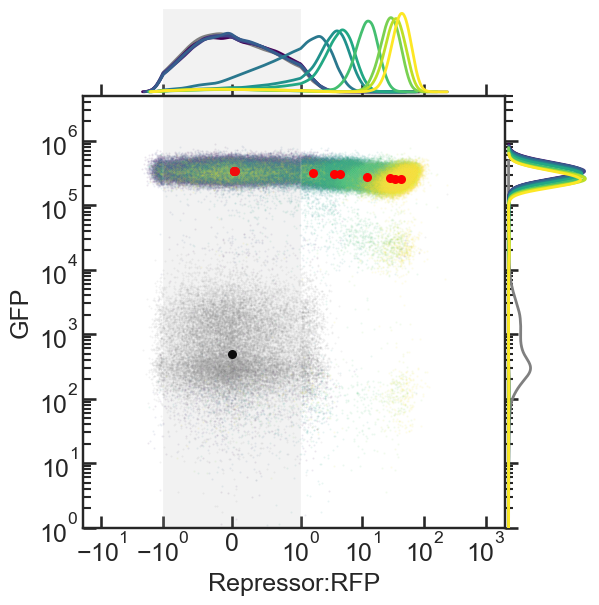

g16, M9, Rep 2


<Figure size 400x400 with 0 Axes>

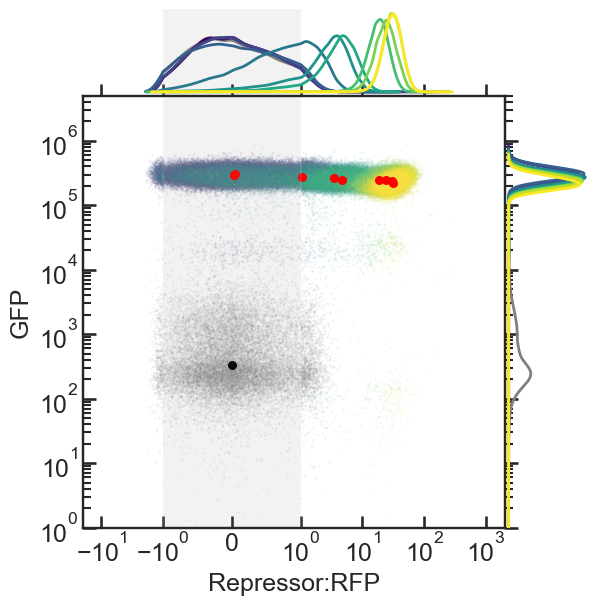

g16, M9, Rep 3


<Figure size 400x400 with 0 Axes>

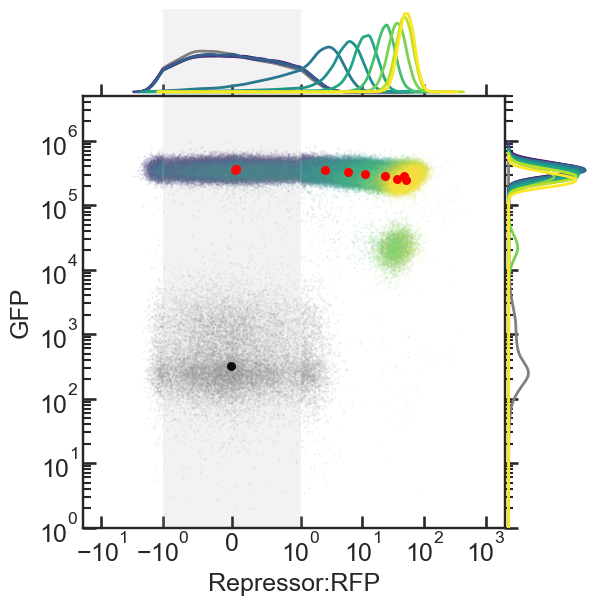

g16, CL, Rep 1


<Figure size 400x400 with 0 Axes>

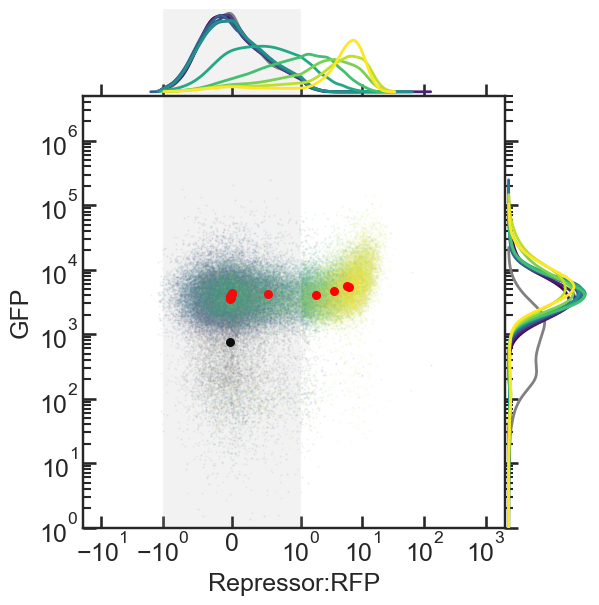

g16, CL, Rep 2


<Figure size 400x400 with 0 Axes>

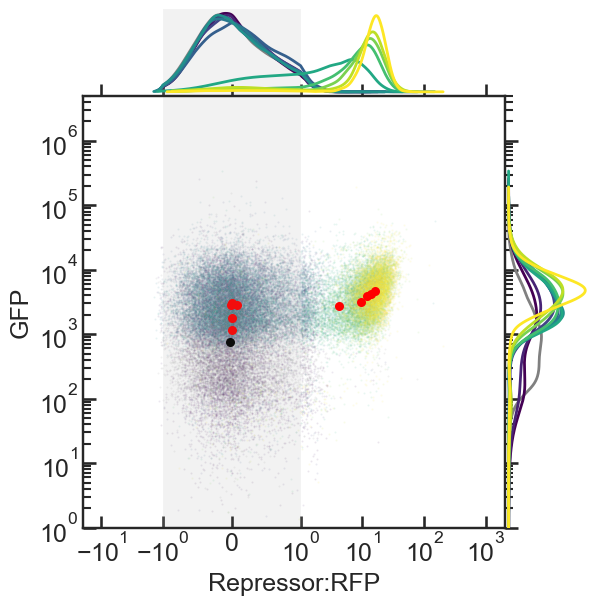

g16, CL, Rep 3


<Figure size 400x400 with 0 Axes>

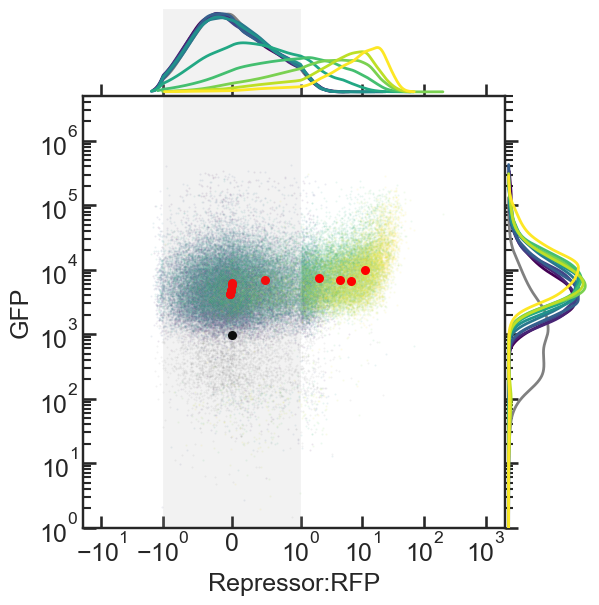

g17, M9, Rep 1


<Figure size 400x400 with 0 Axes>

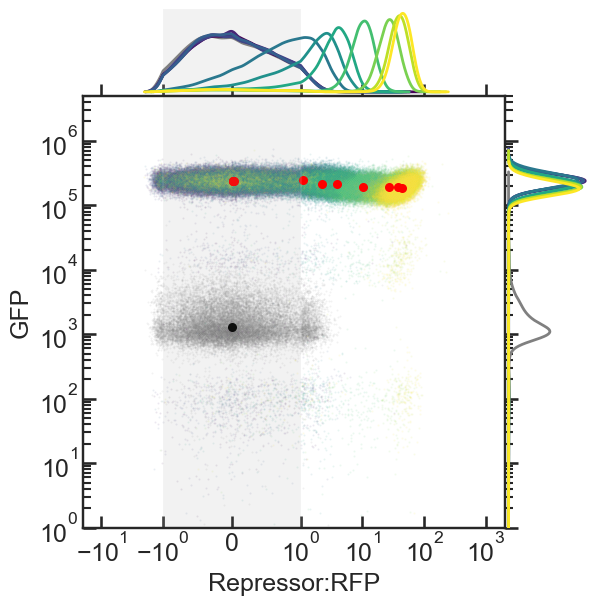

g17, M9, Rep 2


<Figure size 400x400 with 0 Axes>

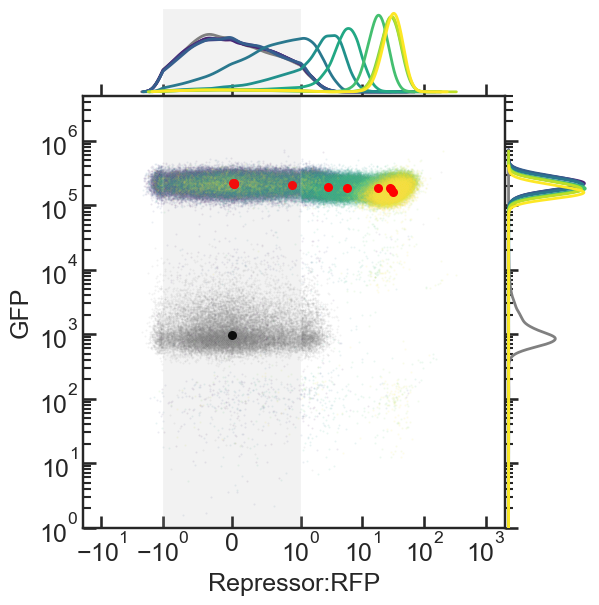

g17, M9, Rep 3


<Figure size 400x400 with 0 Axes>

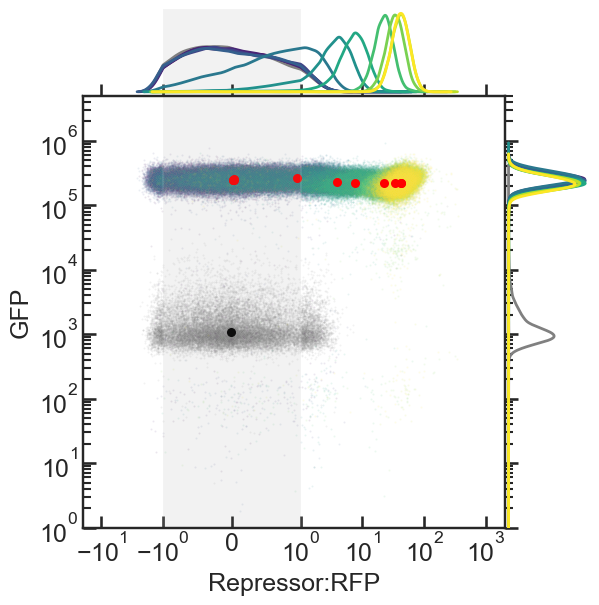

g17, CL, Rep 1


<Figure size 400x400 with 0 Axes>

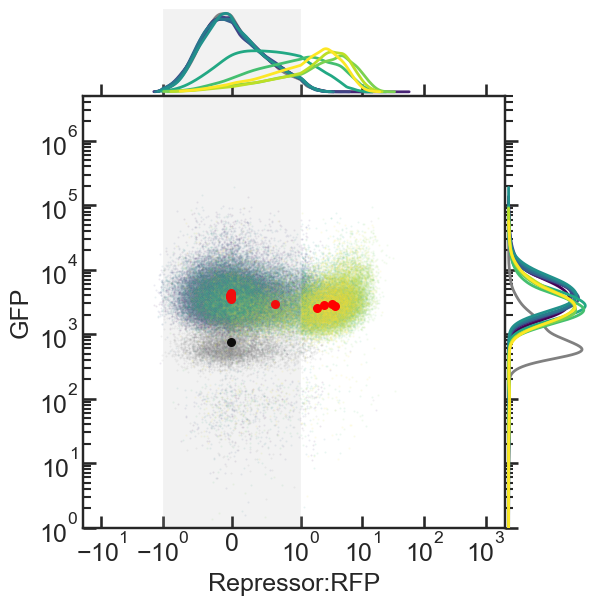

g17, CL, Rep 2


<Figure size 400x400 with 0 Axes>

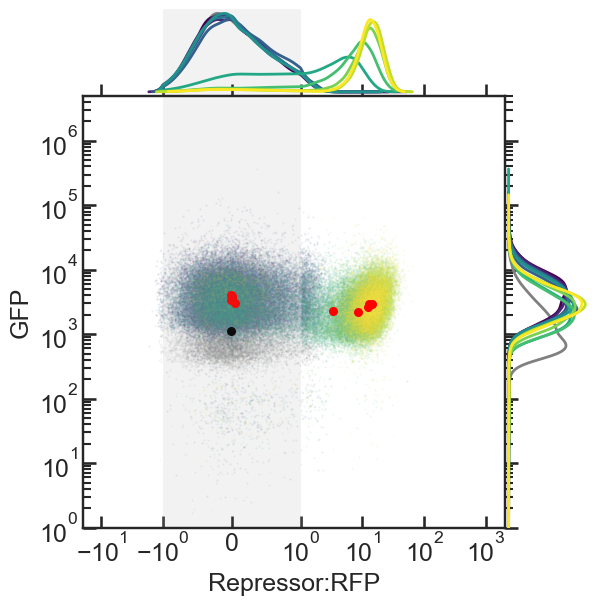

g17, CL, Rep 3


<Figure size 400x400 with 0 Axes>

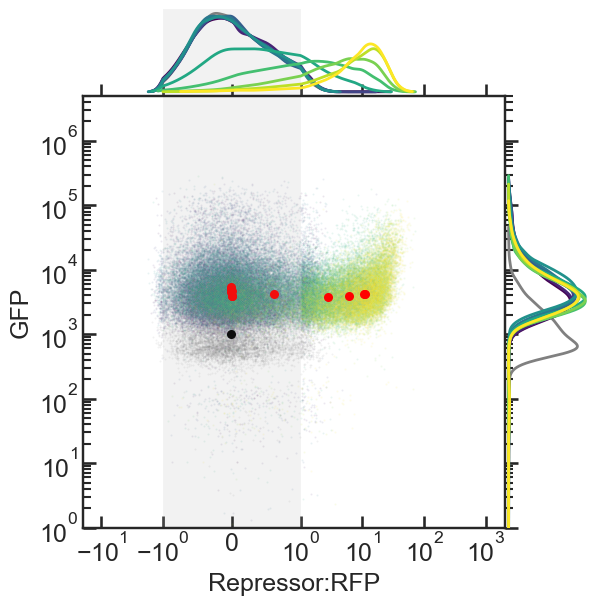

In [46]:
# dCas9:PhlF data
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        for rep in reps:
            atcs = atcs_ls[rep-1][m]

            make_2D_plot(fcs_dict_ls_D, media, grna, rep, atcs, savefig='DP')


g1, M9, Rep 1


<Figure size 400x400 with 0 Axes>

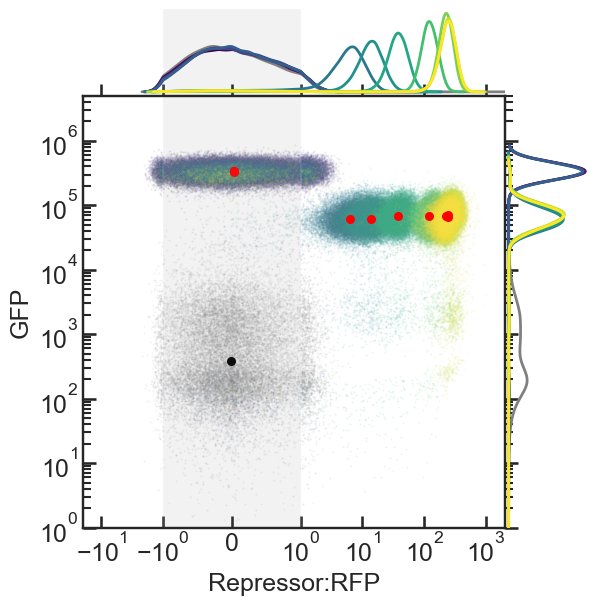

g1, M9, Rep 2


<Figure size 400x400 with 0 Axes>

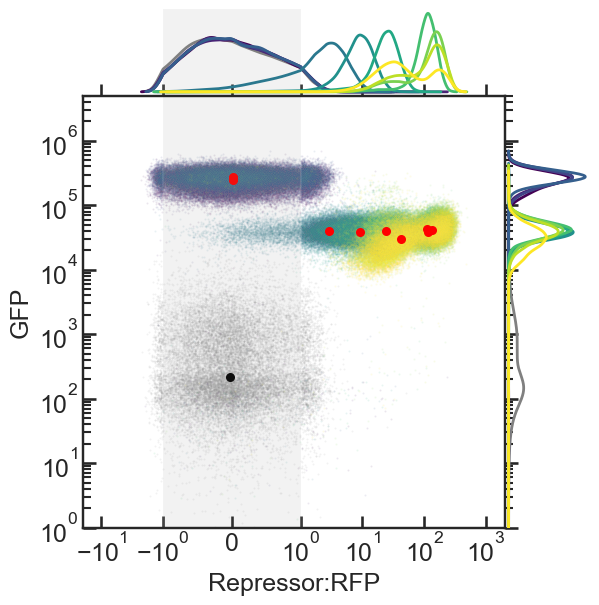

g1, M9, Rep 3


<Figure size 400x400 with 0 Axes>

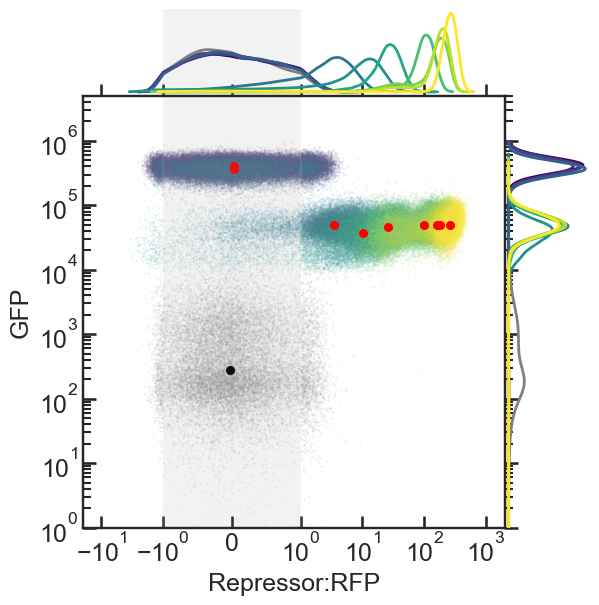

g1, CL, Rep 1


<Figure size 400x400 with 0 Axes>

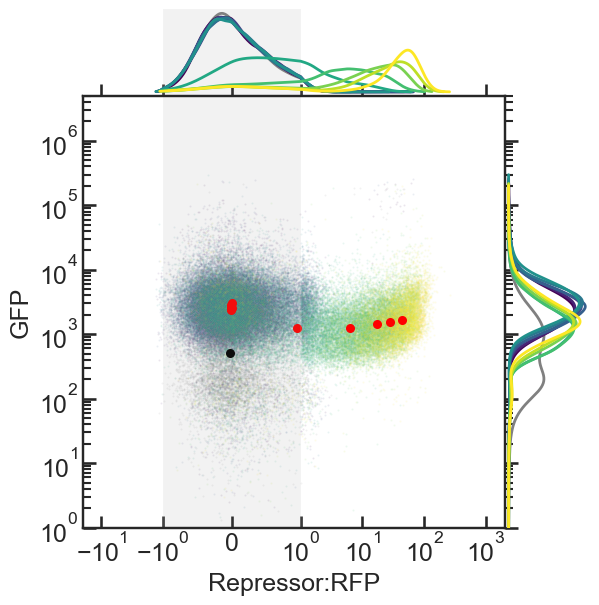

g1, CL, Rep 2


<Figure size 400x400 with 0 Axes>

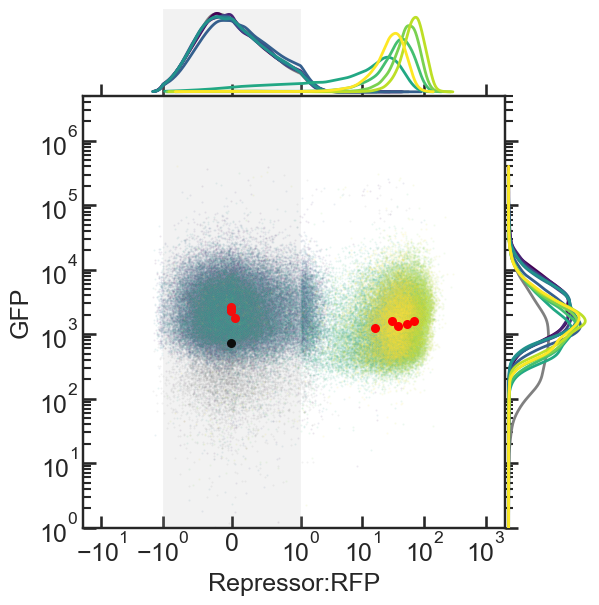

g1, CL, Rep 3


<Figure size 400x400 with 0 Axes>

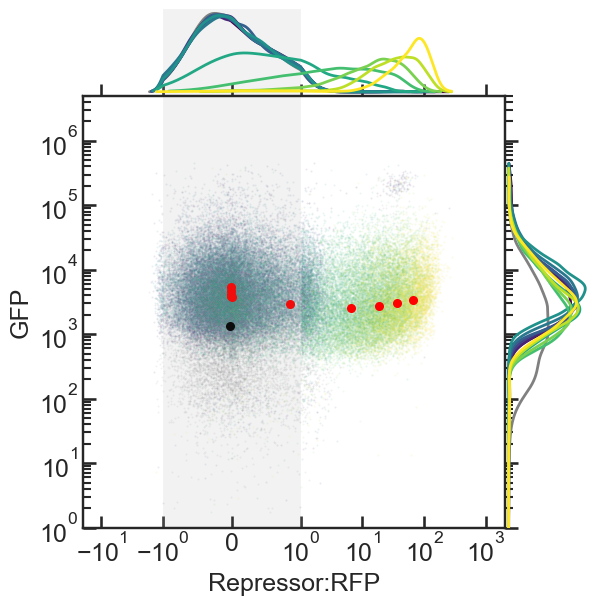

g2, M9, Rep 1


<Figure size 400x400 with 0 Axes>

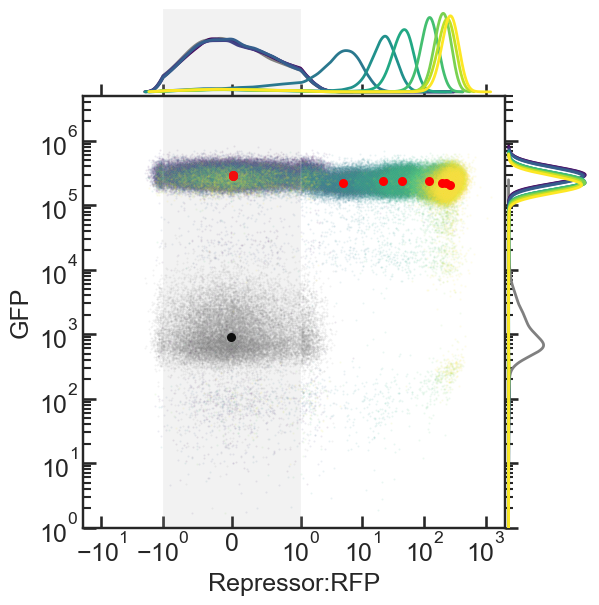

g2, M9, Rep 2


<Figure size 400x400 with 0 Axes>

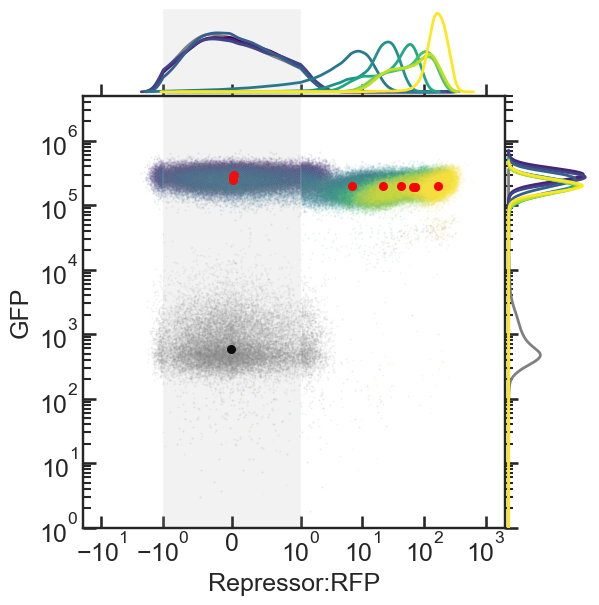

g2, M9, Rep 3


<Figure size 400x400 with 0 Axes>

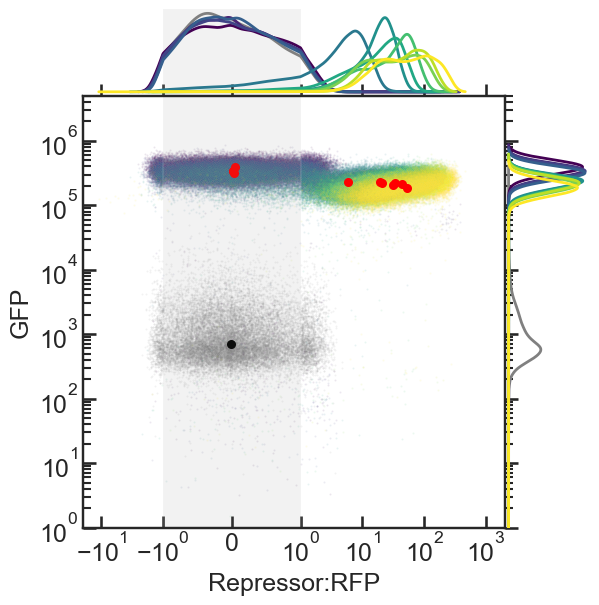

g2, CL, Rep 1


<Figure size 400x400 with 0 Axes>

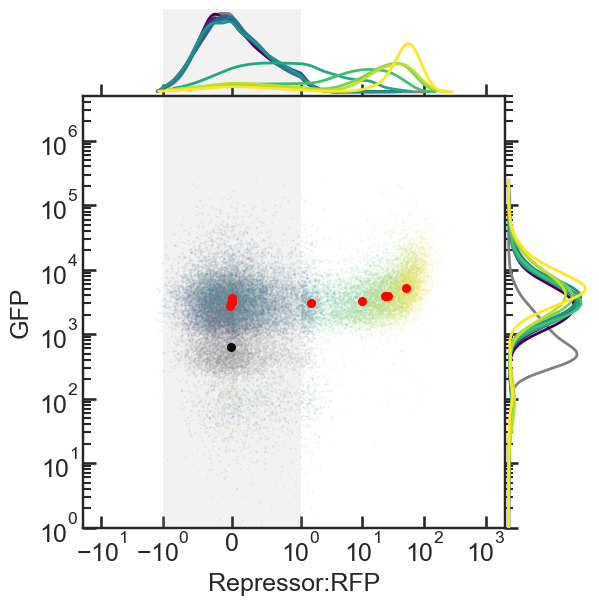

g2, CL, Rep 2


<Figure size 400x400 with 0 Axes>

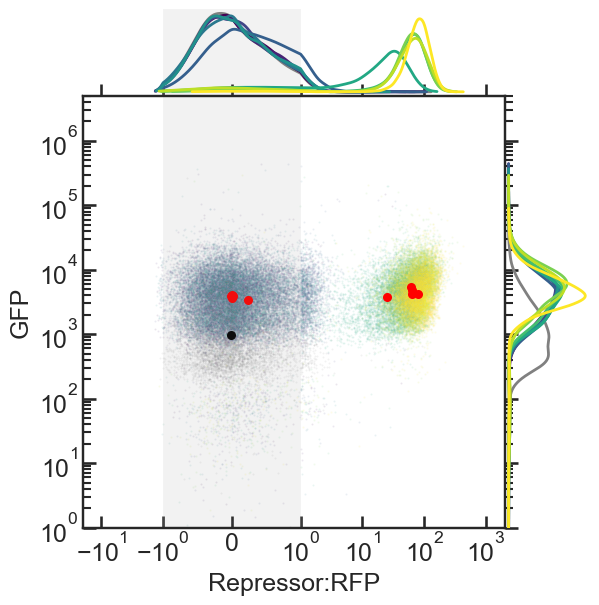

g2, CL, Rep 3


<Figure size 400x400 with 0 Axes>

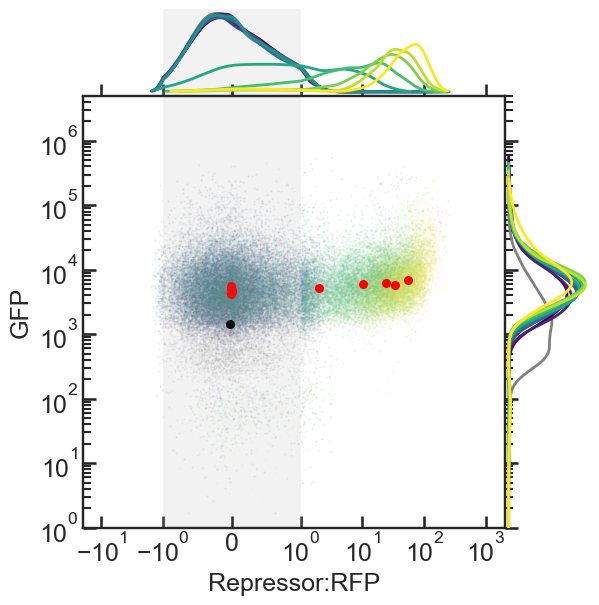

g3, M9, Rep 1


<Figure size 400x400 with 0 Axes>

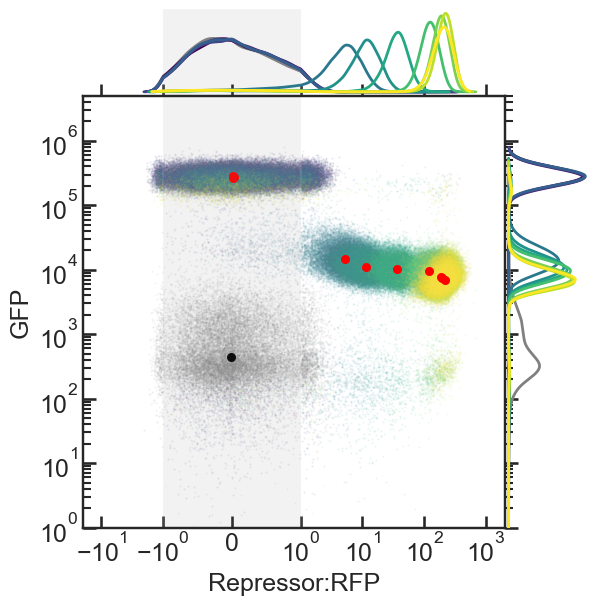

g3, M9, Rep 2


<Figure size 400x400 with 0 Axes>

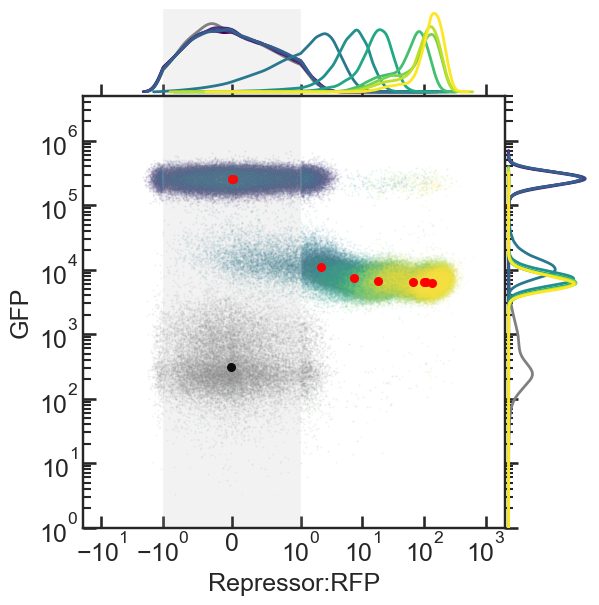

g3, M9, Rep 3


<Figure size 400x400 with 0 Axes>

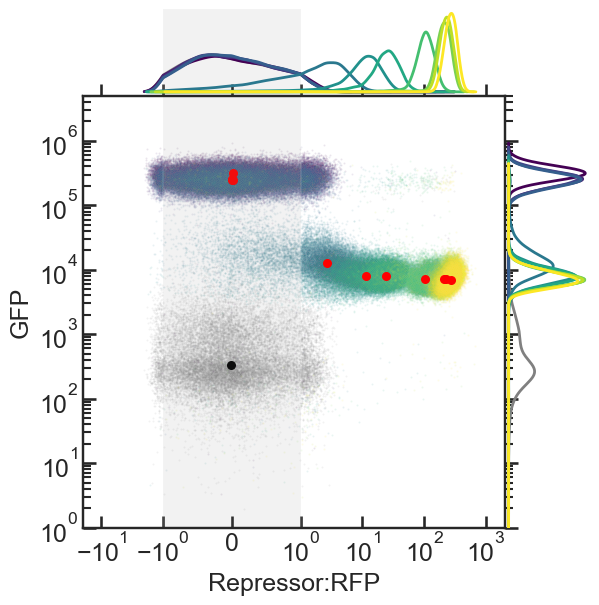

g3, CL, Rep 1


<Figure size 400x400 with 0 Axes>

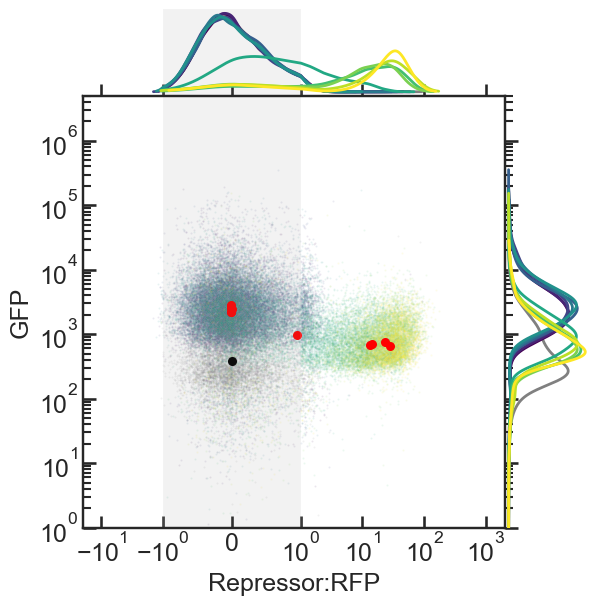

g3, CL, Rep 2


<Figure size 400x400 with 0 Axes>

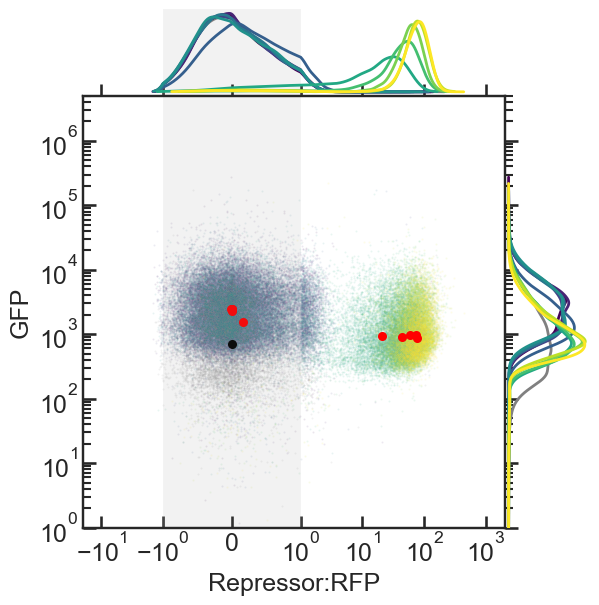

g3, CL, Rep 3


<Figure size 400x400 with 0 Axes>

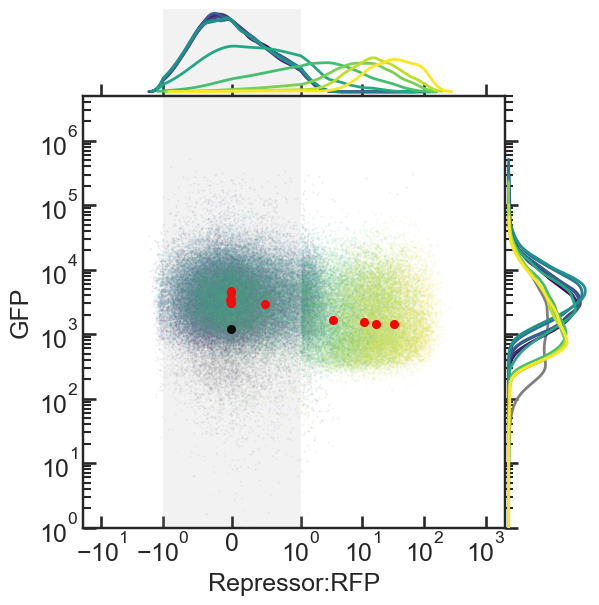

g5, M9, Rep 1


<Figure size 400x400 with 0 Axes>

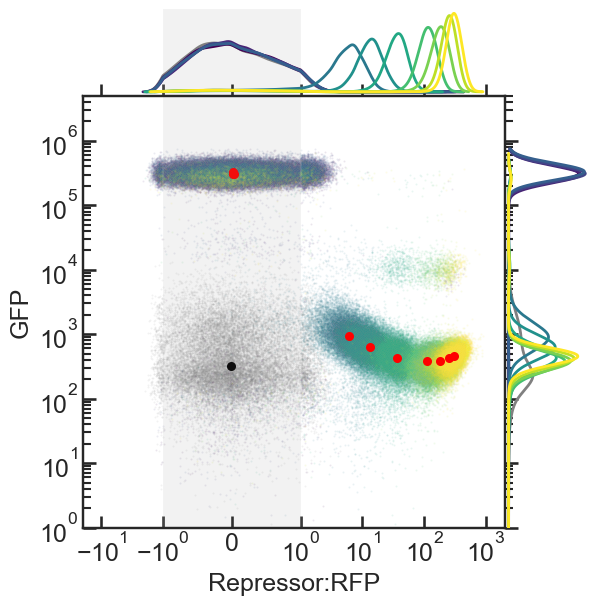

g5, M9, Rep 2


<Figure size 400x400 with 0 Axes>

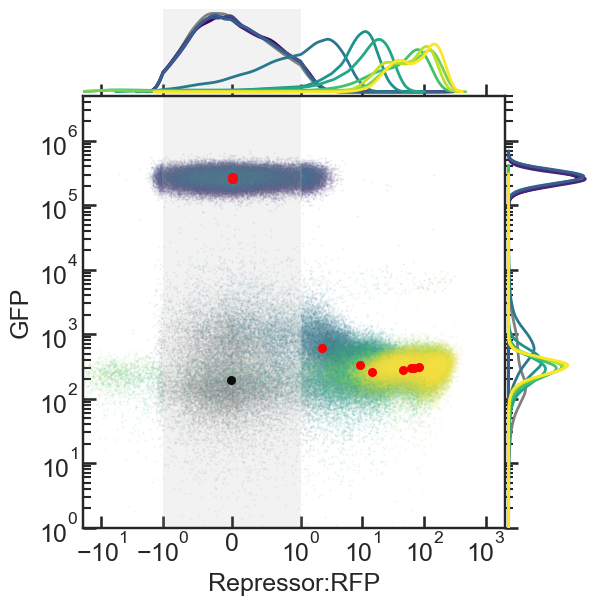

g5, M9, Rep 3


<Figure size 400x400 with 0 Axes>

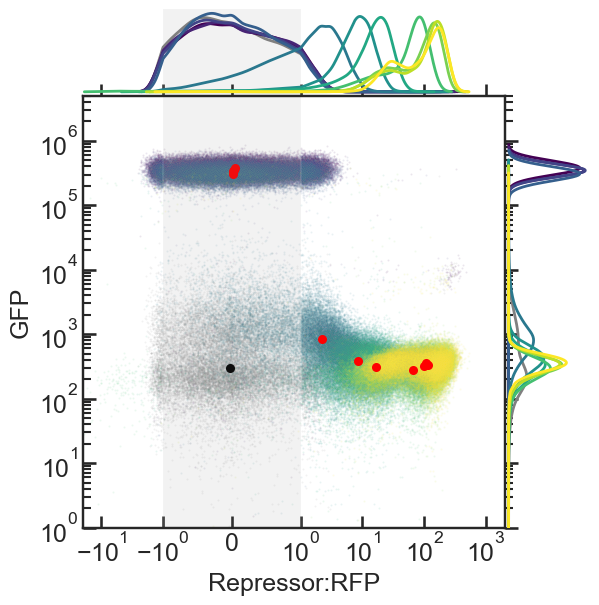

g5, CL, Rep 1


<Figure size 400x400 with 0 Axes>

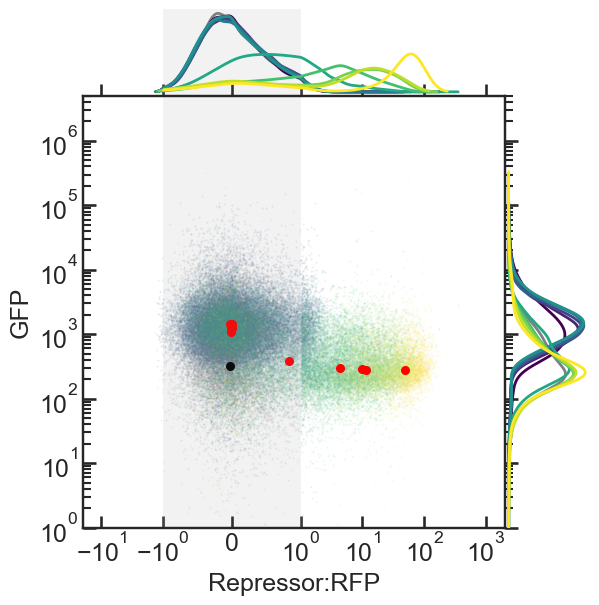

g5, CL, Rep 2


<Figure size 400x400 with 0 Axes>

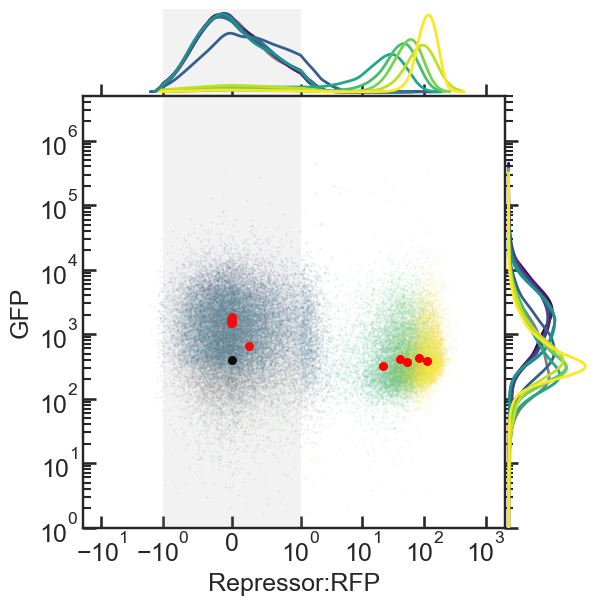

g5, CL, Rep 3


<Figure size 400x400 with 0 Axes>

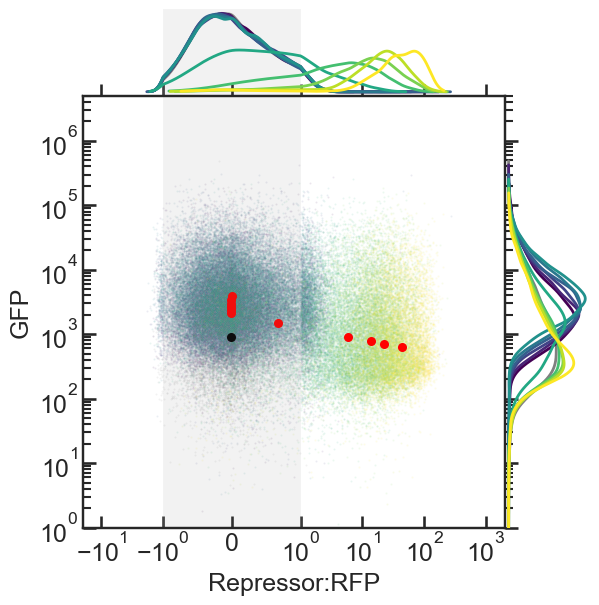

g16, M9, Rep 1


<Figure size 400x400 with 0 Axes>

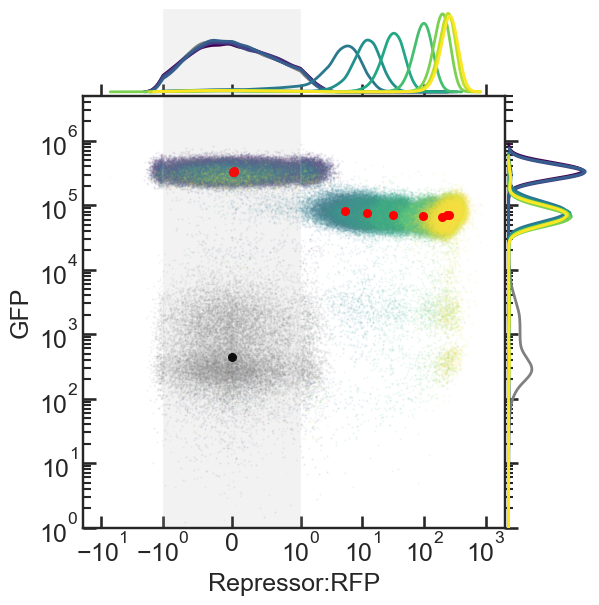

g16, M9, Rep 2


<Figure size 400x400 with 0 Axes>

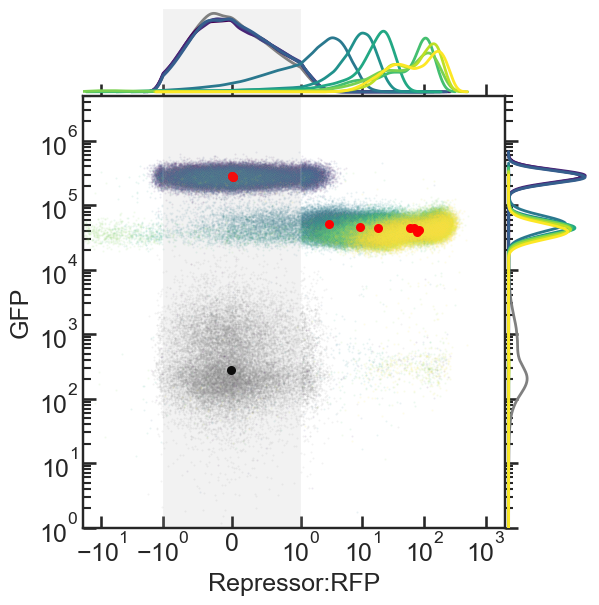

g16, M9, Rep 3


<Figure size 400x400 with 0 Axes>

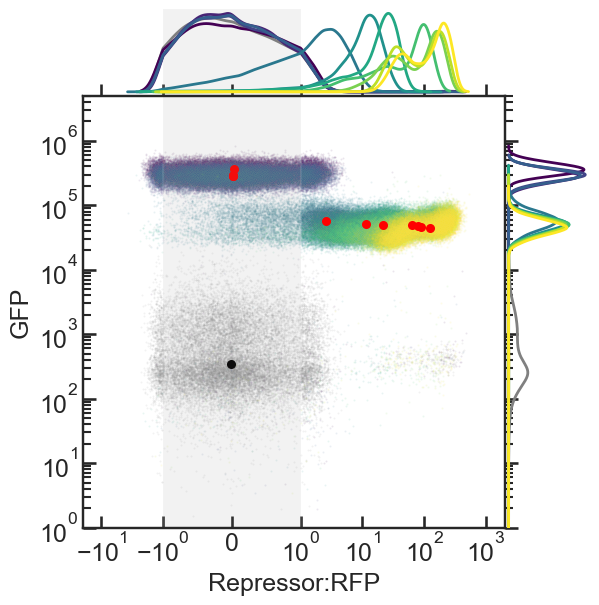

g16, CL, Rep 1


<Figure size 400x400 with 0 Axes>

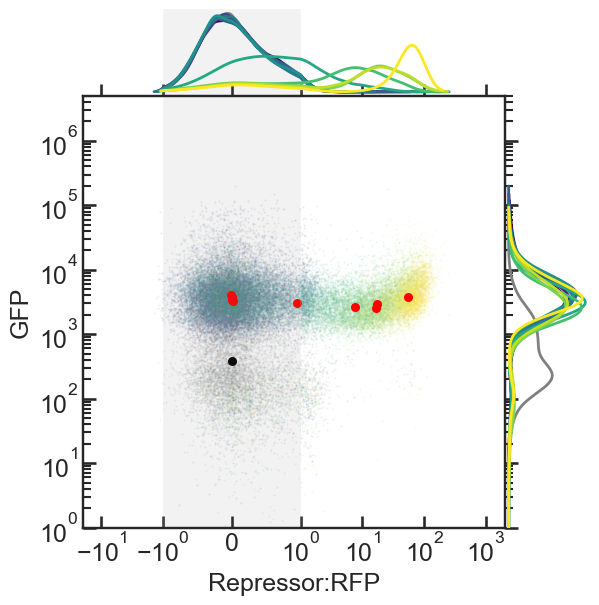

g16, CL, Rep 2


<Figure size 400x400 with 0 Axes>

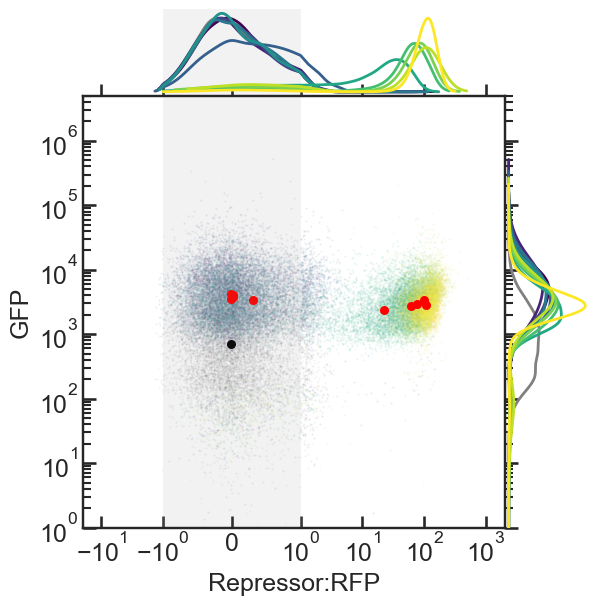

g16, CL, Rep 3


<Figure size 400x400 with 0 Axes>

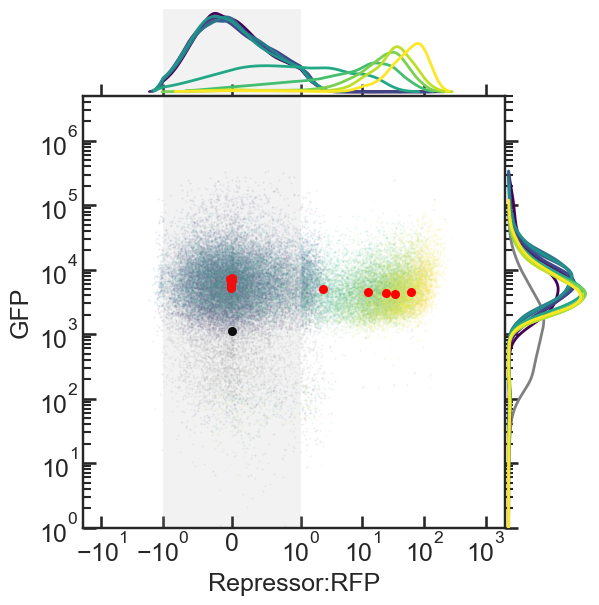

g17, M9, Rep 1


<Figure size 400x400 with 0 Axes>

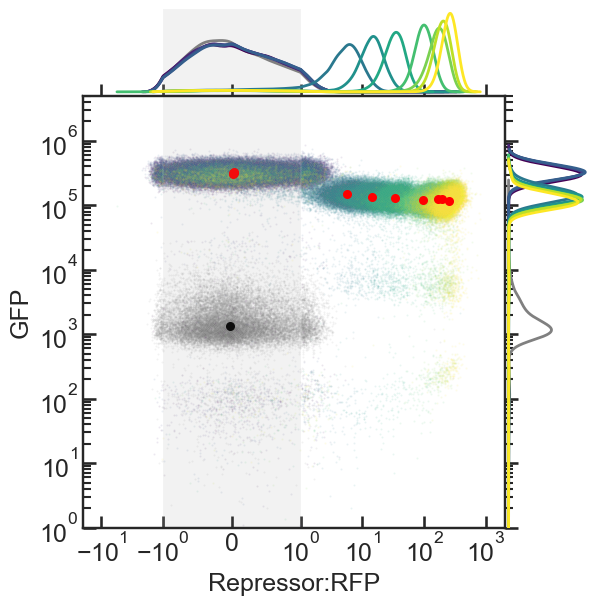

g17, M9, Rep 2


<Figure size 400x400 with 0 Axes>

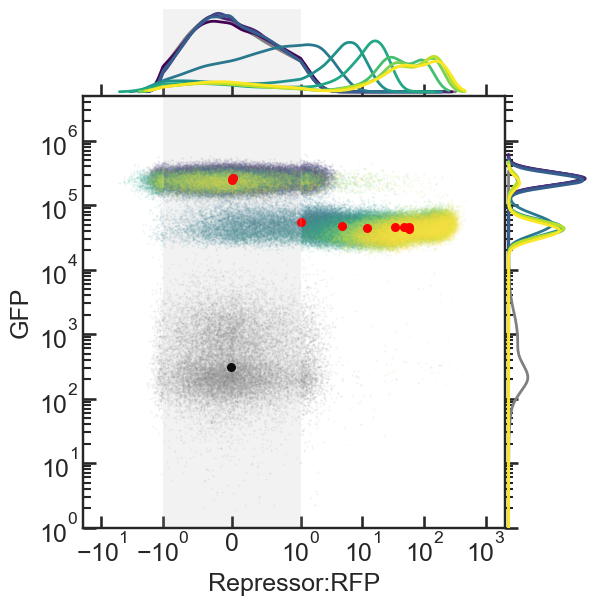

g17, M9, Rep 3


<Figure size 400x400 with 0 Axes>

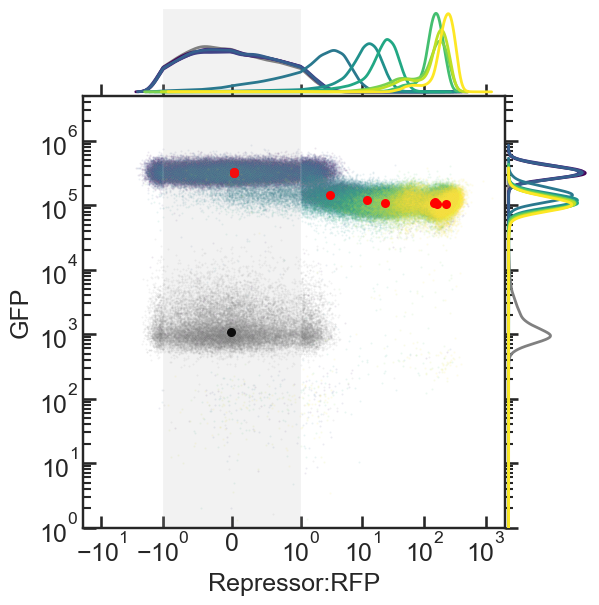

g17, CL, Rep 1


<Figure size 400x400 with 0 Axes>

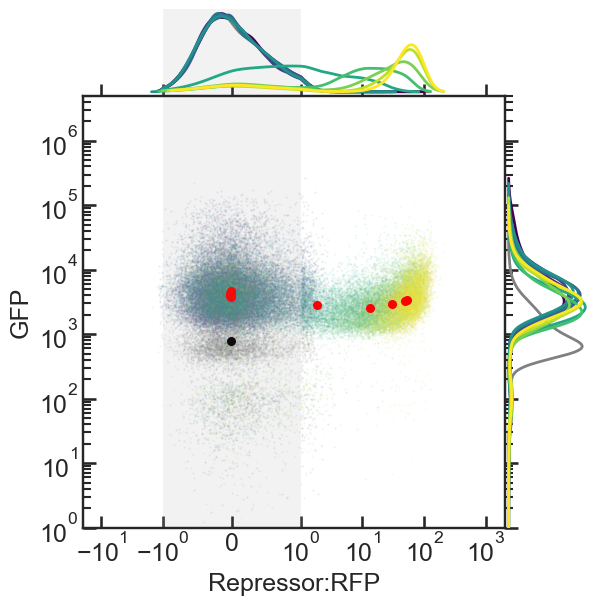

g17, CL, Rep 2


<Figure size 400x400 with 0 Axes>

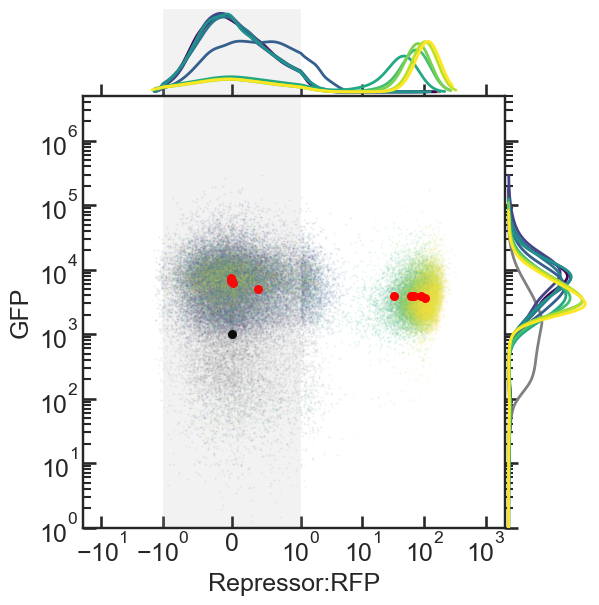

g17, CL, Rep 3


<Figure size 400x400 with 0 Axes>

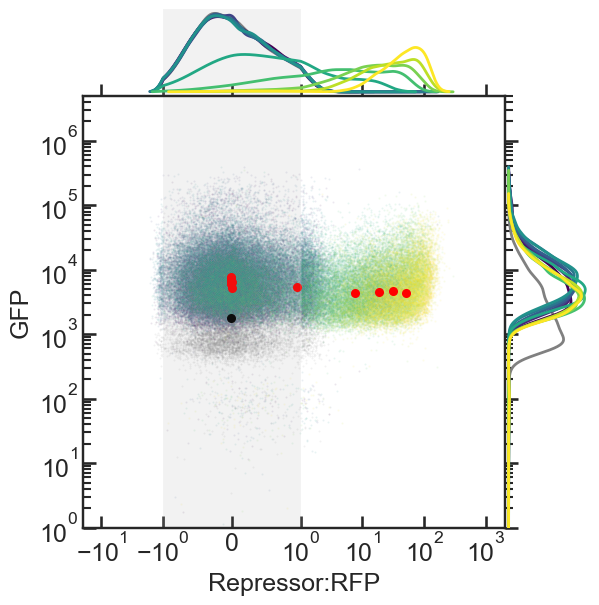

In [47]:
# PhlF data
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        for rep in reps:
            atcs = atcs_ls[rep-1][m]

            make_2D_plot(fcs_dict_ls_P, media, grna, rep, atcs, savefig='P')


## Do parameter estimation and pickle outputs

In [268]:
# dCas9:PhlF

nwalkers = 32
ndim = 4
chain_length = 10000

sigmaB = 0.5
sigmaA = 1
sigmaK = 1
sigmaN = 0.5
muK = np.log(0.1) + sigmaK**2
muN = np.log(1.0) + sigmaN**2

        
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]

        med_gfps = []
        med_rfps = []
        unrep_gfps = []
        rep_gfps = []
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls_D[rep-1]
            plot_inds = plot_inds_ls[rep-1][m]
            atcs = atcs_ls[rep-1][m]
            for n in range(len(plot_inds)):
                fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[n+1]]
                gfps = np.array(fcs[:,5])
                rfps = np.array(fcs[:,7])
                med_gfps.append(np.median(gfps))
                med_rfps.append(np.median(rfps))
                if n == 0:
                    unrep_gfps.append(np.median(gfps))
                if n == len(plot_inds)-1:
                    rep_gfps.append(np.median(gfps))

        # band-aid fix: set negative values to 1e-6 for fitting
        med_gfps = np.array(med_gfps)
        med_rfps = np.array(med_rfps)
        
        med_gfps[med_gfps < 0] = 1e-6
        med_rfps[med_rfps < 0] = 1e-6

        # prepare for emcee
        
        # take geomean of repressed GFP values from each replicate
        alpha_guess = stats.gmean(rep_gfps)
        # take geomean of unrepressed GFP values from each replicate
        unrepressed_guess = stats.gmean(unrep_gfps)
        
        beta_guess = unrepressed_guess - alpha_guess
        # what if beta is negative? for now, bandaid fix of set it to 1e-6
        if beta_guess < 0:
            beta_guess = 1e-6

        # ln-scale everything for comparison to ln-scaled model
        med_gfps = np.log(med_gfps)
        alpha_guess = np.log(alpha_guess)
        beta_guess = np.log(beta_guess)

        # set prior scale parameters
        muB = beta_guess + sigmaB**2 # <- note that the 'guess' values are already in ln() scale.
        muA = alpha_guess + sigmaA**2
        theta0 = np.exp(np.array([beta_guess, alpha_guess, muK, muN])) # <- initial parameter position is in standard scale
        prior_params = np.array([np.array([muB, sigmaB]),
                                 np.array([muA, sigmaA]),
                                 np.array([muK, sigmaK]),
                                 np.array([muN, sigmaN]),
                                ])

        # random initialization of walkers
        pos = theta0 * (1 + 1e-4 * np.random.randn(nwalkers, ndim))
        pos = 10**(np.log10(theta0) + np.random.randn(nwalkers,ndim)*1e-4) # <- not sure how to do this jiggling properly

        not_long_enough = True
        length_factor = 1        
        while not_long_enough:        
            cost_progress = []
            print('Starting MCMC for D '+grna+' , '+media+' for '+str(chain_length*length_factor)+' steps...')
            sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability, args=(med_rfps, med_gfps, prior_params))
            sampler.run_mcmc(pos, chain_length*length_factor, progress=True);

            autocorr_vec = sampler.get_autocorr_time()
            max_tau = np.max(autocorr_vec)
            if max_tau*50 <= chain_length*length_factor:
                not_long_enough = False
            else:
                length_factor *= 10

            if length_factor >= 100:
                print('******* Chain length too long! aborting. ********')
                not_long_enough = False

        # pickle the sampler output
        filename = 'D_' + grna + '_' + media + '_' + str(nwalkers) + '_' + str(chain_length*length_factor) + '.pkl'
        with open('./MCMC_outputs/'+filename, 'wb') as f:
            pickle.dump(sampler, f)
        f.close()


Starting MCMC for D g1 , M9 for 10000 steps...


100%|█████████████████████████████████████| 10000/10000 [00:05<00:00, 1684.98it/s]


Starting MCMC for D g1 , CL for 10000 steps...


100%|█████████████████████████████████████| 10000/10000 [00:06<00:00, 1612.27it/s]


Starting MCMC for D g2 , M9 for 10000 steps...


...

100%|█████████████████████████████████████| 10000/10000 [00:07<00:00, 1400.64it/s]


Starting MCMC for D g17 , M9 for 10000 steps...


100%|█████████████████████████████████████| 10000/10000 [00:06<00:00, 1531.43it/s]


Starting MCMC for D g17 , CL for 10000 steps...


100%|█████████████████████████████████████| 10000/10000 [00:06<00:00, 1615.38it/s]


In [269]:
# PhlF

nwalkers = 32
ndim = 4
chain_length = 10000

sigmaB = 0.5
sigmaA = 1
sigmaK = 1
sigmaN = 0.5
muK = np.log(0.1) + sigmaK**2
muN = np.log(1.0) + sigmaN**2

        
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]

        med_gfps = []
        med_rfps = []
        unrep_gfps = []
        rep_gfps = []
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls_P[rep-1]
            plot_inds = plot_inds_ls[rep-1][m]
            atcs = atcs_ls[rep-1][m]
            for n in range(len(plot_inds)):
                fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[n+1]]
                gfps = np.array(fcs[:,5])
                rfps = np.array(fcs[:,7])
                med_gfps.append(np.median(gfps))
                med_rfps.append(np.median(rfps))
                if n == 0:
                    unrep_gfps.append(np.median(gfps))
                if n == len(plot_inds)-1:
                    rep_gfps.append(np.median(gfps))

        # band-aid fix: set negative values to 1e-6 for fitting
        med_gfps = np.array(med_gfps)
        med_rfps = np.array(med_rfps)
        
        med_gfps[med_gfps < 0] = 1e-6
        med_rfps[med_rfps < 0] = 1e-6

        # prepare for emcee
        
        # take geomean of repressed GFP values from each replicate
        alpha_guess = stats.gmean(rep_gfps)
        # take geomean of unrepressed GFP values from each replicate
        unrepressed_guess = stats.gmean(unrep_gfps)
        
        beta_guess = unrepressed_guess - alpha_guess
        # what if beta is negative? for now, bandaid fix of set it to 1e-6
        if beta_guess < 0:
            beta_guess = 1e-6

        # ln-scale everything for comparison to ln-scaled model
        med_gfps = np.log(med_gfps)
        alpha_guess = np.log(alpha_guess)
        beta_guess = np.log(beta_guess)
        
        # set prior scale parameters
        muB = beta_guess + sigmaB**2 # <- note that the 'guess' values are already in ln() scale.
        muA = alpha_guess + sigmaA**2
        theta0 = np.exp(np.array([beta_guess, alpha_guess, muK, muN])) # <- initial parameter position is in standard scale
        prior_params = np.array([np.array([muB, sigmaB]),
                                 np.array([muA, sigmaA]),
                                 np.array([muK, sigmaK]),
                                 np.array([muN, sigmaN]),
                                ])

        # random initialization of walkers
        pos = theta0 * (1 + 1e-4 * np.random.randn(nwalkers, ndim))
        pos = 10**(np.log10(theta0) + np.random.randn(nwalkers,ndim)*1e-4) # <- not sure how to do this jiggling properly

        not_long_enough = True
        length_factor = 1        
        while not_long_enough:        
            cost_progress = []
            print('Starting MCMC for P '+grna+' , '+media+' for '+str(chain_length*length_factor)+' steps...')
            sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability, args=(med_rfps, med_gfps, prior_params))
            sampler.run_mcmc(pos, chain_length*length_factor, progress=True);

            autocorr_vec = sampler.get_autocorr_time()
            max_tau = np.max(autocorr_vec)
            if max_tau*50 <= chain_length*length_factor:
                not_long_enough = False
            else:
                length_factor *= 10

            if length_factor >= 100:
                print('******* Chain length too long! aborting. ********')
                not_long_enough = False

        # pickle the sampler output
        filename = 'P_' + grna + '_' + media + '_' + str(nwalkers) + '_' + str(chain_length*length_factor) + '.pkl'
        with open('./MCMC_outputs/'+filename, 'wb') as f:
            pickle.dump(sampler, f)
        f.close()


Starting MCMC for P g1 , M9 for 10000 steps...


100%|█████████████████████████████████████| 10000/10000 [00:06<00:00, 1620.69it/s]


Starting MCMC for P g1 , CL for 10000 steps...


100%|█████████████████████████████████████| 10000/10000 [00:06<00:00, 1647.97it/s]


Starting MCMC for P g2 , M9 for 10000 steps...


...

100%|█████████████████████████████████████| 10000/10000 [00:06<00:00, 1533.64it/s]


Starting MCMC for P g17 , M9 for 10000 steps...


100%|█████████████████████████████████████| 10000/10000 [00:06<00:00, 1629.02it/s]


Starting MCMC for P g17 , CL for 10000 steps...


100%|█████████████████████████████████████| 10000/10000 [00:06<00:00, 1639.27it/s]


## Unpickle MCMC outputs and plot

In [9]:
# generate a dataframe of just median (RFP,GFP) values, grouping replicates

df_ls_D = []
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        med_gfps = []
        med_rfps = []
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls_D[rep-1]
            plot_inds = plot_inds_ls[rep-1][m]
            atcs = atcs_ls[rep-1][m]
            for n in range(len(plot_inds)):
                fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[n+1]]
                gfps = np.array(fcs[:,5])
                rfps = np.array(fcs[:,7])

                # #bandaid fix: set negative values to epsilon
                # med_gfp = np.max([np.median(gfps), 1e-6])
                # med_rfp = np.max([np.median(rfps), 1e-6])
                med_gfp = np.median(gfps)
                med_rfp = np.median(rfps)
                
                row_to_append = [grna, media, np.log(med_gfp), med_rfp] #<- ln() the GFP values
                df_ls_D.append(row_to_append)

df_medians_D = pd.DataFrame(df_ls_D, columns=['gRNA','Media','ln median GFP', 'median RFP'])



df_ls_P = []
for grna in grnas:
    for m in range(len(medias)):
        media = medias[m]
        med_gfps = []
        med_rfps = []
        for rep in reps:
            fcs_gated_dict = fcs_dict_ls_P[rep-1]
            plot_inds = plot_inds_ls[rep-1][m]
            atcs = atcs_ls[rep-1][m]
            for n in range(len(plot_inds)):
                fcs = fcs_gated_dict[media+'_'+grna+'_'+atcs[n+1]]
                gfps = np.array(fcs[:,5])
                rfps = np.array(fcs[:,7])

                # #bandaid fix: set negative values to epsilon
                # med_gfp = np.max([np.median(gfps), 1e-6])
                # med_rfp = np.max([np.median(rfps), 1e-6])
                med_gfp = np.median(gfps)
                med_rfp = np.median(rfps)
                
                row_to_append = [grna, media, np.log(med_gfp), med_rfp] #<- ln() the GFP values
                df_ls_P.append(row_to_append)

df_medians_P = pd.DataFrame(df_ls_P, columns=['gRNA','Media','ln median GFP', 'median RFP'])

dCas9:PhlF data
g1


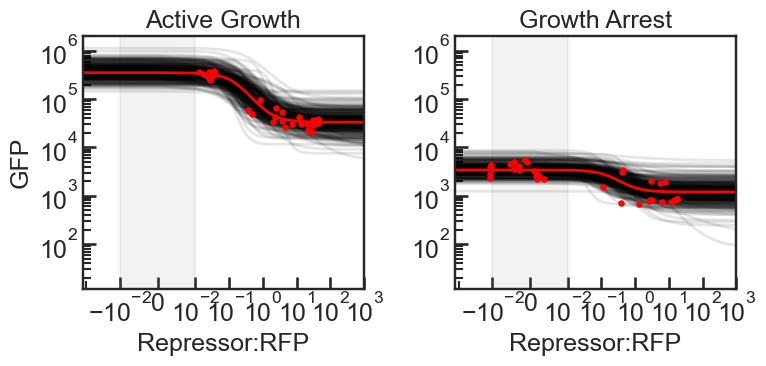

g2


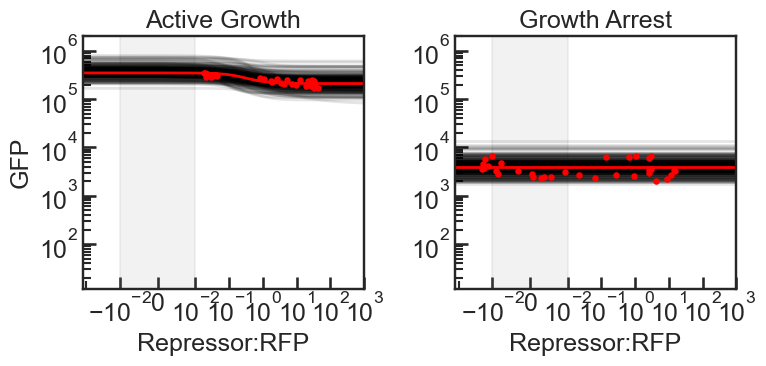

g3


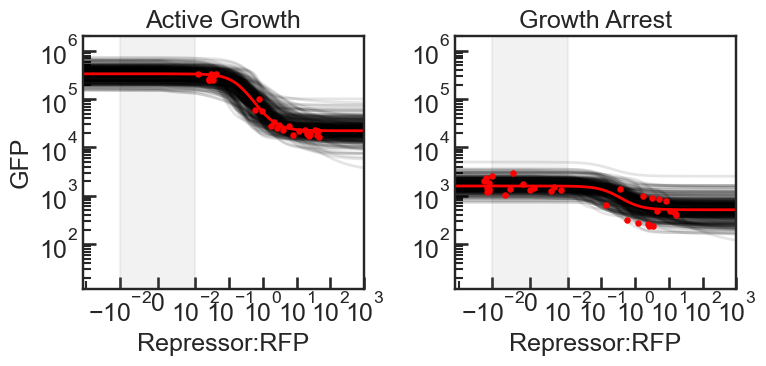

g5


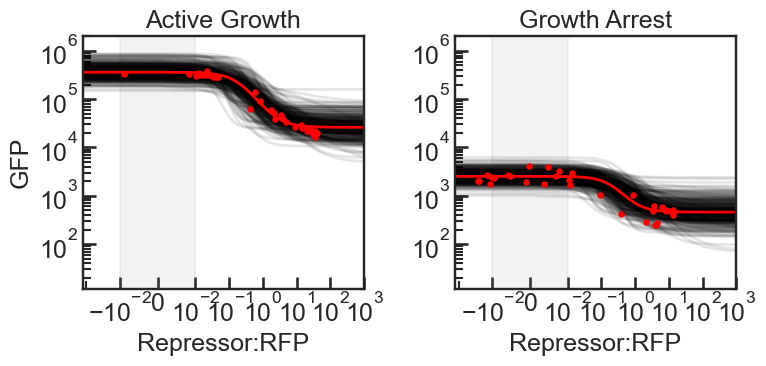

g16


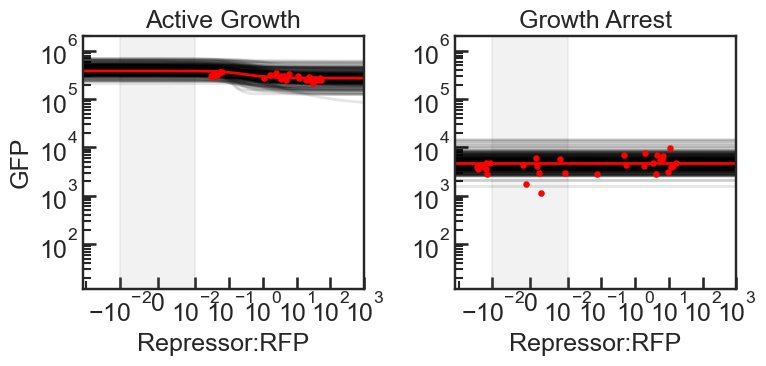

g17


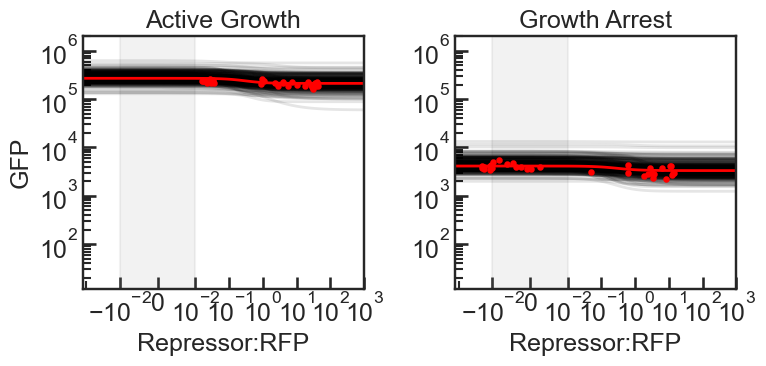

In [10]:
print('dCas9:PhlF data')


trajectories_to_plot = 300

for grna in grnas:
    print(grna)
    fig, ax = plt.subplots(1,2, figsize=(8,4), sharey=False, sharex=True)
    for m in range(len(medias)):
        media = medias[m]

        dfslice = df_medians_D[(df_medians_D['gRNA'] == grna) &
                             (df_medians_D['Media'] == media)]
        
        filename = './MCMC_outputs/D_'+grna+'_'+media+'_32_10000.pkl'

        with open(filename, 'rb') as f:
            sampler = pickle.load(f)
        f.close()

        flat_samples = sampler.get_chain(discard=9000, flat=True)

        inds = np.random.randint(len(flat_samples), size=trajectories_to_plot)
        
        betas = np.empty(trajectories_to_plot)
        alphas = np.empty(trajectories_to_plot)
        Ks = np.empty(trajectories_to_plot)
        ns = np.empty(trajectories_to_plot)
        for i in range(len(inds)):
            ind = inds[i]
            sample = flat_samples[ind]
            xsmooth = np.logspace(-3,3,100)
            ysmooth = np.log(Hill_rep_fun(xsmooth, sample))
            # append a negative point on the far left for plotting
            xsmooth = np.insert(xsmooth, 0, -10)
            ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, sample)))
            
            ax[m].plot(xsmooth, np.exp(ysmooth), c='k', alpha=0.1)

            betas[i] = sample[0]
            alphas[i] = sample[1]
            Ks[i] = sample[2]
            ns[i] = sample[3]

        # Plot curve with medians of all parameter values
        xsmooth = np.logspace(-3,3,100)
        med_sample = [np.median(betas),
                       np.median(alphas),
                       np.median(Ks),
                       np.median(ns)]
        ysmooth = np.log(Hill_rep_fun(xsmooth,med_sample))
        xsmooth = np.insert(xsmooth, 0, -10)
        ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, med_sample)))
        ax[m].plot(xsmooth, np.exp(ysmooth), c='r')

        rfp_scatters = dfslice['median RFP'].values
        gfp_scatters = dfslice['ln median GFP'].values
        ax[m].scatter(rfp_scatters, np.exp(gfp_scatters), color='r', s=10, zorder=100)
        
        # sns.scatterplot(data=dfslice, x='median RFP', y='ln median GFP',
        #                 color='r', ax=ax[m], zorder=100)
        
        ax[m].set_xscale('symlog', linthresh=.01)
        ax[m].set_yscale('log')
        # ax[m].set_xscale('log')
        # ax[m].set_title(media)
        ax[m].axvspan(-.01,.01, color='grey', alpha=0.1)
        ax[m].set_xlim((-.13,1e3))
        xticks = ax[m].get_xticks()
        xticklabels = ax[m].get_xticklabels()
        ax[m].set_xticks(xticks[2:])
        ax[m].set_xticklabels(xticklabels[2:])

    yminmin = 1.2e1
    ymaxmax = 2e6
    ax[0].set_ylim((yminmin, ymaxmax))
    ax[1].set_ylim((yminmin, ymaxmax))

    ax[0].set_title('Active Growth')
    ax[1].set_title('Growth Arrest')
    ax[0].set_ylabel('GFP')
    ax[0].set_xlabel('Repressor:RFP')
    ax[1].set_xlabel('Repressor:RFP')
    # plt.suptitle(grna)
    plt.tight_layout()
    plt.savefig('./figs/BPEplots/DP_'+grna+'.pdf')
    plt.show()
        

PhlF data
g1


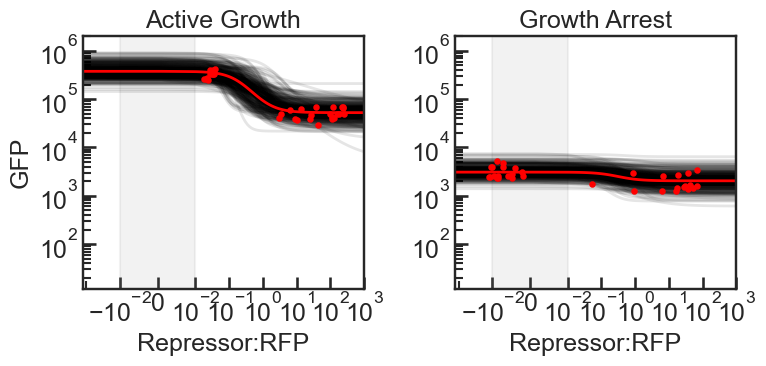

g2


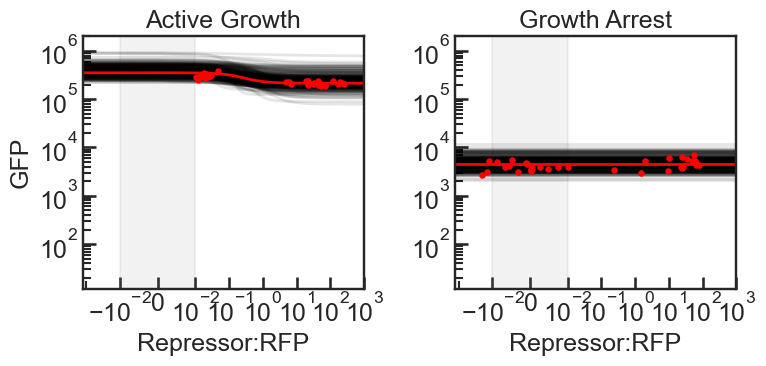

g3


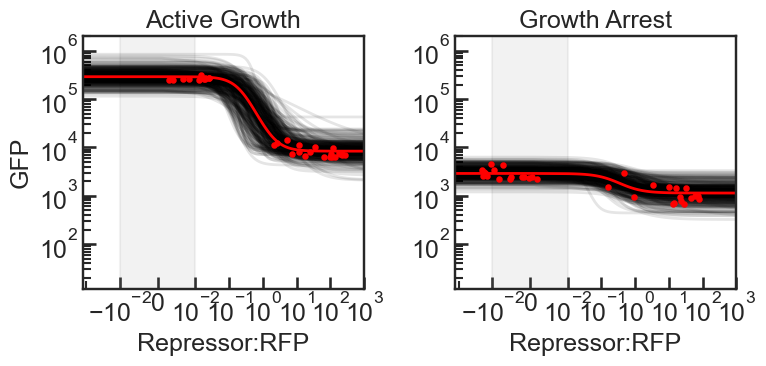

g5


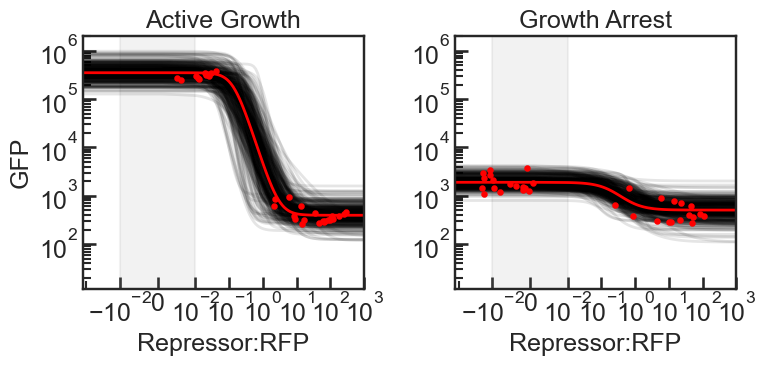

g16


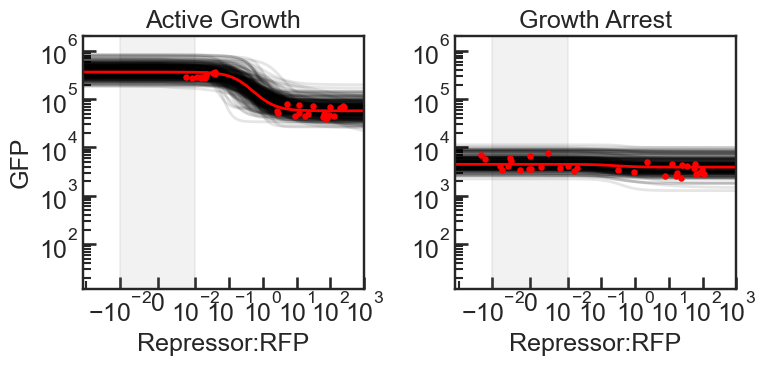

g17


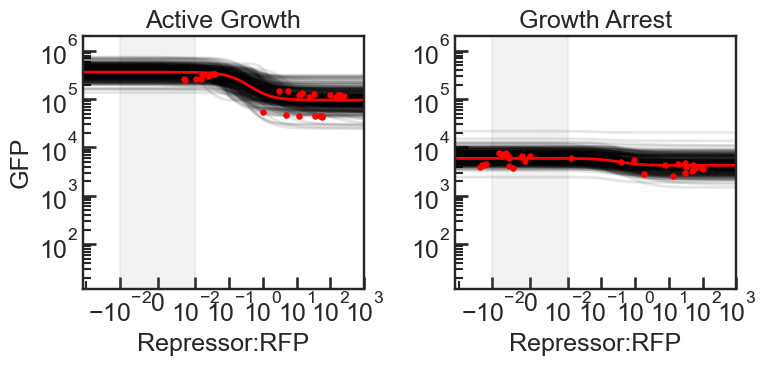

In [272]:
print('PhlF data')


trajectories_to_plot = 300

for grna in grnas:
    print(grna)
    fig, ax = plt.subplots(1,2, figsize=(8,4), sharey=False, sharex=True)
    for m in range(len(medias)):
        media = medias[m]

        dfslice = df_medians_P[(df_medians_P['gRNA'] == grna) &
                             (df_medians_P['Media'] == media)]
        
        filename = './MCMC_outputs/P_'+grna+'_'+media+'_32_10000.pkl'

        with open(filename, 'rb') as f:
            sampler = pickle.load(f)
        f.close()

        flat_samples = sampler.get_chain(discard=9000, flat=True)

        inds = np.random.randint(len(flat_samples), size=trajectories_to_plot)
        
        betas = np.empty(trajectories_to_plot)
        alphas = np.empty(trajectories_to_plot)
        Ks = np.empty(trajectories_to_plot)
        ns = np.empty(trajectories_to_plot)
        for i in range(len(inds)):
            ind = inds[i]
            sample = flat_samples[ind]
            xsmooth = np.logspace(-3,3,100)
            ysmooth = np.log(Hill_rep_fun(xsmooth, sample))
            # append a negative point on the far left for plotting
            xsmooth = np.insert(xsmooth, 0, -10)
            ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, sample)))
            
            ax[m].plot(xsmooth, np.exp(ysmooth), c='k', alpha=0.1)

            betas[i] = sample[0]
            alphas[i] = sample[1]
            Ks[i] = sample[2]
            ns[i] = sample[3]

        # Plot curve with medians of all parameter values
        xsmooth = np.logspace(-3,3,100)
        med_sample = [np.median(betas),
                       np.median(alphas),
                       np.median(Ks),
                       np.median(ns)]
        ysmooth = np.log(Hill_rep_fun(xsmooth,med_sample))
        xsmooth = np.insert(xsmooth, 0, -10)
        ysmooth = np.insert(ysmooth, 0, np.log(Hill_rep_fun(0, med_sample)))
        ax[m].plot(xsmooth, np.exp(ysmooth), c='r')
        
        rfp_scatters = dfslice['median RFP'].values
        gfp_scatters = dfslice['ln median GFP'].values
        ax[m].scatter(rfp_scatters, np.exp(gfp_scatters), color='r', s=10, zorder=100)
        
        # sns.scatterplot(data=dfslice, x='median RFP', y='ln median GFP',
        #                 color='r', ax=ax[m], zorder=100)
        
        ax[m].set_xscale('symlog', linthresh=.01)
        ax[m].set_yscale('log')
        # ax[m].set_xscale('log')
        # ax[m].set_title(media)
        ax[m].axvspan(-.01,.01, color='grey', alpha=0.1)
        ax[m].set_xlim((-.13,1e3))
        xticks = ax[m].get_xticks()
        xticklabels = ax[m].get_xticklabels()
        ax[m].set_xticks(xticks[2:])
        ax[m].set_xticklabels(xticklabels[2:])

    # ymin1, ymax1 = ax[0].get_ylim()
    # ymin2, ymax2 = ax[1].get_ylim()
    # yminmin = np.min([ymin1, ymin2])
    # ymaxmax = np.max([ymax1, ymax2])

    yminmin = 1.2e1
    ymaxmax = 2e6
    ax[0].set_ylim((yminmin, ymaxmax))
    ax[1].set_ylim((yminmin, ymaxmax))

    ax[0].set_title('Active Growth')
    ax[1].set_title('Growth Arrest')
    ax[0].set_ylabel('GFP')
    ax[0].set_xlabel('Repressor:RFP')
    ax[1].set_xlabel('Repressor:RFP')
    # plt.suptitle(grna)
    plt.tight_layout()
    plt.savefig('./figs/BPEplots/P_'+grna+'.pdf')
    plt.show()
        
        
        
        
        
        

## Plot out summary plots of parameter information

### Setup

In [11]:
# dCas9:PhlF data

medias = ['M9', 'CL']

data = []
for grna in grnas:
    strand = strand_dict[grna]
    PAM = PAM_dict_DP[grna]
    foldrep_ls = []
    betas_ls = []
    alphas_ls = []
    Ks_ls = []
    ns_ls = []
    for m in range(len(medias)):
        media = medias[m]
        
        filename = './MCMC_outputs/D_'+grna+'_'+media+'_32_10000.pkl'
        with open(filename, 'rb') as f:
            sampler = pickle.load(f)
        f.close()
        flat_samples = sampler.get_chain(discard=9000, flat=True)
        
        betas = flat_samples[:,0]
        alphas = flat_samples[:,1]
        Ks = flat_samples[:,2]
        ns = flat_samples[:,3]
        foldreps = betas/alphas + 1 # (beta+alpha)/alpha is fold rep.

        foldrep_ls.append(foldreps)
        betas_ls.append(betas)
        alphas_ls.append(alphas)
        Ks_ls.append(Ks)
        ns_ls.append(ns)
        
        for i in range(len(foldreps)):
            data.append([media, PAM, strand, foldreps[i],
                         betas[i], alphas[i],Ks[i], ns[i]])
    
    foldreps_delta = foldrep_ls[1]/foldrep_ls[0]
    betas_delta = betas_ls[1]/betas_ls[0]
    alphas_delta = alphas_ls[1]/alphas_ls[0]
    Ks_delta = Ks_ls[1]/Ks_ls[0]
    ns_delta = ns_ls[1]/ns_ls[0]
    for i in range(len(foldreps_delta)):
        data.append(['Delta', PAM, strand, foldreps_delta[i],
                     betas_delta[i], alphas_delta[i],
                     Ks_delta[i], ns_delta[i]])

params_df_D = pd.DataFrame(data, columns=['Media','Location','Orientation',
                                             'Fold Repression', 'Beta', 'Alpha',
                                             'K', 'n'])

In [12]:
# PhlF data

medias = ['M9', 'CL']

data = []
for grna in grnas:
    strand = strand_dict[grna]
    PAM = PAM_dict_P[grna]
    foldrep_ls = []
    betas_ls = []
    alphas_ls = []
    Ks_ls = []
    ns_ls = []
    for m in range(len(medias)):
        media = medias[m]
        
        filename = './MCMC_outputs/P_'+grna+'_'+media+'_32_10000.pkl'
        with open(filename, 'rb') as f:
            sampler = pickle.load(f)
        f.close()
        flat_samples = sampler.get_chain(discard=9000, flat=True)
        
        betas = flat_samples[:,0]
        alphas = flat_samples[:,1]
        Ks = flat_samples[:,2]
        ns = flat_samples[:,3]
        foldreps = betas/alphas + 1 # (beta+alpha)/alpha is fold rep.

        foldrep_ls.append(foldreps)
        betas_ls.append(betas)
        alphas_ls.append(alphas)
        Ks_ls.append(Ks)
        ns_ls.append(ns)
        
        for i in range(len(foldreps)):
            data.append([media, PAM, strand, foldreps[i],
                         betas[i], alphas[i],Ks[i], ns[i]])
    
    foldreps_delta = foldrep_ls[1]/foldrep_ls[0]
    betas_delta = betas_ls[1]/betas_ls[0]
    alphas_delta = alphas_ls[1]/alphas_ls[0]
    Ks_delta = Ks_ls[1]/Ks_ls[0]
    ns_delta = ns_ls[1]/ns_ls[0]
    for i in range(len(foldreps_delta)):
        data.append(['Delta', PAM, strand, foldreps_delta[i],
                     betas_delta[i], alphas_delta[i],
                     Ks_delta[i], ns_delta[i]])

params_df_P = pd.DataFrame(data, columns=['Media','Location','Orientation',
                                             'Fold Repression', 'Beta', 'Alpha',
                                             'K', 'n'])

### Remove DP g2 data

The construct was designed incorrectly and so the g2 gRNA does not bind to the correct place.

In [13]:
params_df_D = params_df_D.drop(params_df_D[params_df_D.Location == -33].index)

## Make plots

### universal parameters

We want both sets of plots to have the same x axis limits, and we want to scale the width of the violin distributions to be similar to the width of the repressor's footprint.

In [22]:
xmin = -85
xmax = 154
vw_DP = 3.2
vw_P = 2.6

# figure size, in inches
figx = 10
figy = 12
dpi = 300 

### Make plots (dCas9:PhlF data)

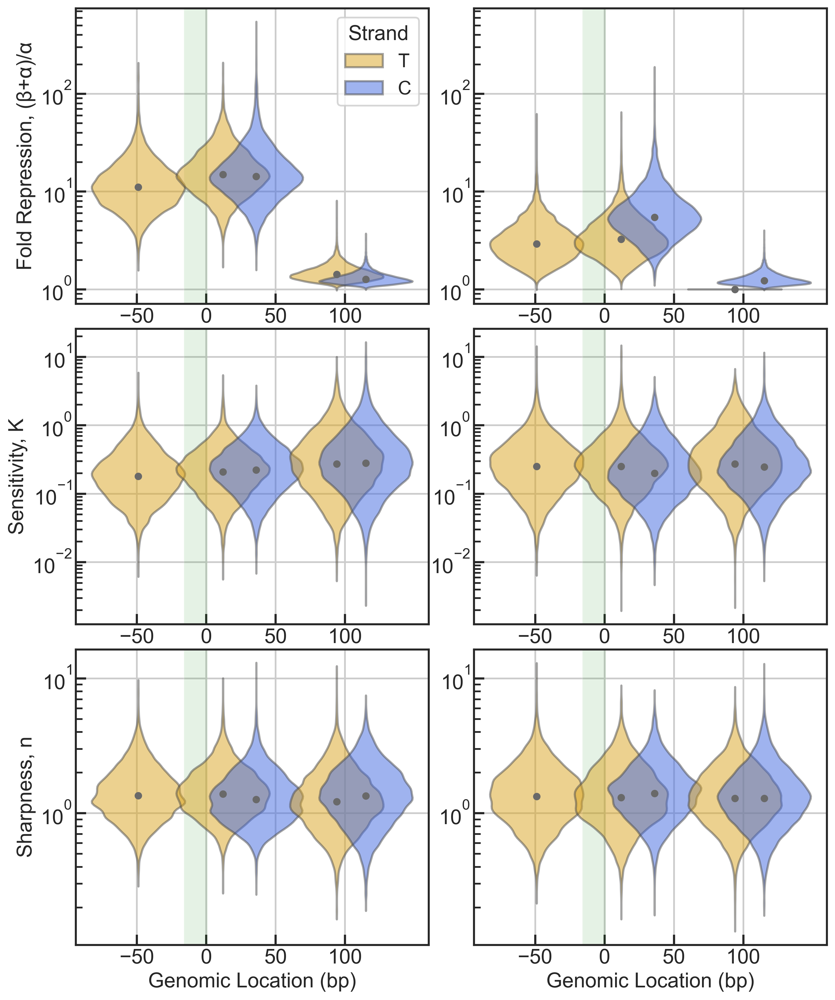

In [35]:
fig = plt.figure(figsize=(figx, figy), dpi=dpi)
ax11 = fig.add_subplot(3, 2, 1)
ax12 = fig.add_subplot(3, 2, 2, sharey=ax11)
ax21 = fig.add_subplot(3, 2, 3)
ax22 = fig.add_subplot(3, 2, 4, sharey=ax21)
ax31 = fig.add_subplot(3, 2, 5)
ax32 = fig.add_subplot(3, 2, 6, sharey=ax31)

# plot T7 promoter window
ax11.axvspan(-16,1, facecolor='g', alpha=0.1)
ax12.axvspan(-16,1, facecolor='g', alpha=0.1)
ax21.axvspan(-16,1, facecolor='g', alpha=0.1)
ax22.axvspan(-16,1, facecolor='g', alpha=0.1)
ax31.axvspan(-16,1, facecolor='g', alpha=0.1)
ax32.axvspan(-16,1, facecolor='g', alpha=0.1)

# M9 plots (left column)
M9df = params_df_D[params_df_D .Media == 'M9']
CLdf = params_df_D[params_df_D .Media == 'CL']

sns.violinplot(data=M9df,
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax11,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
              )
sns.violinplot(data=M9df,
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax21,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=M9df,
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax31,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )

# CL plots (right column)
sns.violinplot(data=CLdf,
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax12,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=CLdf,
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax22,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=CLdf,
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax32,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )

# Plot Medians
m9_reps = M9df.groupby('Location')['Fold Repression'].median()
m9_Ks = M9df.groupby('Location')['K'].median()
m9_ns = M9df.groupby('Location')['n'].median()
cl_reps = CLdf.groupby('Location')['Fold Repression'].median()
cl_Ks = CLdf.groupby('Location')['K'].median()
cl_ns = CLdf.groupby('Location')['n'].median()
m9_betas = M9df.groupby('Location')['Beta'].median()
cl_betas = CLdf.groupby('Location')['Beta'].median()



ax11.scatter(np.array(m9_reps.index), np.array(m9_reps), c='dimgrey')
ax21.scatter(np.array(m9_Ks.index), np.array(m9_Ks), c='dimgrey')
ax31.scatter(np.array(m9_ns.index), np.array(m9_ns), c='dimgrey')
ax12.scatter(np.array(cl_reps.index), np.array(cl_reps), c='dimgrey')
ax22.scatter(np.array(cl_Ks.index), np.array(cl_Ks), c='dimgrey')
ax32.scatter(np.array(cl_ns.index), np.array(cl_ns), c='dimgrey')

# ax11.axhline(1, linestyle='--', c='k')
# ax12.axhline(1, linestyle='--', c='k')

ax11.set_ylabel('Fold Repression, (β+α)/α')
ax21.set_ylabel('Sensitivity, K')
ax31.set_ylabel('Sharpness, n')
ax11.set_xlabel('')
ax12.set_xlabel('')
ax21.set_xlabel('')
ax22.set_xlabel('')
ax31.set_xlabel('Genomic Location (bp)')
ax32.set_xlabel('Genomic Location (bp)')
ax12.set_ylabel('')
ax22.set_ylabel('')
ax32.set_ylabel('')

ax11.set_xticks([-50,0,50,100])
ax21.set_xticks([-50,0,50,100])
ax31.set_xticks([-50,0,50,100])
ax12.set_xticks([-50,0,50,100])
ax22.set_xticks([-50,0,50,100])
ax32.set_xticks([-50,0,50,100])
ax11.grid(visible=True)
ax21.grid(visible=True)
ax31.grid(visible=True)
ax12.grid(visible=True)
ax22.grid(visible=True)
ax32.grid(visible=True)

# ax11.legend(title='Strand', labels=['','T','','C'])
# ax11.

handles, labels = ax11.get_legend_handles_labels()
ax11.legend(title='Strand', handles=handles, labels=['T','C'])

plt.tight_layout(pad=0.1)
plt.savefig('./figs/20251204_DP_params_all.pdf')
plt.show()

In [36]:
print(np.array(m9_ns))
print(np.array(cl_ns))
print()
print(np.array(m9_Ks))
print(max(m9_Ks)/min(m9_Ks))
print(np.array(cl_Ks))
print(max(cl_Ks)/min(cl_Ks))
print()
print(np.array(m9_betas))
print(np.array(cl_betas))
print(stats.gmean(m9_betas)/stats.gmean(cl_betas))
print()
print(np.array(m9_reps))

[1.35178939 1.39061107 1.26248854 1.2164283  1.34679421]
[1.33257413 1.30627125 1.4044998  1.28849728 1.29083979]

[0.18001685 0.2092905  0.22286835 0.27368516 0.28007287]
1.555814782491727
[0.25180721 0.2503887  0.20062362 0.27447384 0.24639719]
1.368103336638507

[325491.49263753 308943.43323357 340942.29397645 113878.31997985
  56369.53161739]
[2.22854628e+03 1.09804792e+03 2.03651148e+03 1.33873031e-06
 7.90251652e+02]
8396.906722355188

[11.10325513 15.00333334 14.33339142  1.42200842  1.26439588]


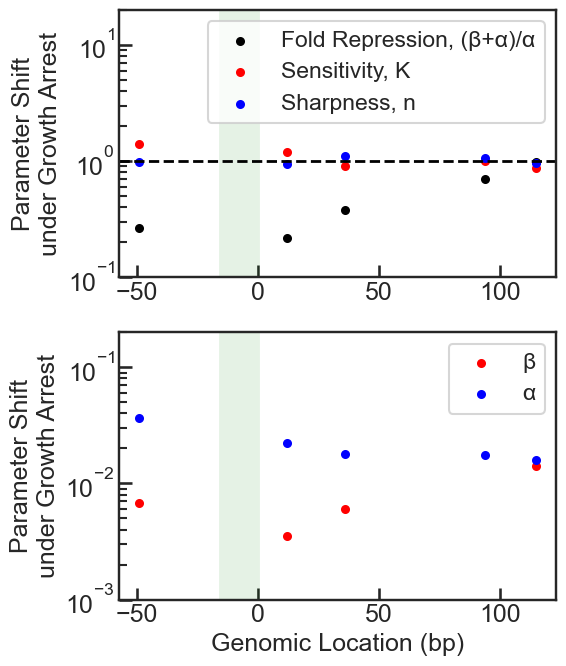

In [37]:
m9_FCs = M9df.groupby('Location')['Fold Repression'].median()
m9_betas = M9df.groupby('Location')['Beta'].median()
m9_alphas = M9df.groupby('Location')['Alpha'].median()
m9_Ks = M9df.groupby('Location')['K'].median()
m9_ns = M9df.groupby('Location')['n'].median()
cl_FCs = CLdf.groupby('Location')['Fold Repression'].median()
cl_betas = CLdf.groupby('Location')['Beta'].median()
cl_alphas = CLdf.groupby('Location')['Alpha'].median()
cl_Ks = CLdf.groupby('Location')['K'].median()
cl_ns = CLdf.groupby('Location')['n'].median()

# calculate delta directly as ratio of medians
delta_FCs = cl_FCs/m9_FCs
delta_Ks = cl_Ks/m9_Ks
delta_ns = cl_ns/m9_ns
delta_betas = cl_betas/m9_betas
delta_alphas = cl_alphas/m9_alphas

fig, ax = plt.subplots(2, 1, figsize=(6,7))
ax[0].axvspan(-16,1, facecolor='g', alpha=0.1)
ax[0].axhline(1, c='k', linestyle='--', lw=2)
ax[0].scatter(np.array(delta_FCs.index), np.array(delta_FCs), label='Fold Repression, (β+α)/α', c='k')
ax[0].scatter(np.array(delta_Ks.index), np.array(delta_Ks), label='Sensitivity, K', c='r')
ax[0].scatter(np.array(delta_ns.index), np.array(delta_ns), label='Sharpness, n', c='b')
ax[0].set_yscale('log')
ax[0].set_ylim((1e-1,2e1))
ax[0].legend()
ax[0].set_ylabel('Parameter Shift\nunder Growth Arrest')

ax[1].axvspan(-16,1, facecolor='g', alpha=0.1)
# ax[1].axhline(1, c='k', linestyle='--', lw=2)
ax[1].scatter(np.array(delta_betas.index), np.array(delta_betas), label='β', c='r')
ax[1].scatter(np.array(delta_alphas.index), np.array(delta_alphas), label='α', c='b')
ax[1].set_yscale('log')
ax[1].set_ylim((1e-3,2e-1))
ax[1].legend()
ax[1].set_xlabel('Genomic Location (bp)')
ax[1].set_ylabel('Parameter Shift\nunder Growth Arrest')
plt.tight_layout()
plt.savefig('./figs/param_shift_fusion.pdf')
plt.show()



In [38]:
delta_Ks = np.array(delta_Ks)
delta_FCs = np.array(delta_FCs)
delta_ns = np.array(delta_ns)
delta_betas = np.array(delta_betas)
delta_alphas = np.array(delta_alphas)

# delete the gate that didn't repress
delta_Ks = np.delete(delta_Ks, 3)
delta_FCs = np.delete(delta_FCs, 3)
delta_ns = np.delete(delta_ns, 3)
delta_betas = np.delete(delta_betas, 3)
delta_alphas = np.delete(delta_alphas, 3)

In [39]:

print(delta_Ks)
print(stats.gmean(delta_Ks))
print()
print(delta_FCs)
print(1/stats.gmean(delta_FCs))
print()
print(delta_ns)
print(1/delta_ns)
print(1/stats.gmean(delta_ns))
print()
print(1/stats.gmean(delta_betas))
print(1/stats.gmean(delta_alphas))

[1.39879801 1.19636917 0.90018889 0.87976101]
1.0729503971720367

[0.26352681 0.21746194 0.38117655 0.97426278]
2.6181674237881403

[0.98578532 0.93935053 1.11248519 0.95845362]
[1.01441965 1.06456532 0.89888837 1.0433473 ]
1.0031852929753826

148.83743338734416
45.62686018489168


Now PhlF data

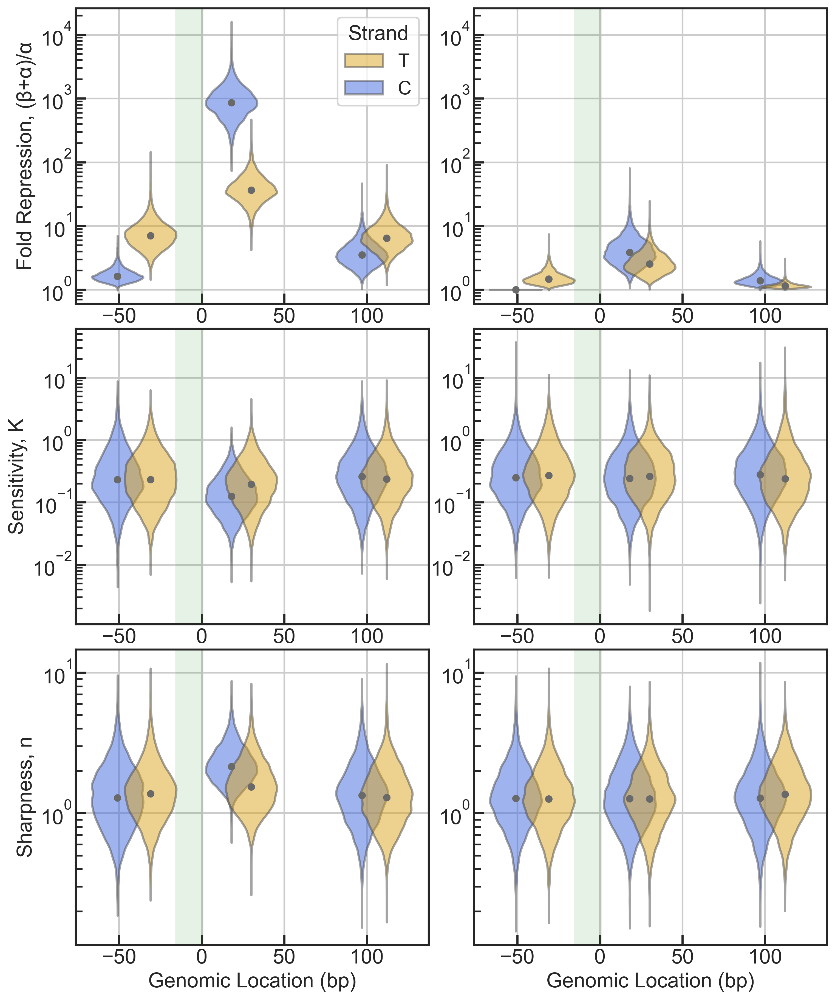

In [40]:
fig = plt.figure(figsize=(figx, figy), dpi=dpi)
ax11 = fig.add_subplot(3, 2, 1)
ax12 = fig.add_subplot(3, 2, 2, sharey=ax11)
ax21 = fig.add_subplot(3, 2, 3)
ax22 = fig.add_subplot(3, 2, 4, sharey=ax21)
ax31 = fig.add_subplot(3, 2, 5)
ax32 = fig.add_subplot(3, 2, 6, sharey=ax31)

# plot T7 promoter window
ax11.axvspan(-16,1, facecolor='g', alpha=0.1)
ax12.axvspan(-16,1, facecolor='g', alpha=0.1)
ax21.axvspan(-16,1, facecolor='g', alpha=0.1)
ax22.axvspan(-16,1, facecolor='g', alpha=0.1)
ax31.axvspan(-16,1, facecolor='g', alpha=0.1)
ax32.axvspan(-16,1, facecolor='g', alpha=0.1)

# M9 plots (left column)
M9df = params_df_P[params_df_P .Media == 'M9']
CLdf = params_df_P[params_df_P .Media == 'CL']

sns.violinplot(data=M9df,
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax11,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
              )
sns.violinplot(data=M9df,
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax21,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=M9df,
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax31,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )

# CL plots (right column)
sns.violinplot(data=CLdf,
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax12,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=CLdf,
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax22,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=CLdf,
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax32,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )

# Plot Medians
m9_reps = M9df.groupby('Location')['Fold Repression'].median()
m9_Ks = M9df.groupby('Location')['K'].median()
m9_ns = M9df.groupby('Location')['n'].median()
cl_reps = CLdf.groupby('Location')['Fold Repression'].median()
cl_Ks = CLdf.groupby('Location')['K'].median()
cl_ns = CLdf.groupby('Location')['n'].median()
m9_betas = M9df.groupby('Location')['Beta'].median()
cl_betas = CLdf.groupby('Location')['Beta'].median()

ax11.scatter(np.array(m9_reps.index), np.array(m9_reps), c='dimgrey')
ax21.scatter(np.array(m9_Ks.index), np.array(m9_Ks), c='dimgrey')
ax31.scatter(np.array(m9_ns.index), np.array(m9_ns), c='dimgrey')
ax12.scatter(np.array(cl_reps.index), np.array(cl_reps), c='dimgrey')
ax22.scatter(np.array(cl_Ks.index), np.array(cl_Ks), c='dimgrey')
ax32.scatter(np.array(cl_ns.index), np.array(cl_ns), c='dimgrey')

# ax11.axhline(1, linestyle='--', c='k')
# ax12.axhline(1, linestyle='--', c='k')

ax11.set_ylabel('Fold Repression, (β+α)/α')
ax21.set_ylabel('Sensitivity, K')
ax31.set_ylabel('Sharpness, n')
ax11.set_xlabel('')
ax12.set_xlabel('')
ax21.set_xlabel('')
ax22.set_xlabel('')
ax31.set_xlabel('Genomic Location (bp)')
ax32.set_xlabel('Genomic Location (bp)')
ax12.set_ylabel('')
ax22.set_ylabel('')
ax32.set_ylabel('')

ax11.set_xticks([-50,0,50,100])
ax21.set_xticks([-50,0,50,100])
ax31.set_xticks([-50,0,50,100])
ax12.set_xticks([-50,0,50,100])
ax22.set_xticks([-50,0,50,100])
ax32.set_xticks([-50,0,50,100])
ax11.grid(visible=True)
ax21.grid(visible=True)
ax31.grid(visible=True)
ax12.grid(visible=True)
ax22.grid(visible=True)
ax32.grid(visible=True)

# ax11.legend(title='Strand', labels=['','T','','C'])
# ax11.

handles, labels = ax11.get_legend_handles_labels()
ax11.legend(title='Strand', handles=handles, labels=['T','C'])

plt.tight_layout(pad=0.1)
plt.savefig('./figs/20251204_P_params_all.pdf')
plt.show()

In [41]:
print(np.array(m9_ns))
print(np.array(cl_ns))
print()
print(np.array(m9_Ks))
print(max(m9_Ks)/min(m9_Ks))
print(np.array(cl_Ks))
print(max(cl_Ks)/min(cl_Ks))
print()
print(np.array(m9_betas))
print(np.array(cl_betas))
print(stats.gmean(m9_betas[1:])/stats.gmean(cl_betas[1:]))

[1.28557196 1.37605243 2.14969834 1.53962163 1.34123695 1.2927564 ]
[1.27617938 1.26760169 1.27211114 1.26299364 1.28190696 1.3623327 ]

[0.23176012 0.23244767 0.12498028 0.19654061 0.26033721 0.23758167]
2.0830263145889023
[0.25012042 0.2712536  0.24280388 0.26342415 0.28006412 0.24004843]
1.1666984225263957

[139675.38850502 319636.91674051 342862.69396244 291752.02016461
 251521.38776251 312353.82208059]
[1.33331079e-06 1.01455797e+03 1.40450502e+03 1.76214039e+03
 1.63205448e+03 5.87776030e+02]
253.30579023810057


In [42]:
print(np.array(m9_reps))

[  1.63595412   7.06819386 864.75722089  36.64541203   3.53048574
   6.46429614]


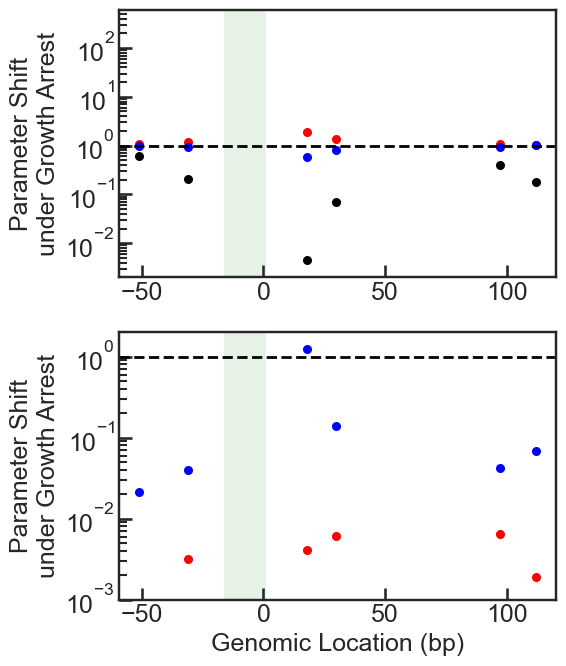

In [43]:
m9_FCs = M9df.groupby('Location')['Fold Repression'].median()
m9_betas = M9df.groupby('Location')['Beta'].median()
m9_alphas = M9df.groupby('Location')['Alpha'].median()
m9_Ks = M9df.groupby('Location')['K'].median()
m9_ns = M9df.groupby('Location')['n'].median()
cl_FCs = CLdf.groupby('Location')['Fold Repression'].median()
cl_betas = CLdf.groupby('Location')['Beta'].median()
cl_alphas = CLdf.groupby('Location')['Alpha'].median()
cl_Ks = CLdf.groupby('Location')['K'].median()
cl_ns = CLdf.groupby('Location')['n'].median()

# calculate delta directly as ratio of medians
delta_FCs = cl_FCs/m9_FCs
delta_Ks = cl_Ks/m9_Ks
delta_ns = cl_ns/m9_ns
delta_betas = cl_betas/m9_betas
delta_alphas = cl_alphas/m9_alphas

fig, ax = plt.subplots(2, 1, figsize=(6,7))
ax[0].axvspan(-16,1, facecolor='g', alpha=0.1)
ax[0].axhline(1, c='k', linestyle='--', lw=2)
ax[0].scatter(np.array(delta_FCs.index), np.array(delta_FCs), label='Fold Repression, (β+α)/α', c='k')
ax[0].scatter(np.array(delta_Ks.index), np.array(delta_Ks), label='Sensitivity, K', c='r')
ax[0].scatter(np.array(delta_ns.index), np.array(delta_ns), label='Sharpness, n', c='b')
ax[0].set_yscale('log')
ax[0].set_ylim((2e-3,6e2))
# ax[0].legend()
ax[0].set_ylabel('Parameter Shift\nunder Growth Arrest')

ax[1].axvspan(-16,1, facecolor='g', alpha=0.1)
ax[1].axhline(1, c='k', linestyle='--', lw=2)
ax[1].scatter(np.array(delta_betas.index), np.array(delta_betas), label='β', c='r')
ax[1].scatter(np.array(delta_alphas.index), np.array(delta_alphas), label='α', c='b')
ax[1].set_yscale('log')
ax[1].set_ylim((1e-3,2e0))
# ax[1].legend()
ax[1].set_xlabel('Genomic Location (bp)')
ax[1].set_ylabel('Parameter Shift\nunder Growth Arrest')
plt.tight_layout()
plt.savefig('./figs/param_shift_PhlF.pdf')
plt.show()



In [32]:
delta_Ks = np.array(delta_Ks)
delta_FCs = np.array(delta_FCs)
delta_ns = np.array(delta_ns)
delta_betas = np.array(delta_betas)
delta_alphas = np.array(delta_alphas)

# delete the gate that didn't repress
delta_Ks = np.delete(delta_Ks, 0)
delta_FCs = np.delete(delta_FCs, 0)
delta_ns = np.delete(delta_ns, 0)
delta_betas = np.delete(delta_betas, 0)
delta_alphas = np.delete(delta_alphas, 0)

In [33]:

print(delta_Ks)
print(stats.gmean(delta_Ks))
print()
print(delta_FCs)
print(1/stats.gmean(delta_FCs))
print()
print(delta_ns)
print(1/delta_ns)
print(1/stats.gmean(delta_ns))
print()
print(1/stats.gmean(delta_betas))
print(1/stats.gmean(delta_alphas))

[1.16694476 1.94273758 1.34030395 1.07577446 1.01038278]
1.269915958424382

[0.20874072 0.00445365 0.06930028 0.39384207 0.17800747]
11.722931235300038

[0.92118706 0.59176263 0.82032729 0.95576472 1.05382012]
[1.08555585 1.68986677 1.21902564 1.0462826  0.94892856]
1.1729513491948633

253.30579023810105
8.703828703285998


dCas9:PhlF


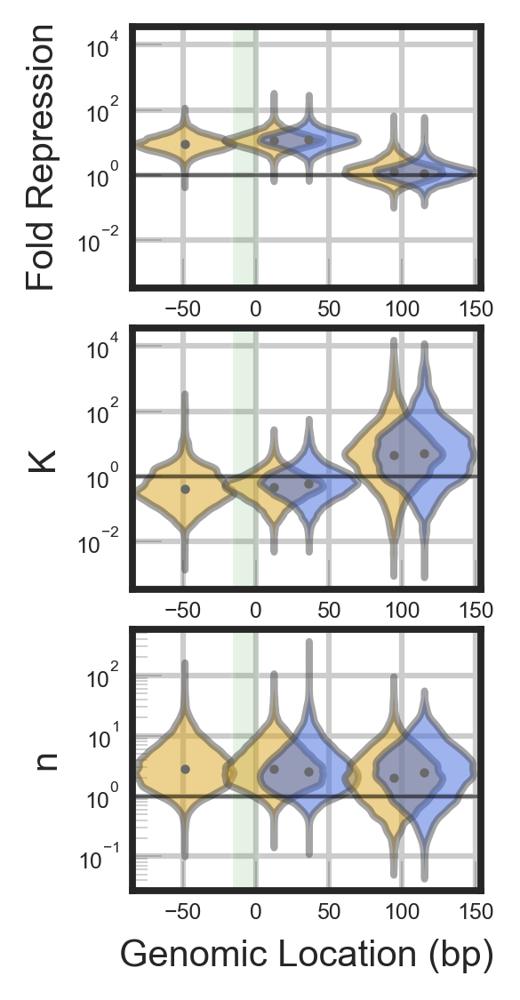

In [178]:
print('dCas9:PhlF')

fig = plt.figure(figsize=(figx, figy), dpi=300)
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2, sharey=ax1)
ax3 = fig.add_subplot(3, 1, 3)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=params_df_D[params_df_D .Media == 'M9'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_D[params_df_D .Media == 'M9'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_D[params_df_D .Media == 'M9'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
               # inner_kws=dict(linestyle='-',linewidth=1),
              )
# plot medians
m9_foldreps = params_df_D[params_df_D.Media=='M9'].groupby('Location')['Fold Repression'].median()
m9_Ks = params_df_D[params_df_D.Media=='M9'].groupby('Location')['K'].median()
m9_ns = params_df_D[params_df_D.Media=='M9'].groupby('Location')['n'].median()
ax1.scatter(np.array(m9_foldreps.index), np.array(m9_foldreps), c='dimgrey')
ax2.scatter(np.array(m9_Ks.index), np.array(m9_Ks), c='dimgrey')
ax3.scatter(np.array(m9_ns.index), np.array(m9_ns), c='dimgrey')


ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('Fold Repression')
ax2.set_ylabel('K')
ax3.set_ylabel('n')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
# ax3.legend(loc='lower right', title='Orientation', fontsize=6, title_fontsize=6)
ax1.grid()
ax2.grid()
ax3.grid()
ax1.set_xlim((xmin,xmax))
ax2.set_xlim((xmin,xmax))
ax3.set_xlim((xmin,xmax))

# # double-check the width of distributions is correct
# ax1.axvline(-49, c='k', linestyle='--')
# ax1.axvline(-49-33, c='k', linestyle='--')
# ax1.axvline(-49+33, c='k', linestyle='--')
plt.tight_layout(pad=0.1)
plt.savefig('./figs/20251204_DP_M9.png')
plt.show()

dCas9:PhlF


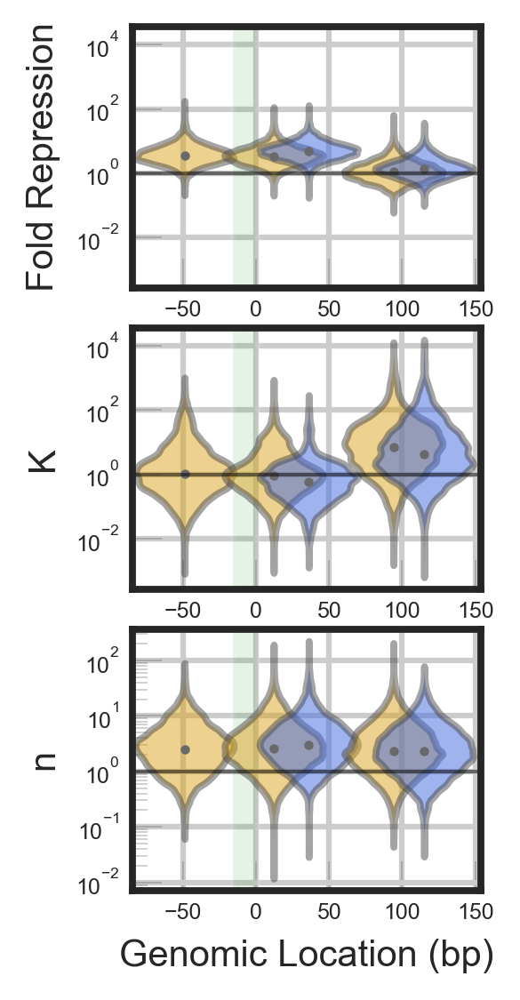

In [179]:
print('dCas9:PhlF')

fig = plt.figure(figsize=(figx, figy), dpi=300)
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2, sharey=ax1)
ax3 = fig.add_subplot(3, 1, 3)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=params_df_D[params_df_D .Media == 'CL'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_D[params_df_D .Media == 'CL'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_D[params_df_D .Media == 'CL'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
               # inner_kws=dict(linestyle='-',linewidth=1),
              )
# plot medians
cl_foldreps = params_df_D[params_df_D.Media=='CL'].groupby('Location')['Fold Repression'].median()
cl_Ks = params_df_D[params_df_D.Media=='CL'].groupby('Location')['K'].median()
cl_ns = params_df_D[params_df_D.Media=='CL'].groupby('Location')['n'].median()
ax1.scatter(np.array(cl_foldreps.index), np.array(cl_foldreps), c='dimgrey')
ax2.scatter(np.array(cl_Ks.index), np.array(cl_Ks), c='dimgrey')
ax3.scatter(np.array(cl_ns.index), np.array(cl_ns), c='dimgrey')


ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('Fold Repression')
ax2.set_ylabel('K')
ax3.set_ylabel('n')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
# ax3.legend(loc='lower right', title='Orientation', fontsize=6, title_fontsize=6)
ax1.grid()
ax2.grid()
ax3.grid()
ax1.set_xlim((xmin,xmax))
ax2.set_xlim((xmin,xmax))
ax3.set_xlim((xmin,xmax))

# # double-check the width of distributions is correct
# ax1.axvline(-49, c='k', linestyle='--')
# ax1.axvline(-49-33, c='k', linestyle='--')
# ax1.axvline(-49+33, c='k', linestyle='--')
plt.tight_layout(pad=0.1)
plt.savefig('./figs/20251204_DP_CL.png')
plt.show()

dCas9:PhlF


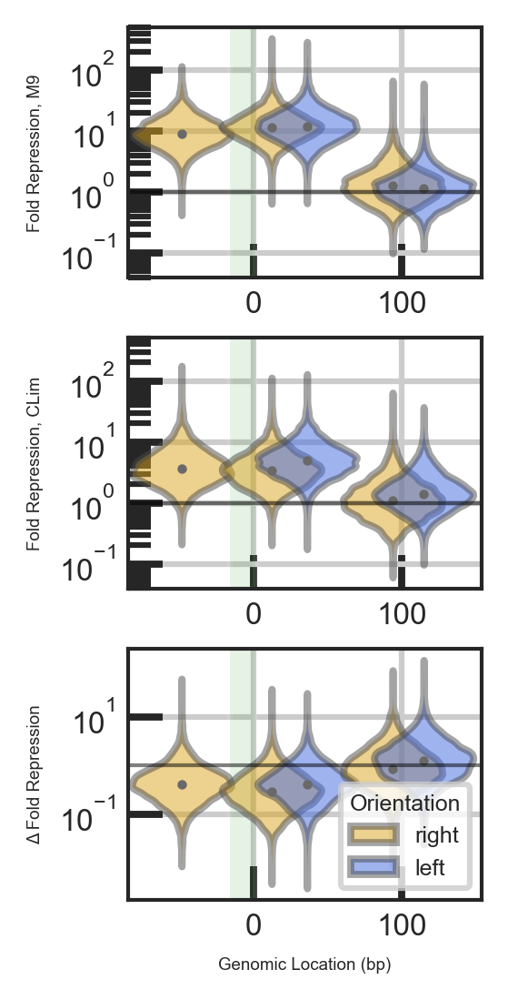

In [122]:
print('dCas9:PhlF')

fig = plt.figure(figsize=(figx, figy), dpi=300)
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2, sharey=ax1)
ax3 = fig.add_subplot(3, 1, 3)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=params_df_D[params_df_D .Media == 'M9'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_D[params_df_D .Media == 'CL'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_D[params_df_D .Media == 'Delta'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
               # inner_kws=dict(linestyle='-',linewidth=1),
              )
# plot medians
m9_medians = params_df_D[params_df_D.Media=='M9'].groupby('Location')['Fold Repression'].median()
cl_medians = params_df_D[params_df_D.Media=='CL'].groupby('Location')['Fold Repression'].median()
delta_medians = params_df_D[params_df_D .Media=='Delta'].groupby('Location')['Fold Repression'].median()
ax1.scatter(np.array(m9_medians.index), np.array(m9_medians), c='dimgrey')
ax2.scatter(np.array(cl_medians.index), np.array(cl_medians), c='dimgrey')
ax3.scatter(np.array(delta_medians.index), np.array(delta_medians), c='dimgrey')


ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('Fold Repression, M9')
ax2.set_ylabel('Fold Repression, CLim')
ax3.set_ylabel('Δ Fold Repression')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
ax3.legend(loc='lower right', title='Orientation', fontsize=6, title_fontsize=6)
ax1.grid()
ax2.grid()
ax3.grid()
ax1.set_xlim((xmin,xmax))
ax2.set_xlim((xmin,xmax))
ax3.set_xlim((xmin,xmax))

# # double-check the width of distributions is correct
# ax1.axvline(-49, c='k', linestyle='--')
# ax1.axvline(-49-33, c='k', linestyle='--')
# ax1.axvline(-49+33, c='k', linestyle='--')
plt.tight_layout()
plt.savefig('./figs/20251204_DP_Repression.png')
plt.show()

dCas9:PhlF


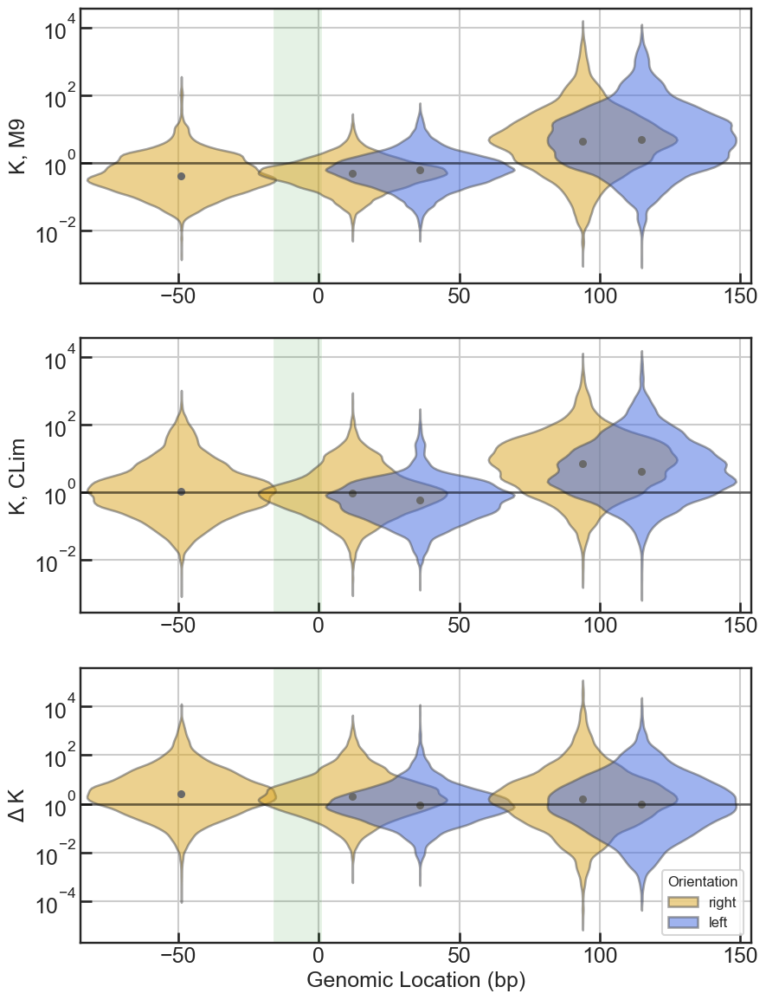

In [87]:
print('dCas9:PhlF')

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2, sharey=ax1)
ax3 = fig.add_subplot(3, 1, 3)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=params_df_D[params_df_D .Media == 'M9'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_D[params_df_D .Media == 'CL'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_D[params_df_D .Media == 'Delta'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
               # inner_kws=dict(linestyle='-',linewidth=1),
              )
# plot medians
m9_medians = params_df_D[params_df_D.Media=='M9'].groupby('Location')['K'].median()
cl_medians = params_df_D[params_df_D.Media=='CL'].groupby('Location')['K'].median()
delta_medians = params_df_D[params_df_D .Media=='Delta'].groupby('Location')['K'].median()
ax1.scatter(np.array(m9_medians.index), np.array(m9_medians), c='dimgrey')
ax2.scatter(np.array(cl_medians.index), np.array(cl_medians), c='dimgrey')
ax3.scatter(np.array(delta_medians.index), np.array(delta_medians), c='dimgrey')


ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('K, M9')
ax2.set_ylabel('K, CLim')
ax3.set_ylabel('Δ K')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
ax3.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
ax3.grid()
ax1.set_xlim((xmin,xmax))
ax2.set_xlim((xmin,xmax))
ax3.set_xlim((xmin,xmax))
plt.show()

dCas9:PhlF


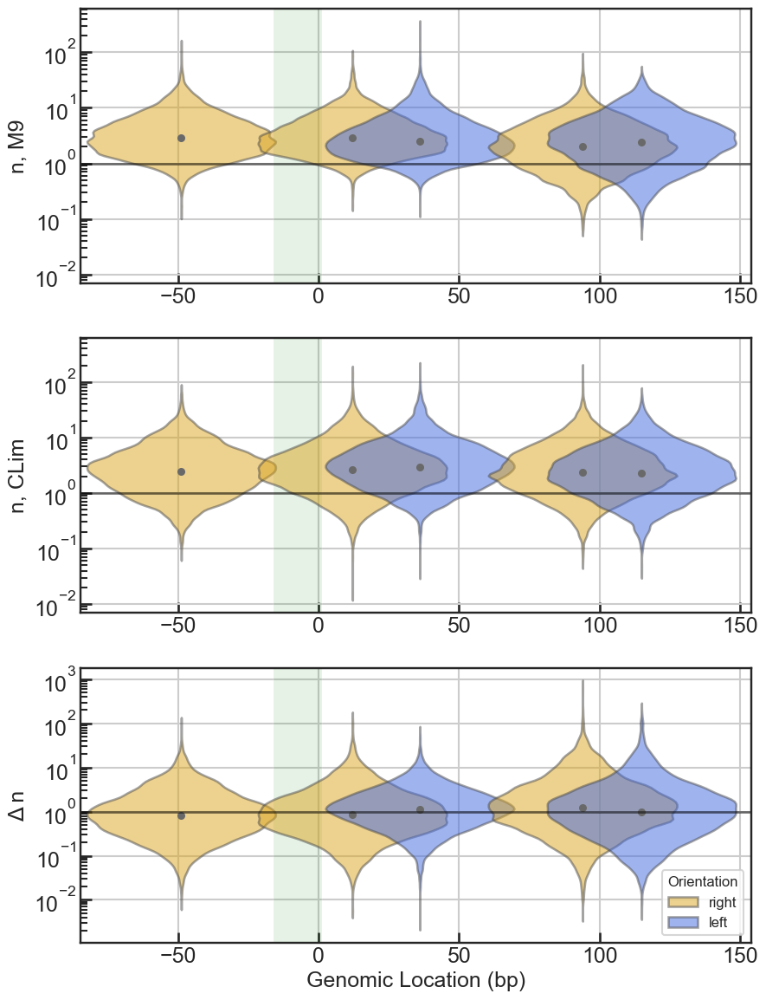

In [88]:
print('dCas9:PhlF')

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2, sharey=ax1)
ax3 = fig.add_subplot(3, 1, 3)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=params_df_D[params_df_D .Media == 'M9'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_D[params_df_D .Media == 'CL'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_D[params_df_D .Media == 'Delta'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_DP,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
               # inner_kws=dict(linestyle='-',linewidth=1),
              )
# plot medians
m9_medians = params_df_D[params_df_D.Media=='M9'].groupby('Location')['n'].median()
cl_medians = params_df_D[params_df_D.Media=='CL'].groupby('Location')['n'].median()
delta_medians = params_df_D[params_df_D .Media=='Delta'].groupby('Location')['n'].median()
ax1.scatter(np.array(m9_medians.index), np.array(m9_medians), c='dimgrey')
ax2.scatter(np.array(cl_medians.index), np.array(cl_medians), c='dimgrey')
ax3.scatter(np.array(delta_medians.index), np.array(delta_medians), c='dimgrey')


ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('n, M9')
ax2.set_ylabel('n, CLim')
ax3.set_ylabel('Δ n')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
ax3.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
ax3.grid()
ax1.set_xlim((xmin,xmax))
ax2.set_xlim((xmin,xmax))
ax3.set_xlim((xmin,xmax))
plt.show()

### Plot parameters (PhlF)


PhlF


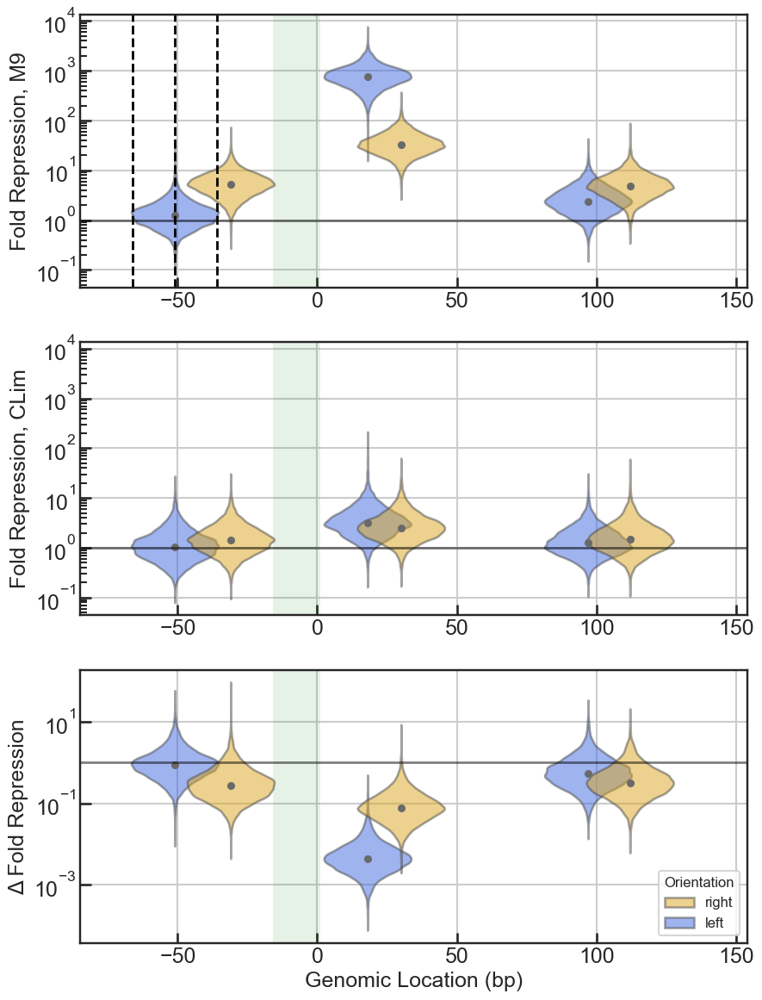

In [77]:
print('PhlF')

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2, sharey=ax1)
ax3 = fig.add_subplot(3, 1, 3)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=params_df_P[params_df_P .Media == 'M9'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_P[params_df_P .Media == 'CL'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_P[params_df_P .Media == 'Delta'],
               x='Location', y='Fold Repression', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
               # inner_kws=dict(linestyle='-',linewidth=1),
              )
# plot medians
m9_medians = params_df_P[params_df_P.Media=='M9'].groupby('Location')['Fold Repression'].median()
cl_medians = params_df_P[params_df_P.Media=='CL'].groupby('Location')['Fold Repression'].median()
delta_medians = params_df_P[params_df_P .Media=='Delta'].groupby('Location')['Fold Repression'].median()
ax1.scatter(np.array(m9_medians.index), np.array(m9_medians), c='dimgrey')
ax2.scatter(np.array(cl_medians.index), np.array(cl_medians), c='dimgrey')
ax3.scatter(np.array(delta_medians.index), np.array(delta_medians), c='dimgrey')


ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('Fold Repression, M9')
ax2.set_ylabel('Fold Repression, CLim')
ax3.set_ylabel('Δ Fold Repression')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
ax3.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
ax3.grid()
ax1.set_xlim((xmin,xmax))
ax2.set_xlim((xmin,xmax))
ax3.set_xlim((xmin,xmax))

# # check that violin width is correct
# ax1.axvline(-51, linestyle='--', c='k')
# ax1.axvline(-51-15, linestyle='--', c='k')
# ax1.axvline(-51+15, linestyle='--', c='k')

plt.show()

PhlF


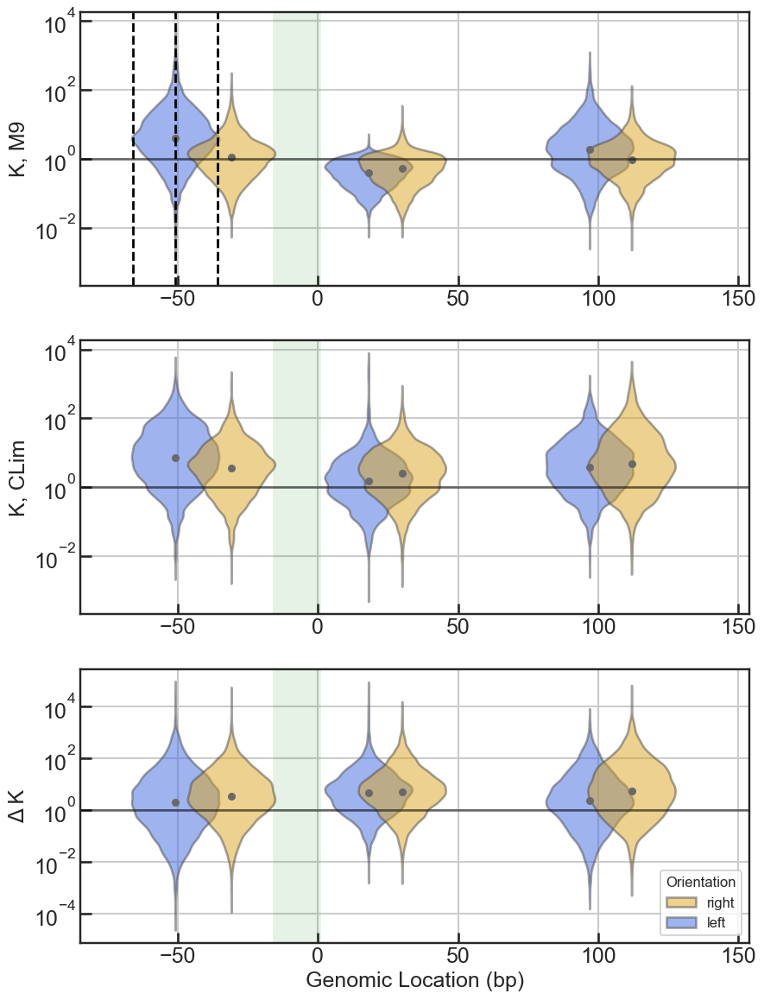

In [76]:
print('PhlF')

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2, sharey=ax1)
ax3 = fig.add_subplot(3, 1, 3)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=params_df_P[params_df_P .Media == 'M9'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_P[params_df_P .Media == 'CL'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_P[params_df_P .Media == 'Delta'],
               x='Location', y='K', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
               # inner_kws=dict(linestyle='-',linewidth=1),
              )
# plot medians
m9_medians = params_df_P[params_df_P.Media=='M9'].groupby('Location')['K'].median()
cl_medians = params_df_P[params_df_P.Media=='CL'].groupby('Location')['K'].median()
delta_medians = params_df_P[params_df_P .Media=='Delta'].groupby('Location')['K'].median()
ax1.scatter(np.array(m9_medians.index), np.array(m9_medians), c='dimgrey')
ax2.scatter(np.array(cl_medians.index), np.array(cl_medians), c='dimgrey')
ax3.scatter(np.array(delta_medians.index), np.array(delta_medians), c='dimgrey')


ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('K, M9')
ax2.set_ylabel('K, CLim')
ax3.set_ylabel('Δ K')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
ax3.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
ax3.grid()
ax1.set_xlim((xmin,xmax))
ax2.set_xlim((xmin,xmax))
ax3.set_xlim((xmin,xmax))

# check that violin width is correct
ax1.axvline(-51, linestyle='--', c='k')
ax1.axvline(-51-15, linestyle='--', c='k')
ax1.axvline(-51+15, linestyle='--', c='k')

plt.show()

PhlF


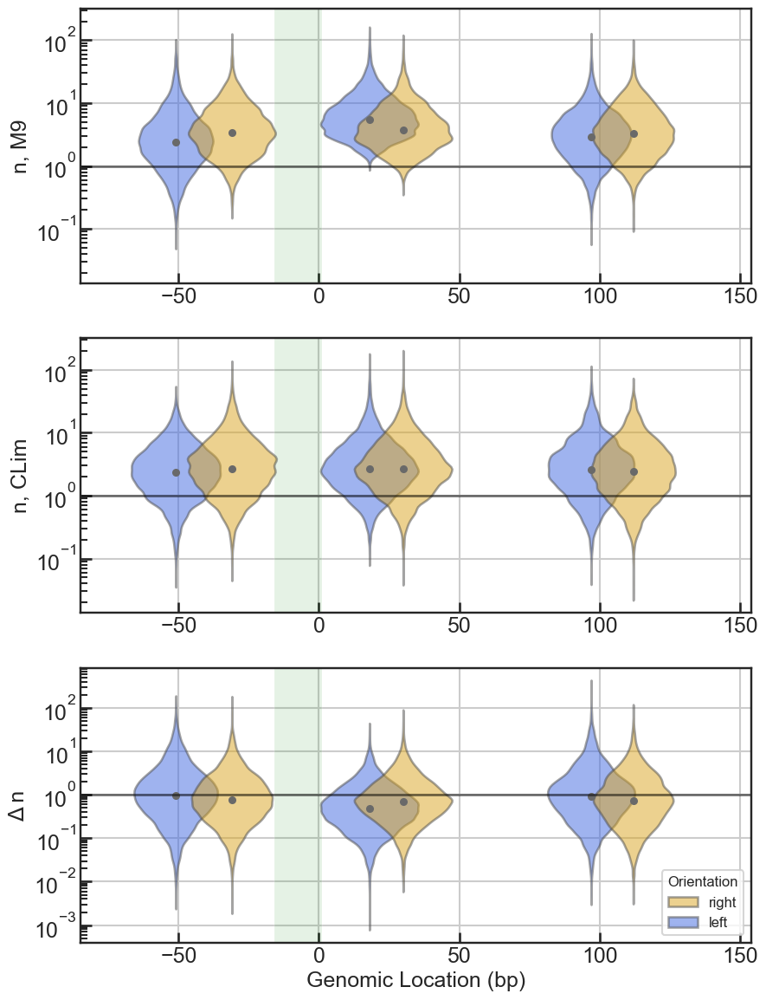

In [66]:
print('PhlF')

fig = plt.figure(figsize=(10,14))
ax1 = fig.add_subplot(3, 1, 1)
ax2 = fig.add_subplot(3, 1, 2, sharey=ax1)
ax3 = fig.add_subplot(3, 1, 3)
# Plot T7 promoter window
ax1.axvspan(-16,1, facecolor='g', alpha=0.1)
ax2.axvspan(-16,1, facecolor='g', alpha=0.1)
ax3.axvspan(-16,1, facecolor='g', alpha=0.1)

sns.violinplot(data=params_df_P[params_df_P .Media == 'M9'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               native_scale=True, ax=ax1,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_P[params_df_P .Media == 'CL'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax2,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend=False,
               scale='width',
              )
sns.violinplot(data=params_df_P[params_df_P .Media == 'Delta'],
               x='Location', y='n', hue='Orientation',
               palette=['goldenrod','royalblue'],
               # palette=['navajowhite','lavender'],
               native_scale=True, ax=ax3,
               inner=None, split=False,
               log_scale=(False,True),
               linecolor=None,
               width=vw_P,
               saturation=1,
               alpha=0.5,
               legend='brief',
               scale='width',
               # inner_kws=dict(linestyle='-',linewidth=1),
              )
# plot medians
m9_medians = params_df_P[params_df_P.Media=='M9'].groupby('Location')['n'].median()
cl_medians = params_df_P[params_df_P.Media=='CL'].groupby('Location')['n'].median()
delta_medians = params_df_P[params_df_P .Media=='Delta'].groupby('Location')['n'].median()
ax1.scatter(np.array(m9_medians.index), np.array(m9_medians), c='dimgrey')
ax2.scatter(np.array(cl_medians.index), np.array(cl_medians), c='dimgrey')
ax3.scatter(np.array(delta_medians.index), np.array(delta_medians), c='dimgrey')


ax1.axhline(1, c='k', linestyle='-', alpha=0.5)
ax2.axhline(1, c='k', linestyle='-', alpha=0.5)
ax3.axhline(1, c='k', linestyle='-', alpha=0.5)
ax1.set_ylabel('n, M9')
ax2.set_ylabel('n, CLim')
ax3.set_ylabel('Δ n')
ax1.set_xlabel('')
ax2.set_xlabel('')
ax3.set_xlabel('Genomic Location (bp)')
ax3.legend(loc='lower right', title='Orientation', fontsize=12, title_fontsize=12)
ax1.grid()
ax2.grid()
ax3.grid()
ax1.set_xlim((xmin,xmax))
ax2.set_xlim((xmin,xmax))
ax3.set_xlim((xmin,xmax))
plt.show()

# Noise Analysis

In [14]:
# make a KDE of GFP values for each experimental condition

kdes_dict_D = dict()
kdes_dict_P = dict()

for m in range(len(medias)):
    media = medias[m]
    for grna in grnas:
        for rep in reps:
            fcs_gated_dict_D = fcs_dict_ls_D[rep-1]
            fcs_gated_dict_P = fcs_dict_ls_P[rep-1]
            atcs = atcs_ls[rep-1][m]
            plot_inds = plot_inds_ls[rep-1][m]
            for a in range(1,len(atcs)): # ignore Blank values
                atc = atcs[a]

                fcs_D = fcs_gated_dict_D[media+'_'+grna+'_'+atc]
                fcs_P = fcs_gated_dict_P[media+'_'+grna+'_'+atc]

                # get KDE for DP data
                loggfps = np.log10(np.array(fcs_D[:,5]))
                loggfps = loggfps[~np.isnan(loggfps)] # remove nan values
                loggfps = loggfps[~np.isinf(loggfps)] # remove inf values

                # rescale values by median
                loggfps /= np.median(loggfps)
                
                # do a KDE of the gfp values
                kde = stats.gaussian_kde(loggfps)

                kdes_dict_D[media+'_'+grna+'_'+atc] = kde

                # get KDE for P data
                loggfps = np.log10(np.array(fcs_P[:,5]))
                loggfps = loggfps[~np.isnan(loggfps)] # remove nan values
                loggfps = loggfps[~np.isinf(loggfps)] # remove inf values

                # rescale values by median
                loggfps /= np.median(loggfps)
                
                # do a KDE of the gfp values
                kde = stats.gaussian_kde(loggfps)

                kdes_dict_P[media+'_'+grna+'_'+atc] = kde
                


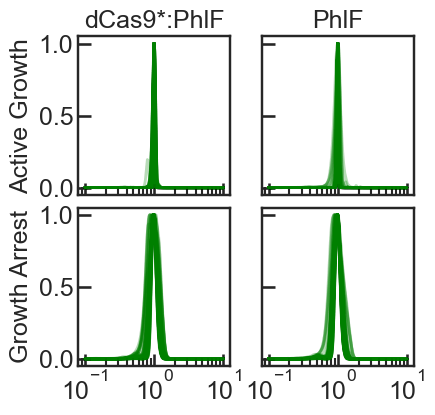

In [18]:
# Plot KDE of GFP values for each condition

xrange = np.logspace(-1,1,300)

fig, ax = plt.subplots(2,2, figsize=(4,4), sharey='row', sharex=True)

width_ls_M9_D = []
width_ls_CL_D = []
width_ls_M9_P = []
width_ls_CL_P = []

for m in range(len(medias)):
    media = medias[m]
    for grna in grnas:
        for rep in reps:
            atcs = atcs_ls[rep-1][m]            
            for a in range(1,len(atcs)):
                atc = atcs[a]
                kde_D = kdes_dict_D[media+'_'+grna+'_'+atc]
                kde_P = kdes_dict_P[media+'_'+grna+'_'+atc]
                yvals_D = kde_D(xrange)
                yvals_P = kde_P(xrange)
                yvals_D /= np.max(yvals_D)
                yvals_P /= np.max(yvals_P)

                ax[m,0].plot(xrange, yvals_D, alpha=0.1, c='g')
                ax[m,1].plot(xrange, yvals_P, alpha=0.1, c='g')

                # store x values at which KDE crosses 0.2 on the up and the down
                left_x = np.where(yvals_D > 0.2)[0][0]
                right_x = np.where(yvals_D > 0.2)[0][-1]
                width_D = xrange[right_x]/xrange[left_x]
                left_x = np.where(yvals_P > 0.2)[0][0]
                right_x = np.where(yvals_P > 0.2)[0][-1]
                width_P = xrange[right_x]/xrange[left_x]

                if media == 'M9':
                    width_ls_M9_D.append(width_D)
                    width_ls_M9_P.append(width_P)
                elif media == 'CL':
                    width_ls_CL_D.append(width_D)
                    width_ls_CL_P.append(width_P)
                else:
                    print('problem!')

ax[0,0].set_xscale('log')
ax[0,1].set_xscale('log')
ax[1,0].set_xscale('log')
ax[1,1].set_xscale('log')
ax[0,0].set_ylabel('Active Growth')
ax[1,0].set_ylabel('Growth Arrest')
ax[0,0].set_title('dCas9*:PhlF')
ax[0,1].set_title('PhlF')
# fig.supxlabel('Median-rescaled GFP')
plt.tight_layout(pad=0.1)
plt.savefig('./figs/DP_P_KDEs.pdf')
plt.show()

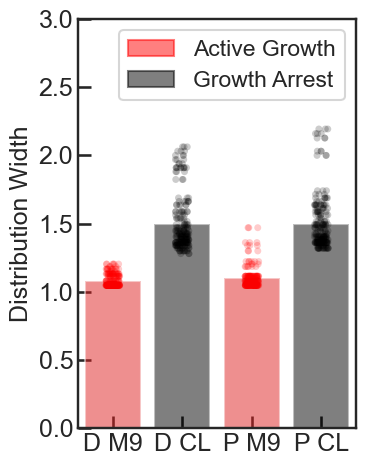

In [20]:
plt.figure(figsize=(4,5))
sns.barplot([stats.gmean(width_ls_M9_D), stats.gmean(width_ls_CL_D),
             stats.gmean(width_ls_M9_P), stats.gmean(width_ls_CL_P)],
            palette=['r','k','r','k'], alpha=0.5,
           legend='brief')
sns.stripplot([width_ls_M9_D, width_ls_CL_D, width_ls_M9_P, width_ls_CL_P],
              palette=['r','k','r','k'], alpha=0.2)
# plt.gca().set_yscale('log')
plt.gca().set_xticklabels(['D M9','D CL', 'P M9', 'P CL'])
plt.ylabel('Distribution Width')
plt.gca().set_ylim((0,3))
# plt.legend(labels=['Active Growth', 'Growth Arrest'])

patches = [mpl.patches.Patch(color='r', alpha=0.5, label='Active Growth'),
          mpl.patches.Patch(color='k', alpha=0.5, label='Growth Arrest')]
plt.legend(handles=patches)

plt.tight_layout()
plt.savefig('./figs/DP_P_Noise_Barplot.pdf')
plt.show()


In [77]:
print('Gmeans of distribution widths')
print(stats.gmean(width_ls_M9_D))
print(stats.gmean(width_ls_CL_D))
print(stats.gmean(width_ls_M9_P))
print(stats.gmean(width_ls_CL_P))
print()

print('Shift in distribution width to CL')
print(stats.gmean(width_ls_CL_D)/stats.gmean(width_ls_M9_D))
print(stats.gmean(width_ls_CL_P)/stats.gmean(width_ls_M9_P))

Gmeans of distribution widths
1.081061018911237
1.4942380218450884
1.0980965293202614
1.4977290807904633

Shift in distribution width to CL
1.3821958203154636
1.3639320777359898
